# cluster specific TF-gene activaltion
#### cluster can be cell type, niche, spatial cluster etc

1. Link peaks to marker genes for clusters and to genes in gene set
    - annotate as proximal: 100-2000bp upstream TSS 
    - annotate as distal: +/- 150kbp TSS (and not proximal)
2. Identify relevant peaks for specific cluster: differs from BA
    - test for cluster: overaccessible compared to background clusters?
3. Identify TFs for which motifs are enriched in these peaks 
    - continue with 2 analysis paths: 
        - for single clusters
        - for all clusters
4. Score local footprints
    - mean(valley) - mean(flanks)
    - standard diviation in flanks/ total number of sites with Tn5 insertions in flanks



In [41]:
plot_module_scores <- function(
  object,
  seed_genes,
  module_name = "AVN_module",
  assay_name = "RNA",
  cluster_name = "cell_type",
  test_method = c("wilcox", "t.test"),
  alternative = c("greater", "two.sided", "less"),
  p_adjust_method = "BH",
  label_type = c("stars", "p.adj"),
  show_ns = TRUE
) {
  test_method <- match.arg(test_method)
  alternative <- match.arg(alternative)
  label_type <- match.arg(label_type)

  DefaultAssay(object) <- assay_name
  score_col <- paste0(module_name, "1")

  # Keep only genes present in this object
  seed_genes_present <- intersect(seed_genes, rownames(object))
  missing_genes <- setdiff(seed_genes, seed_genes_present)

  if (length(seed_genes_present) == 0) {
    stop("None of the seed genes are present in the object.")
  }

  cat("Genes found:", length(seed_genes_present), "\n")
  if (length(missing_genes) > 0) {
    cat("Missing genes:", paste(missing_genes, collapse = ", "), "\n")
  }

  Idents(object) <- cluster_name

  # Add module score
  object <- AddModuleScore(
    object = object,
    features = list(seed_genes_present),
    name = module_name,
    assay = assay_name,
    seed = 123
  )

  # Pull data for plotting
  plot_df <- FetchData(object, vars = c(cluster_name, score_col))
  colnames(plot_df) <- c("cluster", "score")

  # Order clusters by median score
  celltype_order <- plot_df %>%
    dplyr::group_by(cluster) %>%
    dplyr::summarise(med = median(score, na.rm = TRUE), .groups = "drop") %>%
    dplyr::arrange(dplyr::desc(med)) %>%
    dplyr::pull(cluster)

  plot_df$cluster <- factor(plot_df$cluster, levels = celltype_order)

  # Per-cluster enrichment test: cluster vs all other cells
  stats_df <- lapply(levels(plot_df$cluster), function(cl) {
    x <- plot_df$score[plot_df$cluster == cl]
    y <- plot_df$score[plot_df$cluster != cl]

    test_res <- switch(
      test_method,
      wilcox = stats::wilcox.test(x, y, alternative = alternative, exact = FALSE),
      `t.test` = stats::t.test(x, y, alternative = alternative)
    )

    data.frame(
      cluster = cl,
      n_cluster = length(x),
      n_other = length(y),
      mean_cluster = mean(x, na.rm = TRUE),
      mean_other = mean(y, na.rm = TRUE),
      median_cluster = median(x, na.rm = TRUE),
      median_other = median(y, na.rm = TRUE),
      effect_mean = mean(x, na.rm = TRUE) - mean(y, na.rm = TRUE),
      effect_median = median(x, na.rm = TRUE) - median(y, na.rm = TRUE),
      p_val = test_res$p.value,
      stringsAsFactors = FALSE
    )
  }) %>%
    dplyr::bind_rows() %>%
    dplyr::mutate(
      p_adj = stats::p.adjust(p_val, method = p_adjust_method)
    )

  # Significance labels
  p_to_stars <- function(p) {
    dplyr::case_when(
      is.na(p)        ~ NA_character_,
      p <= 1e-4       ~ "****",
      p <= 1e-3       ~ "***",
      p <= 1e-2       ~ "**",
      p <= 5e-2       ~ "*",
      TRUE            ~ "ns"
    )
  }

  stats_df <- stats_df %>%
    dplyr::mutate(
      label = if (label_type == "stars") {
        p_to_stars(p_adj)
      } else {
        paste0("adj.P=", signif(p_adj, 2))
      }
    )

  if (!show_ns && label_type == "stars") {
    stats_df$label[stats_df$label == "ns"] <- ""
  }

  # Y-positions for annotation
  y_range <- diff(range(plot_df$score, na.rm = TRUE))
  if (y_range == 0) y_range <- 1

  annot_df <- plot_df %>%
    dplyr::group_by(cluster) %>%
    dplyr::summarise(y_pos = max(score, na.rm = TRUE) + 0.06 * y_range, .groups = "drop") %>%
    dplyr::left_join(stats_df, by = "cluster")

  # Plot
  p <- ggplot(plot_df, aes(x = cluster, y = score, fill = cluster)) +
    geom_violin(trim = FALSE, scale = "width", color = "grey30") +
    geom_boxplot(width = 0.15, outlier.shape = NA, alpha = 0.5, color = "white") +
    geom_text(
      data = annot_df,
      aes(x = cluster, y = y_pos, label = label),
      inherit.aes = FALSE,
      vjust = 0,
      size = 6
    ) +
    theme_classic() +
    labs(
      x = cluster_name,
      y = score_col,
      subtitle = paste0(
        "Per-cluster enrichment test: ",
        test_method,
        " (", alternative, "), p-adjust = ", p_adjust_method
      )
    ) +
    scale_y_continuous(expand = ggplot2::expansion(mult = c(0.05, 0.15))) +
    theme(
      axis.text.x = element_text(angle = 45, hjust = 1),
      legend.position = "none"
    )

  return(list(
    plot = p,
    object = object,
    stats = stats_df,
    plot_data = plot_df
  ))
}

In [17]:
coverage_plot_for_gene <- function(object, gene_name, cluster=NULL, peak_assay = "peaks", expression_assay = "RNA") {
  links <- Links(object[[peak_assay]])

  if (is.null(links) || length(links) == 0) {
    stop("No links found in assay '", peak_assay, "'.")
  }

  link_meta <- mcols(links)

  if (!"gene" %in% colnames(link_meta)) {
    stop("The Links GRanges does not contain a 'gene' metadata column.")
  }

  if (!"distancePeakStartTSS" %in% colnames(link_meta)) {
    stop("The Links GRanges does not contain a 'distancePeakStartTSS' metadata column.")
  }

  links_gene <- links[link_meta$gene == gene_name]

  if (length(links_gene) == 0) {
    stop("No peak-gene links found for gene: ", gene_name)
  }

  ann <- Annotation(object[[peak_assay]])
  ann_meta <- mcols(ann)

  if (!"gene_name" %in% colnames(ann_meta)) {
    stop("Annotation GRanges does not contain a 'gene_name' column.")
  }

  ann_gene <- ann[ann_meta$gene_name == gene_name]

  if (length(ann_gene) == 0) {
    stop("Gene not found in annotation: ", gene_name)
  }

  gene_strand <- unique(as.character(strand(ann_gene)))
  gene_strand <- gene_strand[gene_strand != "*"][1]

  if (is.na(gene_strand) || length(gene_strand) == 0) {
    stop("Could not determine strand for gene: ", gene_name)
  }

  dists <- mcols(links_gene)$distancePeakStartTSS

  if (gene_strand == "+") {
    left_extend  <- abs(min(c(dists, 0), na.rm = TRUE))
    right_extend <- abs(max(c(dists, 0), na.rm = TRUE))
  } else {
    left_extend  <- abs(max(c(dists, 0), na.rm = TRUE))
    right_extend <- abs(min(c(dists, 0), na.rm = TRUE))
  }

  CoveragePlot(
    object = object,
    region = gene_name,
    features = gene_name,
    expression.assay = expression_assay,
    extend.upstream = left_extend,
    extend.downstream = right_extend,
    annotation = TRUE,
    peaks = TRUE,
    #tile = TRUE,
    links = TRUE,
    idents = cluster
  )
}

In [4]:
# combine priorGRN with seed genes and extrend by relevant marker genes for cluster
gene_name_2_gene_id <- read.csv("/nfs/data3/mopitas/mapra/TFnets/genename2EID.csv")

linking_peaks_for_module_cluster <- function(object, 
                                            seed_genes, 
                                            priorGRN, 
                                            cluster,
                                            gene_name_2_gene_id,
                                            log2FC_threshold = 1,
                                            p_adj_threshold = 0.05,
                                            genome=BSgenome.Hsapiens.UCSC.hg38,
                                            frag_path=NULL, add_markers=FALSE) {
    priorGRN <- priorGRN %>%
        rename(
            gene = gene_name,
            EID = Gene
        )

    if (add_markers) {
        marker_genes_cluster <- object@misc$markers.annotated[
            !is.na(object@misc$markers.annotated[["cluster"]]) &
            !is.na(object@misc$markers.annotated[["p_val_adj"]]) &
            !is.na(object@misc$markers.annotated[["avg_log2FC"]]) &
            object@misc$markers.annotated[["avg_log2FC"]] > log2FC_threshold &
            object@misc$markers.annotated[["p_val_adj"]] < p_adj_threshold &
            object@misc$markers.annotated[["cluster"]] == cluster,
            ,
            drop = FALSE
        ]
        print(typeof(marker_genes_cluster))
        print(class(marker_genes_cluster))

        priorGRN_ext <- gene_name_2_gene_id[gene_name_2_gene_id[["gene_name"]] %in% marker_genes_cluster, , drop = FALSE] %>%
        rename(
            gene = gene_name,
            EID = gene_id
        )
        priorGRN <- bind_rows(priorGRN, priorGRN_ext)
    
    } 

    print(typeof(priorGRN))
    print(class(priorGRN))
    print(head(priorGRN))

    seeds <- gene_name_2_gene_id[gene_name_2_gene_id[["gene_name"]] %in% seed_genes, , drop = FALSE] %>%
        rename(
            gene = gene_name,
            EID = gene_id
        )
    
    object<-linking_peaks(object, priorGRN, seeds=seeds, genome=genome)
    if (!is.null(frag_path)) {
        frag_obj <- CreateFragmentObject(
            path = frag_path,
            cells = colnames(object)   # restrict to cells in this object
        )
        object[["peaks"]]@fragments <- list(frag_obj)
    }
    

    # plot links
    p <- plot_links_per_gene(object)
    return(list(object = object, plot_links = p, priorGRN=priorGRN, seeds=seeds))

}
   

In [1]:
library(parallel)
library(GenomicFeatures)
set.seed(1234)
library(repr)
library(motifmatchr)
library(fastmatch)
library(qlcMatrix)

library(ensembldb)
library(EnsDb.Hsapiens.v86)
library(AnnotationFilter)

library(Signac)
library(Seurat)
library(JASPAR2024)
library(TFBSTools)
library(BSgenome.Hsapiens.UCSC.hg38)
library(patchwork)
library(ggplot2)
library(Matrix)
library(zoo)
library(tidyr)

source("../multiome_methods/function_calls.r")
source("../multiome_methods/peak_gene_relations.r")
source("../multiome_methods/binding_site_identification.r")
source("../multiome_methods/binding_site_identification_parallel.r")
source("../multiome_methods/TF_activity.r")
source("../multiome_methods/signac_utils.r")

library(dplyr)

library(ggplot2)
library(hexbin)
library(RColorBrewer)
library(cowplot)
library(gridExtra)
library(ggExtra)

library(pheatmap)
library(purrr)
library(data.table)
library(Rsamtools)
library(stringi)


Loading required package: BiocGenerics

Loading required package: generics


Attaching package: ‘generics’


The following objects are masked from ‘package:base’:

    as.difftime, as.factor, as.ordered, intersect, is.element, setdiff,
    setequal, union



Attaching package: ‘BiocGenerics’


The following objects are masked from ‘package:stats’:

    IQR, mad, sd, var, xtabs


The following objects are masked from ‘package:base’:

    anyDuplicated, aperm, append, as.data.frame, basename, cbind,
    colnames, dirname, do.call, duplicated, eval, evalq, Filter, Find,
    get, grep, grepl, is.unsorted, lapply, Map, mapply, match, mget,
    order, paste, pmax, pmax.int, pmin, pmin.int, Position, rank,
    rbind, Reduce, rownames, sapply, saveRDS, table, tapply, unique,
    unsplit, which.max, which.min


Loading required package: S4Vectors

Loading required package: stats4


Attaching package: ‘S4Vectors’


The following object is masked from ‘package:utils’:

    findMatches


The follo

### heart data: AVN
The **atrioventricular (AV) node** is the electrical “gate” between the atria and ventricles. Its main jobs are to **delay conduction** long enough for the atria to empty into the ventricles before ventricular contraction, **filter very rapid atrial impulses** so the ventricles are not driven at dangerously high rates, and serve as a **backup pacemaker** if the sinus node fails. Those functions come from its characteristically **slow conduction**, **long refractory period**, and some **automaticity**. ([ResearchGate][1])

A very meaningful gene-regulatory pathway in AV nodal tissue is the **BMP2 → TBX2/TBX3 AV-canal/AV-node program**. During development, **BMP2** in the atrioventricular canal activates **TBX2** and **TBX3**; together with factors such as **MSX1/MSX2** and interaction with **NKX2-5**, this program **suppresses the ordinary working-myocardium gene program** and preserves the nodal phenotype. In practical terms, it represses chamber/fast-conduction genes such as **NPPA (ANF)**, **GJA5 (Cx40)**, and **GJA1 (Cx43)**, which helps maintain the AV node’s **slow-conducting, nodal identity** rather than letting it become ordinary atrial or ventricular muscle. ([PMC][2])

-> the AV node exists to **time and protect atrioventricular conduction**, and one of its core regulatory pathways is **BMP2–TBX2/TBX3**, which enforces the **slow-conducting nodal program** by repressing working-myocardial genes. ([PMC][2])

[1]: https://www.researchgate.net/publication/333484444_An_integrated_overview_of_AV_node_physiology "(PDF) An integrated overview of AV node physiology"
[2]: https://pmc.ncbi.nlm.nih.gov/articles/PMC4113246/ "
            Gene Regulatory Networks in Cardiac Conduction System Development - PMC
        "

Positive: TBX3, HCN4, GJC1, TBX2, CACNA1G
Negative: GJA5, GJA1, NPPA, MYL2

BMP2 → SMAD → TBX2/TBX3 AV-canal/AV-node program.: BMP2, BMPR1A, SMAD4, TBX2, TBX3

upstream signals
- BMP2: ENSG00000125845 — the upstream ligand. It is expressed specifically in the embryonic AVC and is required for AVC development, including control of Tbx2/Tbx3 expression.
- BMPR1A (ALK3): ENSG00000107779 — the key BMP receptor in this context. AVC-restricted loss of Bmpr1a/Alk3 causes defective AV node morphogenesis, which makes it part of the core pathway rather than just a generic receptor.
- SMAD4: ENSG00000141646 — the best single canonical SMAD to include if you only want one SMAD gene. BMP receptor-SMADs signal through SMAD4, and AV-canal development annotations explicitly include SMAD4 in this module.

terminal effector genes:
- TBX2: ENSG00000121068 — the most direct downstream transcriptional effector. Bmp2/Smad signaling directly activates Tbx2 in the AVC, and Tbx2 is one of the core repressors that prevents chamber-myocardium differentiation.
- TBX3: ENSG00000135111 — the partner master regulator. Tbx2 and Tbx3 have overlapping, partly redundant roles in AV-canal development and are major determinants of AV myocardial / nodal identity.
- MSX2: ENSG00000120149
- MSX1: ENSG00000163132

- TBX5: ENSG00000089225





In [5]:
heart_tbl <-read.csv("/nfs/data3/mopitas/mapra/TFnets/heart_tbl.csv")

In [3]:
dim(heart_tbl)

[1] 328827      8

In [2]:
# use output of global motif analysis
global_analysis_out <- readRDS("/nfs/home/students/m.back/swarm/backend/uploads/job_1775635064043_mopitas/plasmidpoop/global_motif_analysis.rds")

In [4]:
table(global_analysis_out@meta.data$cell_type)


                 Adipocyte       Atrial Cardiomyocyte 
                         6                         36 
          Endothelial cell                 Fibroblast 
                       624                       1893 
Lymphatic Endothelial cell                   Lymphoid 
                         8                         65 
                 Mast cell                 Mural cell 
                         2                        383 
                   Myeloid                Neural cell 
                       297                         55 
 Ventricular Cardiomyocyte 
                      4989 

In [25]:
options(repr.plot.width=11, repr.plot.height=7)

In [20]:
unique(global_analysis_out@meta.data[,c('cell_type', 'cell_state')])

,cell_type,cell_state
,<chr>,<chr>
AGGTATTGTCTTTGAC-1,Ventricular Cardiomyocyte,vCM4
ACTTACTTCATTAGTG-1,Ventricular Cardiomyocyte,vCM1
GAAGCCTGTTGGATCA-1,Fibroblast,FB4_activated
TTACACCGTAACGGGA-1,Ventricular Cardiomyocyte,vCM2
TAGTAAGCACGTGCTG-1,Fibroblast,FB6
CTTTATGGTCCTTAGT-1,Atrial Cardiomyocyte,aCM3
TGGTAAACAATTGCGC-1,Endothelial cell,EC5_art
CGCGATTCAAATACCT-1,Endothelial cell,EC10_CMC-like
CCCGTAAAGTTAGAGG-1,Atrial Cardiomyocyte,aCM2


In [ ]:
DimPlot(global_analysis_out, group.by = "cell_state", label = FALSE) 

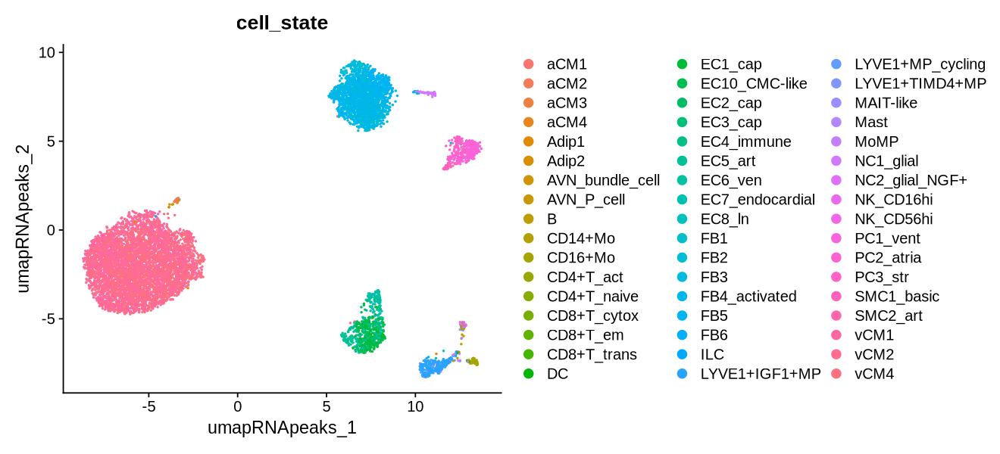

In [21]:
DimPlot(global_analysis_out, group.by = "cell_state", label = FALSE) 

In [23]:
table(global_analysis_out@meta.data$cell_state)


            aCM1             aCM2             aCM3             aCM4 
               7                9                7                7 
           Adip1            Adip2  AVN_bundle_cell       AVN_P_cell 
               3                3                4                2 
               B          CD14+Mo          CD16+Mo        CD4+T_act 
               5                9               37                5 
     CD4+T_naive      CD8+T_cytox         CD8+T_em      CD8+T_trans 
              10                5                3                2 
              DC          EC1_cap    EC10_CMC-like          EC2_cap 
              10              189               20               71 
         EC3_cap       EC4_immune          EC5_art          EC6_ven 
              30               15              160              135 
 EC7_endocardial           EC8_ln              FB1              FB2 
               4                8              111              151 
             FB3    FB4_activated

In [17]:
options(repr.plot.width=9, repr.plot.height=8)

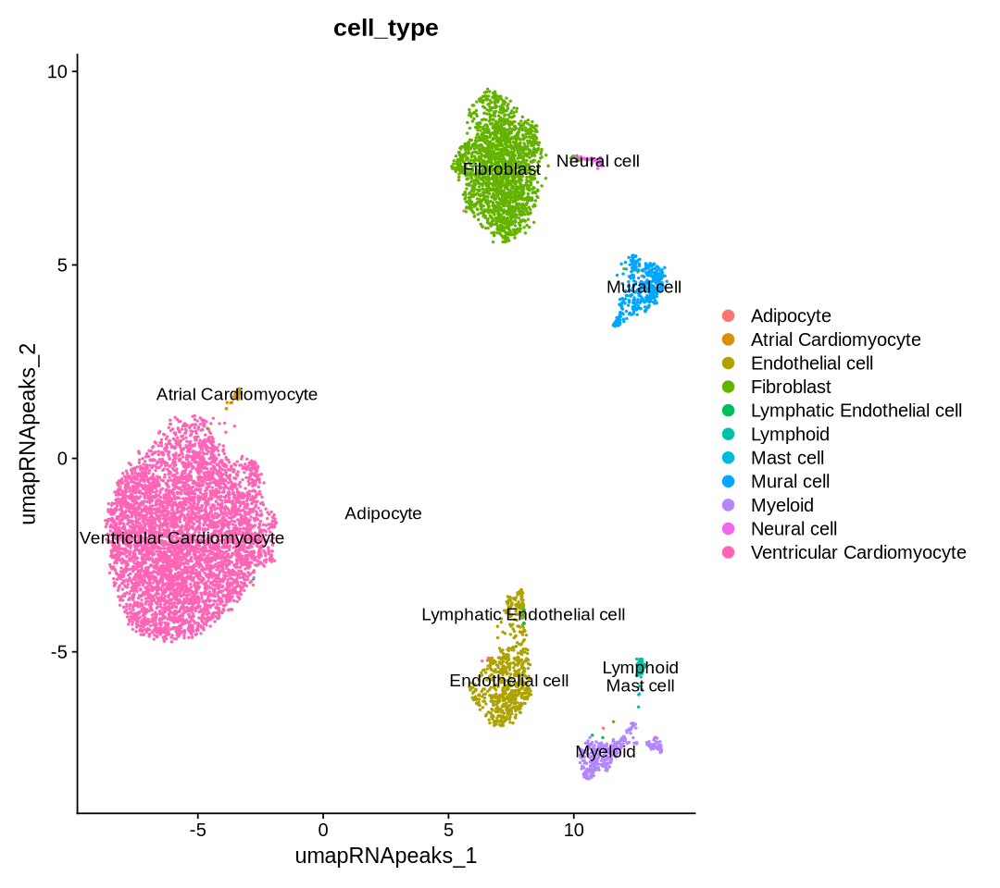

In [18]:
p<-DimPlot(object_w_net, group.by = "cell_type", label = TRUE, ) 
p

In [20]:
ggsave("/nfs/home/students/m.back/swarm/backend/uploads/job_1776009725832_mopitas_hvg_ctg_mygenes_celltg/junkDNA420/multiome/GRN_evaluation/initial_upload/collagen_fibril_orga/peak_plots/umap.png", p, width = 9, height = 8)

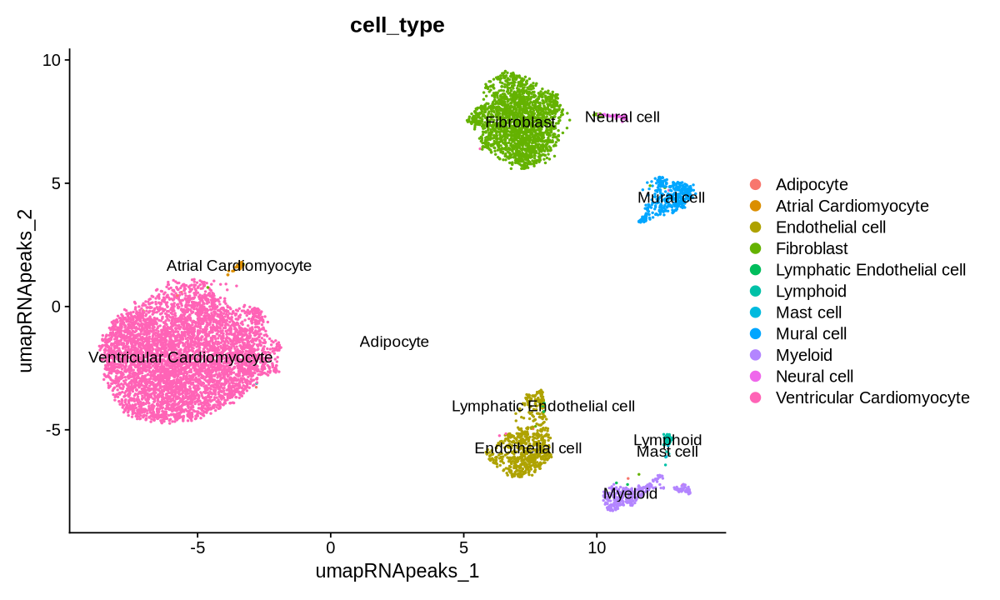

In [ ]:
DimPlot(global_analysis_out, group.by = "cell_type", label = TRUE, ) 

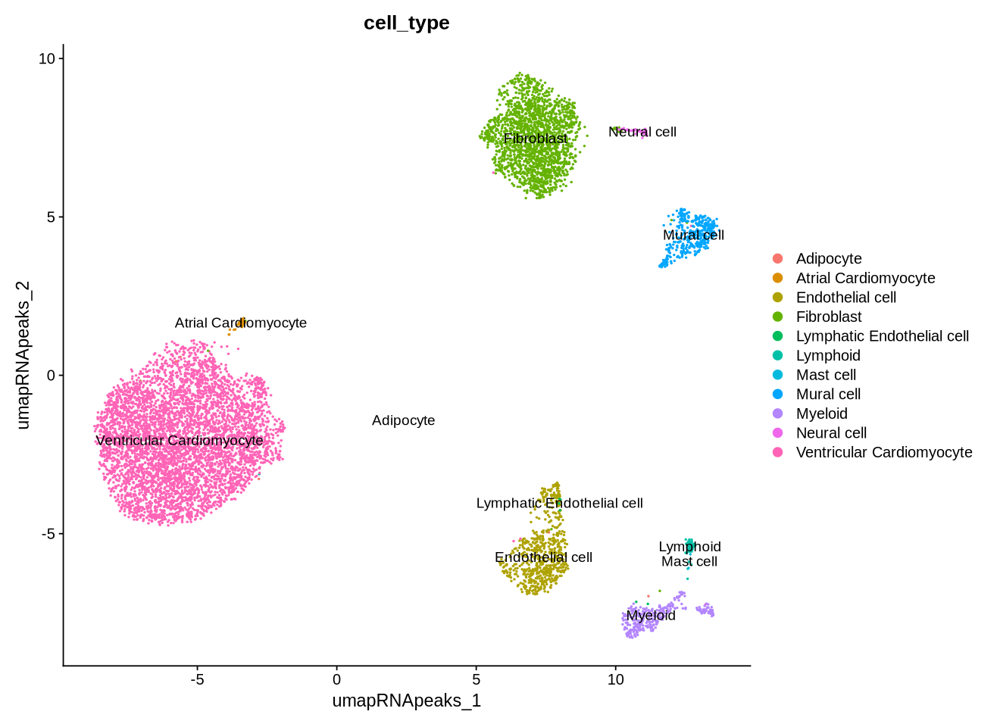

In [ ]:
p<-DimPlot(object_w_net, group.by = "cell_type", label = TRUE) 
ggsave("objects_AVN_fibroblast/peak_plots/umap.png", plot = p, width = 10, height = 6)
p

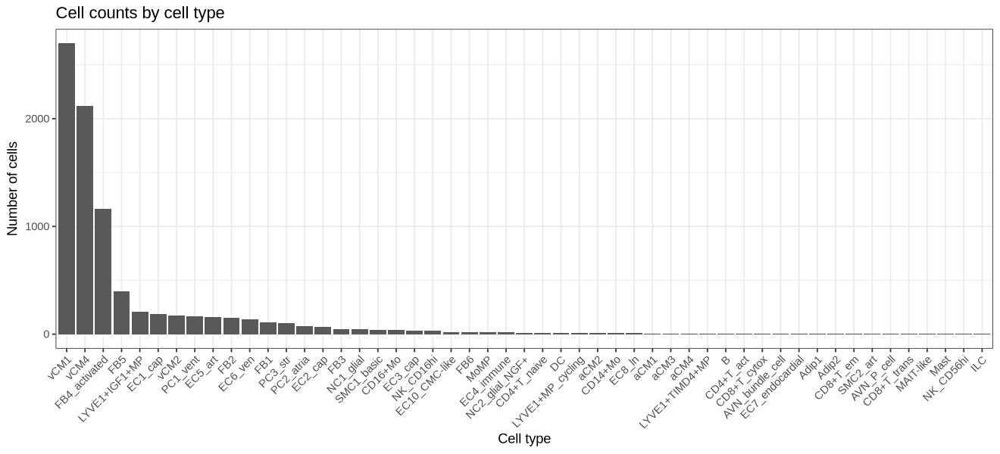

In [24]:
# Count cells per cell type
celltype_counts <- table(global_analysis_out@meta.data[["cell_state"]])

# Convert to data frame
df <- as.data.frame(celltype_counts)
colnames(df) <- c("cell_type", "n_cells")

# Bar chart
library(ggplot2)

ggplot(df, aes(x = reorder(cell_type, -n_cells), y = n_cells)) +
  geom_bar(stat = "identity") +
  theme_bw() +
  labs(x = "Cell type", y = "Number of cells", title = "Cell counts by cell type") +
  theme(axis.text.x = element_text(angle = 45, hjust = 1))

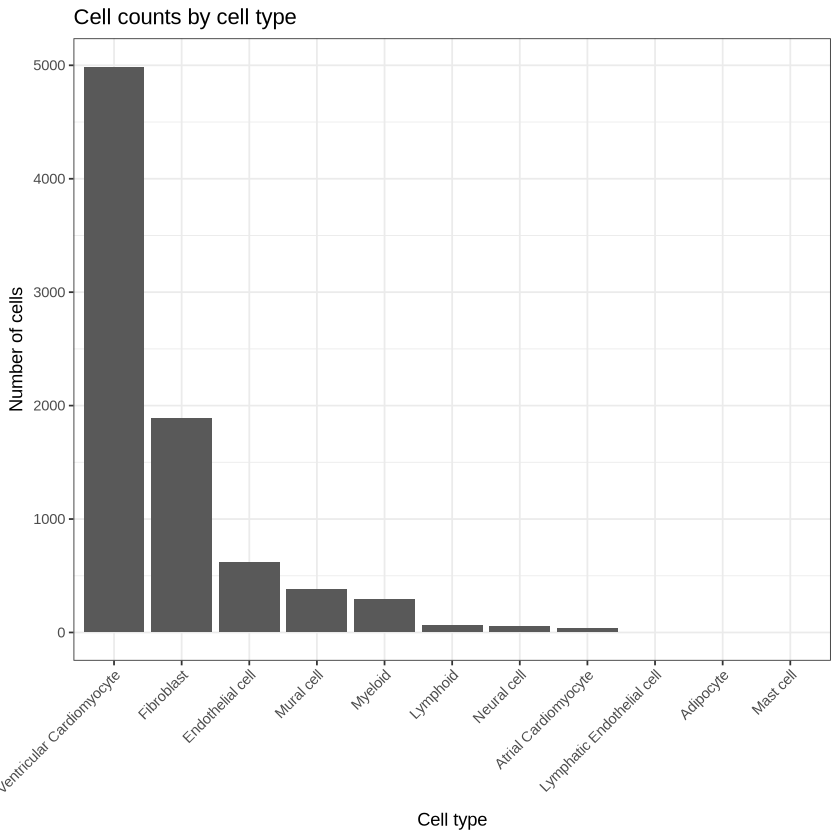

In [5]:
# Count cells per cell type
celltype_counts <- table(global_analysis_out@meta.data[["cell_type"]])

# Convert to data frame
df <- as.data.frame(celltype_counts)
colnames(df) <- c("cell_type", "n_cells")

# Bar chart
library(ggplot2)

ggplot(df, aes(x = reorder(cell_type, -n_cells), y = n_cells)) +
  geom_bar(stat = "identity") +
  theme_bw() +
  labs(x = "Cell type", y = "Number of cells", title = "Cell counts by cell type") +
  theme(axis.text.x = element_text(angle = 45, hjust = 1))

In [5]:
global_analysis_out

An object of class Seurat 
612284 features across 8358 samples within 5 assays 
Active assay: RNA (32724 features, 2000 variable features)
 3 layers present: counts, data, scale.data
 4 other assays present: SCT, ATAC, peaks, chromvar
 5 dimensional reductions calculated: pca_sct, pca_rna, lsi, umap_RNA_peaks, umap_SCT_peaks

In [12]:
unique(global_analysis_out@misc$markers.annotated$cluster)

[1] "0"                          "1"                         
 [3] "2"                          "3"                         
 [5] "4"                          "5"                         
 [7] "6"                          "7"                         
 [9] "8"                          "9"                         
[11] "10"                         "Ventricular Cardiomyocyte" 
[13] "Fibroblast"                 "Atrial Cardiomyocyte"      
[15] "Endothelial cell"           "Adipocyte"                 
[17] "Neural cell"                "Myeloid"                   
[19] "Lymphoid"                   "Lymphatic Endothelial cell"
[21] "Mural cell"

In [17]:
str(global_analysis_out[["RNA"]],max.level=2)

Formal class 'Assay5' [package "SeuratObject"] with 8 slots
  ..@ layers    :List of 3
  ..@ cells     :Formal class 'LogMap' [package "SeuratObject"] with 1 slot
  ..@ features  :Formal class 'LogMap' [package "SeuratObject"] with 1 slot
  ..@ default   : int 1
  ..@ assay.orig: chr(0) 
  ..@ meta.data :'data.frame':	32724 obs. of  8 variables:
  ..@ misc      : Named list()
  ..@ key       : chr "rna_"


In [3]:
global_analysis_out@misc$markers.annotated[global_analysis_out@misc$markers.annotated$annotation=="marker.pos.Fibroblast",]$gene

[1] "MEG8"       "MUSK"       "MFAP5"      "NOX4"       "PDGFRA"    
  [6] "LUM"        "HMCN2"      "SCARA5"     "BICC1"      "MEG3"      
 [11] "PTGIS"      "SERPINF1"   "DCN"        "SVEP1"      "AP002989.1"
 [16] "MRC2"       "CCDC80"     "CLMP"       "ACSM3"      "LTBP2"     
 [21] "KCNT2"      "GFPT2"      "COL12A1"    "PRELP"      "SRPX2"     
 [26] "CFD"        "PLA2G2A"    "ADH1B"      "ADAMTS5"    "IGF1"      
 [31] "THBS2"      "C3"         "ABCA6"      "FBN1"       "ABCA9"     
 [36] "MGST1"      "COL6A3"     "SLIT2"      "ABCA9-AS1"  "FBLN5"     
 [41] "PLEKHH2"    "COL8A1"     "SERPINE2"   "SULF1"      "FBLN2"     
 [46] "COL4A4"     "C7"         "COL4A3"     "KAZN"       "ELN"       
 [51] "NEGR1"      "ABCA10"     "RARRES1"    "ABI3BP"     "PAMR1"     
 [56] "CCN2"       "AL445250.1" "FBLN1"      "APOD"       "MGP"       
 [61] "CFH"        "NNMT"       "TNXB"       "AEBP1"      "COL5A1"    
 [66] "C1R"        "COL14A1"    "ITGA11"     "COL1A2"     "GLIS3"     
 [71] "LPAR1"      "CEP126"     "PDGFD"      "C11orf80"   "SNED1"     
 [76] "COL5A2"     "UAP1"       "C1S"        "ROBO1"      "BNC2"      
 [81] "PCOLCE2"    "COLGALT2"   "XYLT1"      "CHSY3"      "F2R"       
 [86] "ABCA8"      "FN1"        "SERPING1"   "MAPK10"     "SMOC2"     
 [91] "EGFR"       "LRP1"       "VCAN"       "CDH19"      "TSHZ2"     
 [96] "TIMP1"      "EFEMP1"     "PXDN"       "COL3A1"     "ITIH5"

# pathways for fibroblasts, since they are in node:


In [6]:


library(AnnotationDbi)
library(org.Hs.eg.db)
cardiac_valve_development <- AnnotationDbi::select(
  org.Hs.eg.db,
  keys    = "GO:0003170",
  keytype = "GOALL",
  columns = c("ENSEMBL", "SYMBOL", "GOALL", "ONTOLOGYALL")
)
head(cardiac_valve_development)
dim(cardiac_valve_development)



'select()' returned 1:many mapping between keys and columns



,GOALL,EVIDENCEALL,ONTOLOGYALL,ENSEMBL,SYMBOL
,<chr>,<chr>,<chr>,<chr>,<chr>
1,GO:0003170,IMP,BP,ENSG00000115170,ACVR1
2,GO:0003170,ISS,BP,ENSG00000115170,ACVR1
3,GO:0003170,IMP,BP,ENSG00000101384,JAG1
4,GO:0003170,NAS,BP,ENSG00000101384,JAG1
5,GO:0003170,ISS,BP,ENSG00000134817,APLNR
6,GO:0003170,ISS,BP,ENSG00000134982,APC


[1] 98  5

In [7]:
intersect(cardiac_valve_development$SYMBOL, global_analysis_out@misc$markers.annotated[global_analysis_out@misc$markers.annotated$annotation=="marker.pos.Fibroblast",]$gene)

[1] "ELN"     "ROBO1"   "SLIT2"   "ADAMTS5"

In [8]:
res <- plot_module_scores(
  object = global_analysis_out,
  seed_genes = cardiac_valve_development$SYMBOL,
  module_name = "AVN_module",
  assay_name = "RNA",
  cluster_name = "cell_type",
  test_method = "wilcox",     # or "t.test"
  alternative = "greater",    # enrichment = higher in cluster than others
  label_type = "stars",
  show_ns = FALSE
)

Genes found: 75 


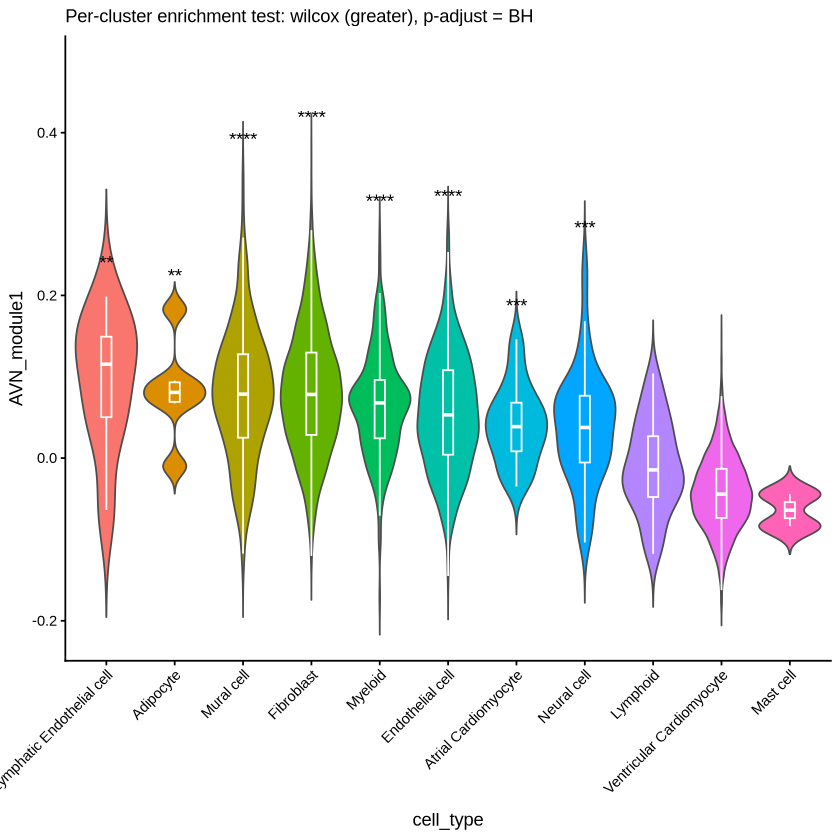

In [9]:
res$plot

In [39]:



library(AnnotationDbi)
library(org.Hs.eg.db)
colagen_fibral_orga <- AnnotationDbi::select(
  org.Hs.eg.db,
  keys    = "GO:0030199",
  keytype = "GOALL",
  columns = c("ENSEMBL", "SYMBOL", "GOALL", "ONTOLOGYALL")
)
head(colagen_fibral_orga)
dim(colagen_fibral_orga)
# https://pubmed.ncbi.nlm.nih.gov/18816857/



'select()' returned 1:many mapping between keys and columns



,GOALL,EVIDENCEALL,ONTOLOGYALL,ENSEMBL,SYMBOL
,<chr>,<chr>,<chr>,<chr>,<chr>
1,GO:0030199,IDA,BP,ENSG00000106624,AEBP1
2,GO:0030199,IEA,BP,ENSG00000182718,ANXA2
3,GO:0030199,ISS,BP,ENSG00000165240,ATP7A
4,GO:0030199,TAS,BP,ENSG00000168487,BMP1
5,GO:0030199,IBA,BP,ENSG00000149257,SERPINH1
6,GO:0030199,IMP,BP,ENSG00000108821,COL1A1


[1] 118   5

In [11]:
intersect(colagen_fibral_orga$SYMBOL, global_analysis_out@misc$markers.annotated[global_analysis_out@misc$markers.annotated$annotation=="marker.pos.Fibroblast",]$gene)

[1] "AEBP1"    "COL1A2"   "COL3A1"   "COL5A1"   "COL5A2"   "COL12A1" 
 [7] "LUM"      "TNXB"     "COL14A1"  "PXDN"     "COLGALT2"

In [39]:
options(repr.plot.width=8, repr.plot.height=5)


In [42]:
ggsave("module_score.png", plot=res$plot,  width = 12, height = 8)

In [57]:
plot_module_scores <- function(
  object,
  seed_genes,
  module_name = "AVN_module",
  assay_name = "RNA",
  cluster_name = "cell_type",
  test_method = c("wilcox", "t.test"),
  alternative = c("greater", "two.sided", "less"),
  p_adjust_method = "BH",
  label_type = c("stars", "p.adj"),
  show_ns = TRUE
) {
  test_method <- match.arg(test_method)
  alternative <- match.arg(alternative)
  label_type <- match.arg(label_type)

  DefaultAssay(object) <- assay_name
  score_col <- paste0(module_name, "1")

  # Keep only genes present in this object
  seed_genes_present <- intersect(seed_genes, rownames(object))
  missing_genes <- setdiff(seed_genes, seed_genes_present)

  if (length(seed_genes_present) == 0) {
    stop("None of the seed genes are present in the object.")
  }

  cat("Genes found:", length(seed_genes_present), "\n")
  if (length(missing_genes) > 0) {
    cat("Missing genes:", paste(missing_genes, collapse = ", "), "\n")
  }

  Idents(object) <- cluster_name

  # Add module score
  object <- AddModuleScore(
    object = object,
    features = list(seed_genes_present),
    name = module_name,
    assay = assay_name,
    seed = 123
  )

  # Pull data for plotting
  plot_df <- FetchData(object, vars = c(cluster_name, score_col))
  colnames(plot_df) <- c("cluster", "score")

  # Order clusters by median score
  celltype_order <- plot_df %>%
    dplyr::group_by(cluster) %>%
    dplyr::summarise(med = median(score, na.rm = TRUE), .groups = "drop") %>%
    dplyr::arrange(dplyr::desc(med)) %>%
    dplyr::pull(cluster)

  plot_df$cluster <- factor(plot_df$cluster, levels = celltype_order)

  # Count cells per cluster
  n_cells_df <- plot_df %>%
    dplyr::count(cluster, name = "n_cells")

  # Create x-axis labels with cell numbers
  x_labels <- setNames(
    paste0(as.character(n_cells_df$cluster), "\n(n=", n_cells_df$n_cells, ")"),
    n_cells_df$cluster
  )

  # Per-cluster enrichment test: cluster vs all other cells
  stats_df <- lapply(levels(plot_df$cluster), function(cl) {
    x <- plot_df$score[plot_df$cluster == cl]
    y <- plot_df$score[plot_df$cluster != cl]

    test_res <- switch(
      test_method,
      wilcox = stats::wilcox.test(x, y, alternative = alternative, exact = FALSE),
      `t.test` = stats::t.test(x, y, alternative = alternative)
    )

    data.frame(
      cluster = cl,
      n_cluster = length(x),
      n_other = length(y),
      mean_cluster = mean(x, na.rm = TRUE),
      mean_other = mean(y, na.rm = TRUE),
      median_cluster = median(x, na.rm = TRUE),
      median_other = median(y, na.rm = TRUE),
      effect_mean = mean(x, na.rm = TRUE) - mean(y, na.rm = TRUE),
      effect_median = median(x, na.rm = TRUE) - median(y, na.rm = TRUE),
      p_val = test_res$p.value,
      stringsAsFactors = FALSE
    )
  }) %>%
    dplyr::bind_rows() %>%
    dplyr::mutate(
      p_adj = stats::p.adjust(p_val, method = p_adjust_method)
    )

  # Significance labels
  p_to_stars <- function(p) {
    dplyr::case_when(
      is.na(p)  ~ NA_character_,
      p <= 1e-4 ~ "****",
      p <= 1e-3 ~ "***",
      p <= 1e-2 ~ "**",
      p <= 5e-2 ~ "*",
      TRUE      ~ "ns"
    )
  }

  stats_df <- stats_df %>%
    dplyr::mutate(
      label = if (label_type == "stars") {
        p_to_stars(p_adj)
      } else {
        paste0("adj.P=", signif(p_adj, 2))
      }
    )

  if (!show_ns && label_type == "stars") {
    stats_df$label[stats_df$label == "ns"] <- ""
  }

  # Y-positions for annotation
  y_range <- diff(range(plot_df$score, na.rm = TRUE))
  if (y_range == 0) y_range <- 1

  annot_df <- plot_df %>%
    dplyr::group_by(cluster) %>%
    dplyr::summarise(y_pos = max(score, na.rm = TRUE) + 0.06 * y_range, .groups = "drop") %>%
    dplyr::left_join(stats_df, by = "cluster")

  # Plot

p <- ggplot(plot_df, aes(x = cluster, y = score, fill = cluster)) +
  geom_violin(trim = FALSE, scale = "width", color = "grey30") +
  geom_boxplot(width = 0.15, outlier.shape = NA, alpha = 0.5, color = "white") +
  geom_text(
    data = annot_df,
    aes(x = cluster, y = y_pos, label = label),
    inherit.aes = FALSE,
    vjust = 0,
    size = 6
  ) +
  theme_classic() +
  labs(
    x = cluster_name,
    y = score_col,
    subtitle = paste0(
      "Per-cluster enrichment test: ",
      test_method,
      " (", alternative, "), p-adjust = ", p_adjust_method
    )
  ) +
  scale_x_discrete(labels = x_labels) +
  scale_y_continuous(expand = ggplot2::expansion(mult = c(0.05, 0.15))) +
  theme(
    axis.text.x = element_text(angle = 45, hjust = 1),
    legend.position = "none",
    plot.caption = element_text(hjust = 0, size = 10)
  )

  return(list(
    plot = p,
    object = object,
    stats = stats_df,
    plot_data = plot_df
  ))
}

In [49]:
options(repr.plot.width=6, repr.plot.height=4)


Genes found: 68 
Missing genes: MIR29B1 


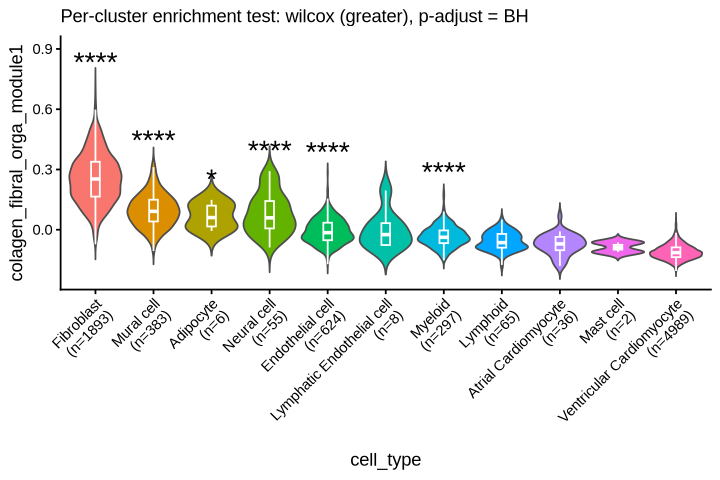

In [58]:
res <- plot_module_scores(
  object = object_w_net,
  seed_genes = colagen_fibral_orga$SYMBOL,
  module_name = "colagen_fibral_orga_module",
  assay_name = "RNA",
  cluster_name = "cell_type",
  test_method = "wilcox",     # or "t.test"
  alternative = "greater",    # enrichment = higher in cluster than others
  label_type = "stars",
  show_ns = FALSE
)
res$plot



Genes found: 68 
Missing genes: MIR29B1 


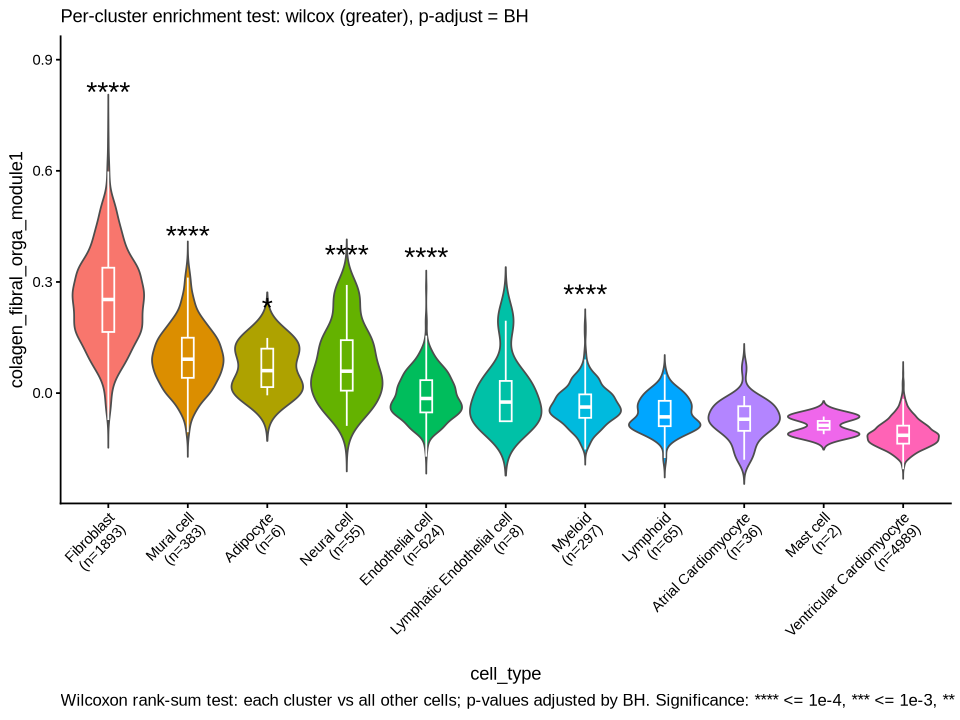

In [48]:
res <- plot_module_scores(
  object = object_w_net,
  seed_genes = colagen_fibral_orga$SYMBOL,
  module_name = "colagen_fibral_orga_module",
  assay_name = "RNA",
  cluster_name = "cell_type",
  test_method = "wilcox",     # or "t.test"
  alternative = "greater",    # enrichment = higher in cluster than others
  label_type = "stars",
  show_ns = FALSE
)
res$plot


In [42]:
res <- plot_module_scores(
  object = global_analysis_out,
  seed_genes = colagen_fibral_orga$SYMBOL,
  module_name = "colagen_fibral_orga_module",
  assay_name = "RNA",
  cluster_name = "cell_type",
  test_method = "wilcox",     # or "t.test"
  alternative = "greater",    # enrichment = higher in cluster than others
  label_type = "stars",
  show_ns = FALSE
)
res$plot


ERROR: Error: object 'global_analysis_out' not found


Genes found: 68 
Missing genes: MIR29B1 


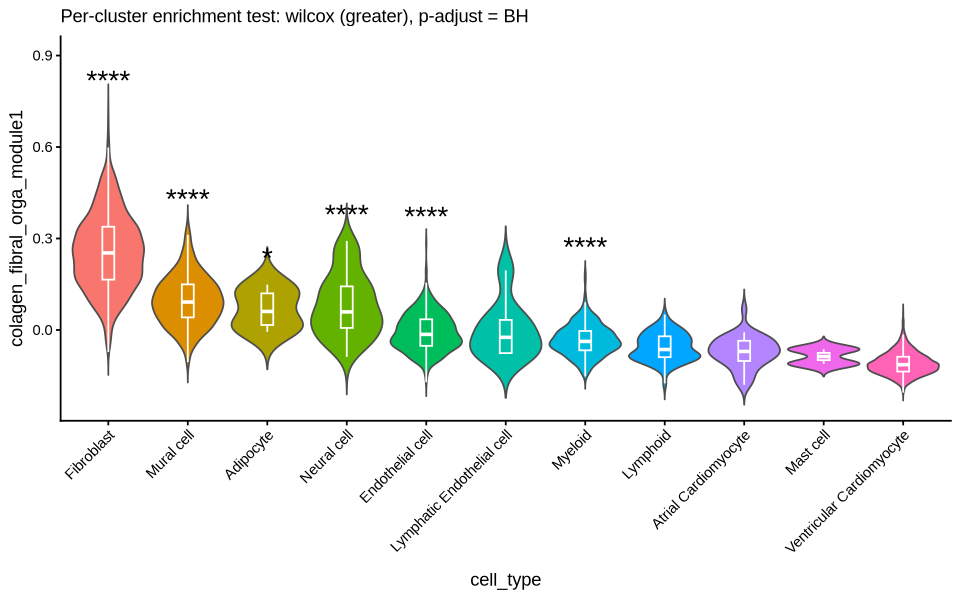

In [44]:
res <- plot_module_scores(
  object = global_analysis_out,
  seed_genes = colagen_fibral_orga$SYMBOL,
  module_name = "colagen_fibral_orga_module",
  assay_name = "RNA",
  cluster_name = "cell_type",
  test_method = "wilcox",     # or "t.test"
  alternative = "greater",    # enrichment = higher in cluster than others
  label_type = "stars",
  show_ns = FALSE
)
res$plot


Genes found: 68 
Missing genes: MIR29B1 


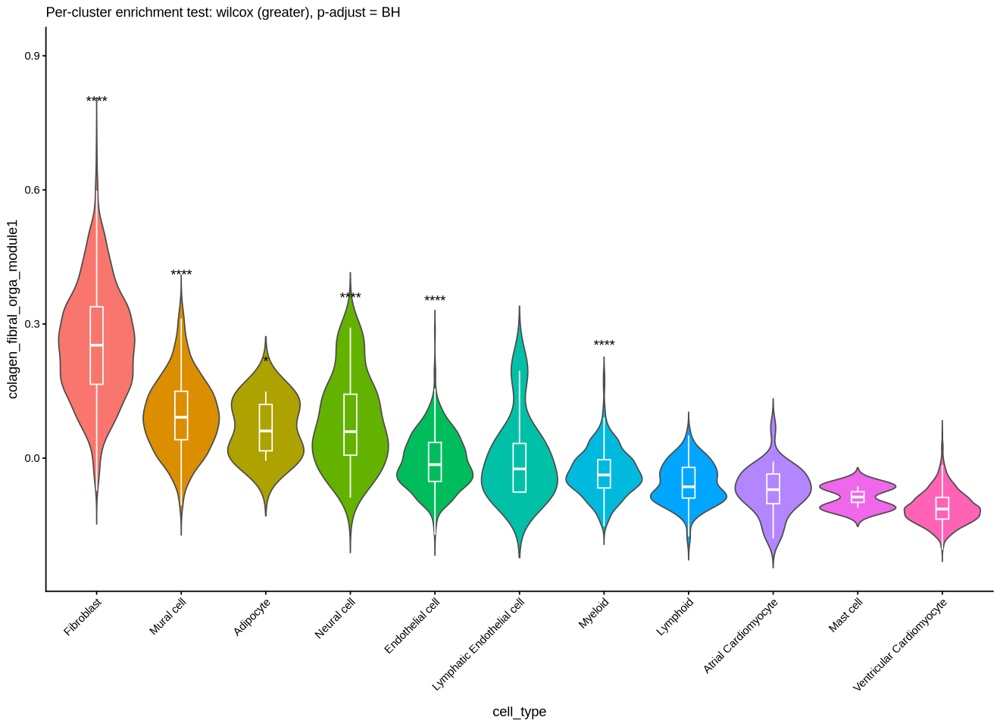

In [13]:
res <- plot_module_scores(
  object = global_analysis_out,
  seed_genes = colagen_fibral_orga$SYMBOL,
  module_name = "colagen_fibral_orga_module",
  assay_name = "RNA",
  cluster_name = "cell_type",
  test_method = "wilcox",     # or "t.test"
  alternative = "greater",    # enrichment = higher in cluster than others
  label_type = "stars",
  show_ns = FALSE
)
res$plot

In [16]:

ggsave("objects_AVN_fibroblast/peak_plots/module_enrichment.pdf", plot = res$plot, width = 8, height = 6)

In [14]:

ggsave("objects_AVN_fibroblast/peak_plots/module_enrichment.png", plot = res$plot, width = 8, height = 6)

## try other network

In [122]:
# omnipath
tf_gene_df <- data.frame(
    gene = c(
        "AEBP1", "AEBP1", "COL1A2", "COL1A2", "COL1A2", "COL1A2",
        "COL3A1", "COL3A1", "COL5A1", "COL5A2", "COL12A1", "COL14A1",
        "LUM", "LUM", "PXDN", "PXDN", "PXDN", "TNXB", "TNXB",
        "COLGALT2", "COLGALT2"
    ),
    TF = c(
        "SP1", "SRF", "RFX5", "RUNX2", "SMAD3", "SP1",
        "SMAD3", "SP1", "SP1", "FOXF2", "EGR1", "EGR1",
        "NFYA", "PPARG", "NFE2L2", "SNAI1", "SRF", "SP1", "SP3",
        "HNF1A", "SOX5"
    ),
    stringsAsFactors = FALSE
)

tf_gene_df <- tf_gene_df[order(tf_gene_df$gene, tf_gene_df$TF), ]
rownames(tf_gene_df) <- NULL

tf_gene_df


gene,TF
<chr>,<chr>
AEBP1,SP1
AEBP1,SRF
COL12A1,EGR1
COL14A1,EGR1
COL1A2,RFX5
COL1A2,RUNX2
COL1A2,SMAD3
COL1A2,SP1
COL3A1,SMAD3


## for whole pathway

# 0. find cluster that might be relevant for this pathway


In [3]:
seed_genes <- colagen_fibral_orga$SYMBOL

In [7]:
priorGRN <- heart_tbl[heart_tbl$gene_name %in%  seed_genes,]

In [8]:

priorGRN <- priorGRN[(priorGRN$net_atrial_appendage>0 | priorGRN$net_left_ventricle>0) & (priorGRN$TS_left_ventricle==1 | priorGRN$TS_atrial_appendage==1 | priorGRN$Prior==1),]

In [9]:
priorGRN

,Gene,TF,Prior,TS_atrial_appendage,TS_left_ventricle,net_atrial_appendage,net_left_ventricle,gene_name
,<chr>,<chr>,<int>,<int>,<int>,<dbl>,<dbl>,<chr>
6002,ENSG00000038295,ZBTB33,0,0,1,-0.340480,0.200560,TLL1
16185,ENSG00000083444,PURA,1,0,1,4.681500,4.967800,PLOD1
47456,ENSG00000115318,ATF1,1,1,0,6.160200,5.993800,LOXL3
84556,ENSG00000139329,CTCFL,0,0,1,-0.555200,0.265900,LUM
84981,ENSG00000139687,KDM2B,0,0,1,-0.215280,0.237770,RB1
89856,ENSG00000143196,E2F6,0,0,1,-0.471640,0.124420,DPT
89857,ENSG00000143196,EGR3,0,0,1,-0.260850,0.412610,DPT
89858,ENSG00000143196,INSM1,0,0,1,-0.041592,0.790960,DPT
89859,ENSG00000143196,CTCFL,0,0,1,-0.349960,0.460940,DPT


# 1. begin with linking peaks

[1] "list"
[1] "data.frame"
                  EID     TF Prior TS_atrial_appendage TS_left_ventricle
6002  ENSG00000038295 ZBTB33     0                   0                 1
16185 ENSG00000083444   PURA     1                   0                 1
47456 ENSG00000115318   ATF1     1                   1                 0
84556 ENSG00000139329  CTCFL     0                   0                 1
84981 ENSG00000139687  KDM2B     0                   0                 1
89856 ENSG00000143196   E2F6     0                   0                 1
      net_atrial_appendage net_left_ventricle  gene
6002              -0.34048            0.20056  TLL1
16185              4.68150            4.96780 PLOD1
47456              6.16020            5.99380 LOXL3
84556             -0.55520            0.26590   LUM
84981             -0.21528            0.23777   RB1
89856             -0.47164            0.12442   DPT
[1] "Linking peaks to genes..."
 [1] "TLL1"     "PLOD1"    "LOXL3"    "LUM"      "RB1"      "DPT"

Found gene coordinates for 63 genes

Testing 64 genes and 4339 peaks



[1] "Computing peak-gene distances..."
[1] "Filtering links for promoters..."
  [1]  TRUE FALSE  TRUE  TRUE  TRUE FALSE FALSE FALSE FALSE  TRUE  TRUE  TRUE
 [13]  TRUE  TRUE  TRUE  TRUE  TRUE FALSE FALSE FALSE FALSE  TRUE  TRUE  TRUE
 [25]  TRUE  TRUE  TRUE  TRUE  TRUE FALSE FALSE FALSE  TRUE FALSE  TRUE  TRUE
 [37]  TRUE  TRUE FALSE FALSE FALSE  TRUE FALSE  TRUE FALSE  TRUE  TRUE  TRUE
 [49]  TRUE  TRUE FALSE FALSE FALSE FALSE FALSE FALSE FALSE FALSE FALSE FALSE
 [61] FALSE  TRUE  TRUE  TRUE  TRUE  TRUE  TRUE FALSE FALSE  TRUE  TRUE  TRUE
 [73] FALSE FALSE  TRUE  TRUE  TRUE  TRUE  TRUE  TRUE  TRUE  TRUE FALSE FALSE
 [85] FALSE FALSE FALSE  TRUE  TRUE  TRUE  TRUE  TRUE  TRUE FALSE FALSE FALSE
 [97] FALSE FALSE  TRUE  TRUE  TRUE  TRUE  TRUE  TRUE  TRUE  TRUE  TRUE  TRUE
[109]  TRUE FALSE FALSE FALSE FALSE FALSE FALSE  TRUE  TRUE  TRUE FALSE FALSE
[121] FALSE FALSE FALSE  TRUE FALSE FALSE FALSE FALSE FALSE  TRUE  TRUE  TRUE
[133]  TRUE  TRUE  TRUE  TRUE  TRUE  TRUE  TRUE  TRUE  TRUE  TRU

Computing hash



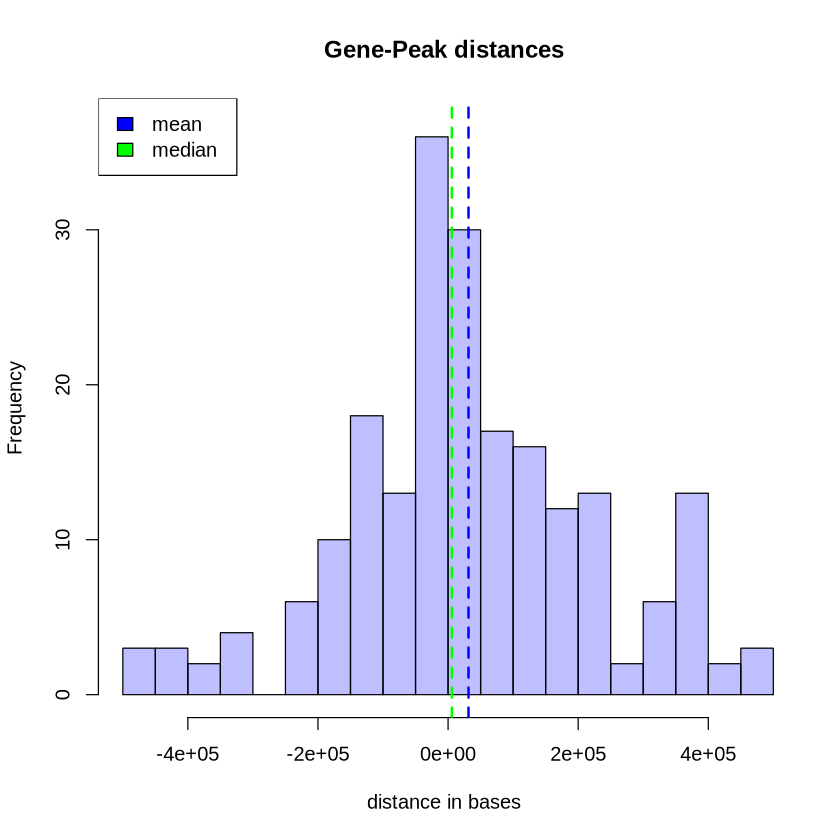

In [10]:
res_links <- linking_peaks_for_module_cluster(global_analysis_out, 
                                seed_genes, 
                                priorGRN, 
                                cluster="Fibroblast",
                                gene_name_2_gene_id,
                                frag_path = "~/swarm/backend/data/cell_atlas/HCAHeartST11350194_HCAHeartST11445771_atac_fragments.tsv.gz")

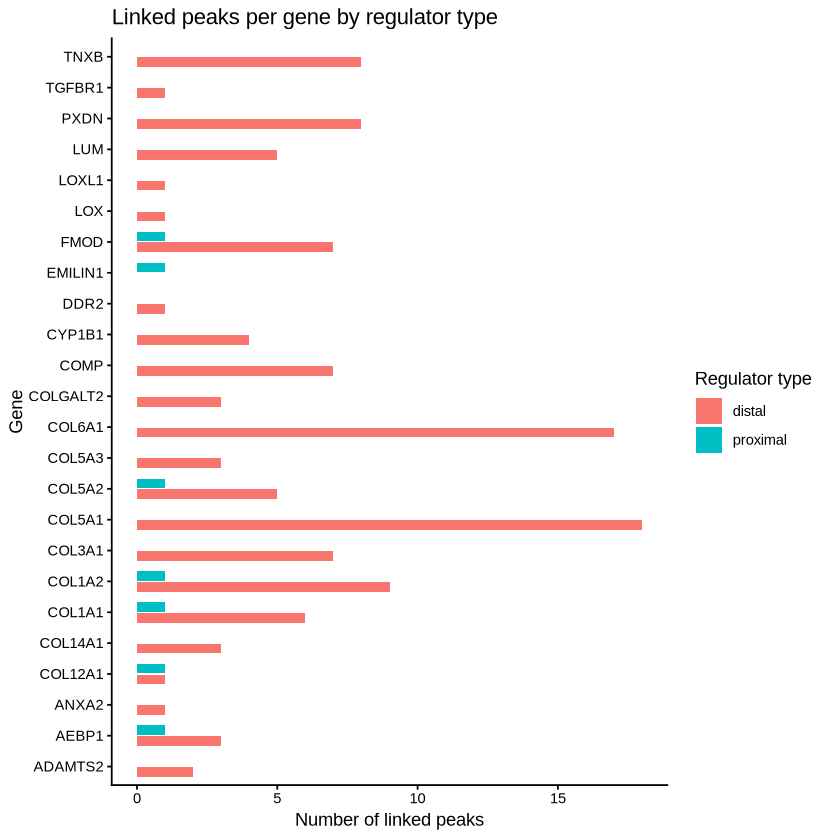

In [34]:
res_links$plot_links

In [19]:
p <- plot_links_per_gene(object_w_net)
ggsave("objects_AVN_fibroblast/peak_plots/links_distr.pdf", plot = p, width = 6, height = 6)


In [15]:
p <- plot_links_per_gene(object_w_net)
ggsave("objects_AVN_fibroblast/peak_plots/links_distr.png", plot = p, width = 6, height = 6)


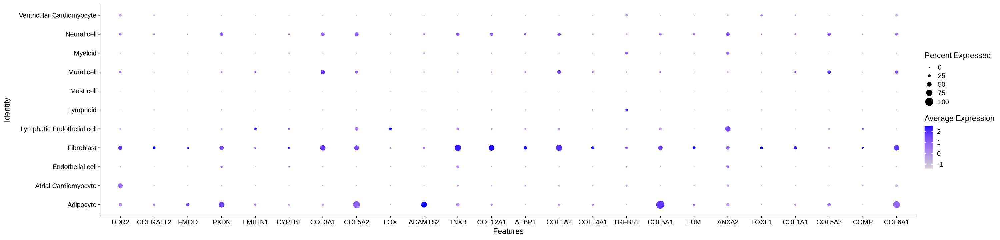

In [26]:
options(repr.plot.width=25, repr.plot.height=6)
DotPlot(res_links$object, features = unique(Links(res_links$object)$gene), assay = "RNA", group.by = "cell_type")

In [41]:
Links(object_w_net[["peaks"]])[Links(object_w_net[["peaks"]])$gene=="TNXB"]

GRanges object with 8 ranges and 8 metadata columns:
      seqnames            ranges strand |     score        gene
         <Rle>         <IRanges>  <Rle> | <numeric> <character>
  [1]     chr6 32046711-32115334      * | 0.1552612        TNXB
  [2]     chr6 32071339-32115334      * | 0.1319514        TNXB
  [3]     chr6 32076585-32115334      * | 0.0580212        TNXB
  [4]     chr6 32081341-32115334      * | 0.1047474        TNXB
  [5]     chr6 32083037-32115334      * | 0.1213482        TNXB
  [6]     chr6 32109333-32115334      * | 0.0995950        TNXB
  [7]     chr6 32114170-32115334      * | 0.1228658        TNXB
  [8]     chr6 32115334-32255191      * | 0.0741835        TNXB
                        peak    zscore      pvalue distancePeakStartTSS
                 <character> <numeric>   <numeric>            <numeric>
  [1] chr6-32045988-32047433   4.59917 2.12089e-06                67561
  [2] chr6-32070791-32071886   3.27822 5.22319e-04                43108
  [3] chr6-32076450

Warning message:
"`aes_string()` was deprecated in ggplot2 3.0.0.
ℹ Please use tidy evaluation idioms with `aes()`.
ℹ See also `vignette("ggplot2-in-packages")` for more information.
ℹ The deprecated feature was likely used in the Signac package.
  Please report the issue at <https://github.com/stuart-lab/signac/issues>."


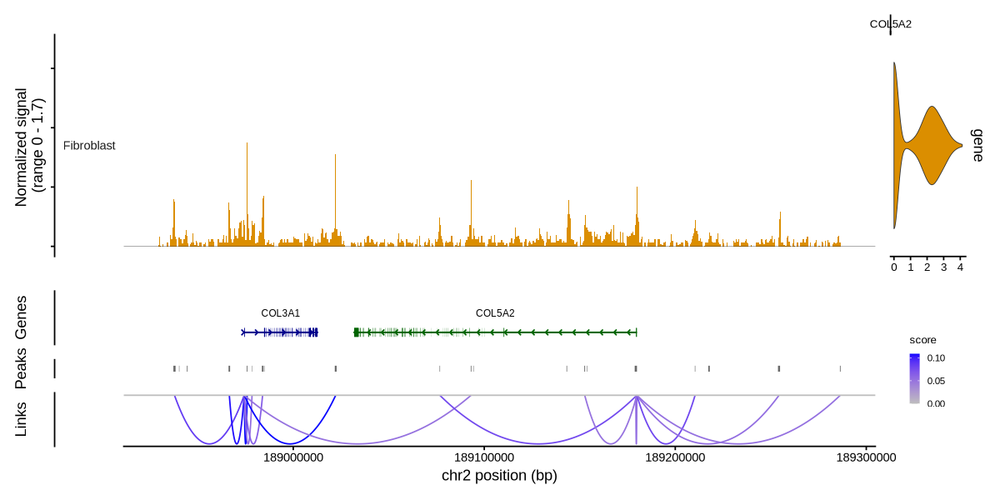

In [72]:
options(repr.plot.width=10, repr.plot.height=5)
coverage_plot_for_gene(object_w_net, "COL5A2", cluster="Fibroblast")

In [18]:
options(repr.plot.width=10, repr.plot.height=5)
p <- coverage_plot_for_gene(object_w_net, "TNXB", cluster="Fibroblast")
ggsave("objects_AVN_fibroblast/peak_plots/TNXB_coverage.png", plot = p, width = 8, height = 4)

Warning message:
"Using `size` aesthetic for lines was deprecated in ggplot2 3.4.0.
ℹ Please use `linewidth` instead.
ℹ The deprecated feature was likely used in the Signac package.
  Please report the issue at <https://github.com/stuart-lab/signac/issues>."
Warning message:
"`aes_string()` was deprecated in ggplot2 3.0.0.
ℹ Please use tidy evaluation idioms with `aes()`.
ℹ See also `vignette("ggplot2-in-packages")` for more information.
ℹ The deprecated feature was likely used in the Signac package.
  Please report the issue at <https://github.com/stuart-lab/signac/issues>."
Warning message:
"Removed 30 rows containing missing values or values outside the scale range
(`geom_segment()`)."


In [19]:
options(repr.plot.width=10, repr.plot.height=5)
p <- coverage_plot_for_gene(object_w_net, "COL5A1", cluster="Fibroblast")
ggsave("objects_AVN_fibroblast/peak_plots/COL5A1_coverage.png", plot = p, width = 8, height = 4)

In [20]:
options(repr.plot.width=10, repr.plot.height=5)
p <- coverage_plot_for_gene(object_w_net, "COL1A1", cluster="Fibroblast")
ggsave("objects_AVN_fibroblast/peak_plots/COL1A1_coverage.png", plot = p, width = 8, height = 4)

In [21]:
options(repr.plot.width=10, repr.plot.height=5)
p <- coverage_plot_for_gene(object_w_net, "COL1A2", cluster="Fibroblast")
ggsave("objects_AVN_fibroblast/peak_plots/COL1A2_coverage.png", plot = p, width = 8, height = 4)

Warning message:
"Removed 209 rows containing missing values or values outside the scale range
(`geom_segment()`)."


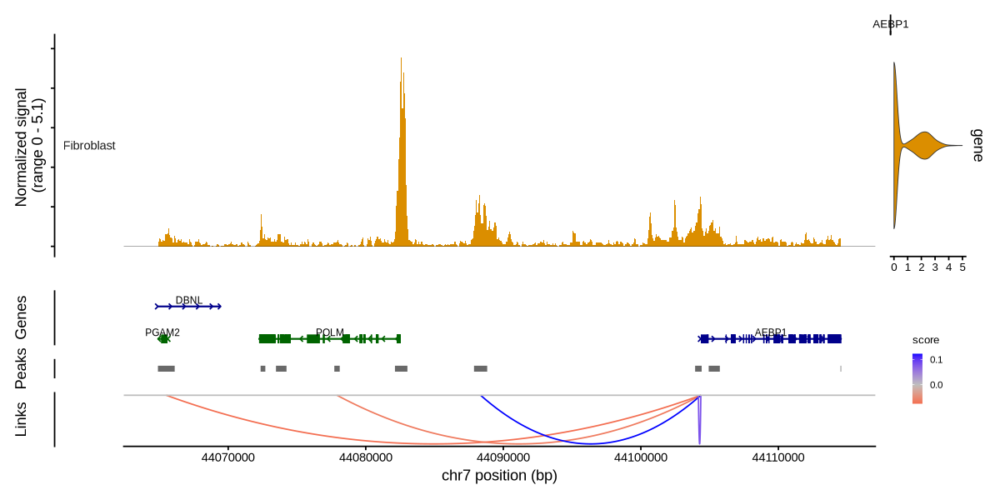

In [ ]:

options(repr.plot.width=10, repr.plot.height=5)
p <- coverage_plot_for_gene(object_w_net, "AEBP1", cluster="Fibroblast")
ggsave("objects_AVN_fibroblast/peak_plots/AEBP1_coverage.pdf", plot = p, width = 8, height = 4)

# 2. identify cluster specific peaks

In [ ]:
#understand what peak stants does 
# adds object@misc$peak_stats
# adds filtered version: object@misc$df.stats.filtered

In [31]:
seeds_for_peaks_stats <- data.frame(
  cluster = "Fibroblast",
  gene = res_links$seeds[["gene"]],
  annotation = "colagen_fibral_orga",
  stringsAsFactors = FALSE
)


In [33]:

# seeds here needs: gene, cluster, annotation
res_peak_stats <-do_peak_stats(object=res_links$object, seeds=seeds_for_peaks_stats, promoter.needed = FALSE)

[1] "Writing peak stats table..."
[1] "Conducting cluster specific statistical tests..."
[1] "Calculating zero expression stats..."
[1] "Clustering peaks for bg distributions..."


Warning message:
"Quick-TRANSfer stage steps exceeded maximum (= 6337300)"


[1] "Counting peaks per seed..."
[1] "Filtering peak stats..."
[1] "Number of linked peaks after filtering: 122"

            both cluster_specific           global 
              90                8               24 


In [34]:
saveRDS(res_peak_stats, file = "objects_AVN_fibroblast/res_peak_stats.rds")

In [37]:
unique(res_peak_stats@misc$peak_stats.filtered$gene)

[1] "DDR2"     "COLGALT2" "FMOD"     "EMILIN1"  "COL3A1"   "PXDN"    
 [7] "CYP1B1"   "COL5A2"   "LOX"      "ADAMTS2"  "TNXB"     "COL12A1" 
[13] "AEBP1"    "COL1A2"   "COL14A1"  "TGFBR1"   "COL5A1"   "LUM"     
[19] "ANXA2"    "COL1A1"   "COL5A3"   "COMP"     "COL6A1"

# 3. do local motif stats

- adds to:
    - object@misc$motifs.inProximalPeaks
    - object@misc$motifs.inDistalPeaks

In [39]:
source("../multiome_methods/function_calls.r")

In [40]:
res_local_motif_stats <- do_local_motif_stats(object=res_peak_stats, 
                               seeds=seeds_for_peaks_stats,
                               fragpath=NULL,
                               peaks_assay='peaks',
                               background_size=50, parallel=TRUE,
                               min_count=1, min_log2FC=1, max_t_stat=0, min_p_adjust=0.05)

Calculating motif enrichment

counting motifs in linked peaks

n gene/cluster pairs: 23

Preparing motif overlap cache sequentially ...

n gene/cluster pairs: 23

[cache] 1/23 : ADAMTS2 | Fibroblast

[cache] 23/23 : TNXB | Fibroblast

precomputing motif GRanges cache

running per-gene motif enrichment in parallel with 20 worker(s)

counting motifs in promoter region

Filtering motif enrichment

Adding footprint stats

Warning message:
"The `slot` argument of `GetAssayData()` is deprecated as of SeuratObject 5.0.0.
ℹ Please use the `layer` argument instead."
Warning message in filtered.enrichment$footprint.p_value_adj[filtered.enrichment$gene == :
"number of items to replace is not a multiple of replacement length"


In [41]:

saveRDS(res_local_motif_stats, "objects_AVN_fibroblast/res_local_motif_stats.rds")

In [42]:
str(res_local_motif_stats@misc, max.level=1)

List of 8
 $ markers.annotated        :'data.frame':	4075 obs. of  8 variables:
 $ peak_stats               :'data.frame':	130 obs. of  51 variables:
 $ peak_stats.filtered      :'data.frame':	122 obs. of  51 variables:
 $ motifs.inProximalPeaks   :List of 23
 $ motifs.inDistalPeaks     :List of 23
 $ motif_enrichment         :'data.frame':	16560 obs. of  16 variables:
 $ filtered.motif_enrichment:'data.frame':	3290 obs. of  16 variables:
 $ motif_stats              :'data.frame':	3290 obs. of  26 variables:


In [43]:
head(res_local_motif_stats@misc$motif_stats)

,gene,cluster,motif,proximal.motif_count,proximal.background_count,log2FC.proximal,t_stat.proximal,p_value.proximal,p_adjust.proximal,distal.motif_count,⋯,footprint_score,bg_size,bg_footprint_mean,footprint.t_stat,footprint.p_value,footprint.p_value_adj,sd.flanks,bg_sd_mean,left_flank_nonzero_positions,right_flank_nonzero_positions
,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<int>
2,ADAMTS2,Fibroblast,MA0071.1,0,0,NA,NA,1,1,1,⋯,1.244000,50,0.0810600,-3.9780,0.9999,1,1.645,4.362,7,7
3,ADAMTS2,Fibroblast,MA0074.1,0,0,NA,NA,1,1,1,⋯,0.073580,50,0.1205000,0.1475,0.4417,1,2.344,5.007,4,7
6,ADAMTS2,Fibroblast,MA0115.1,0,0,NA,NA,1,1,1,⋯,0.004245,50,-0.4535000,-2.7890,0.9962,1,2.532,4.489,1,3
7,ADAMTS2,Fibroblast,MA0119.1,0,0,NA,NA,1,1,1,⋯,0.785200,50,-0.7726000,-7.1520,1.0000,1,3.391,4.405,0,1
8,ADAMTS2,Fibroblast,MA0130.1,0,0,NA,NA,1,1,3,⋯,0.053350,50,0.0009304,-0.2843,0.6113,1,1.752,2.845,5,8
9,ADAMTS2,Fibroblast,MA0149.1,0,0,NA,NA,1,1,5,⋯,0.130200,50,0.1738000,0.5566,0.2902,1,1.283,2.041,14,13


In [79]:
# res_local_motif_stats <- do_local_motif_stats(object=res_peak_stats, 
#                                seeds=seeds_for_peaks_stats,
#                                fragpath=NULL,
#                                peaks_assay='peaks',
#                                background_size=100, parallel=TRUE,
#                                min_count=1, min_log2FC=1, max_t_stat=0, min_p_adjust=0.05)

# 4. Map motifs to TFs

In [44]:
res_motifs_mapped<-add_motif_TF_mapping(res_local_motif_stats)

# 5. draw network

In [45]:
colnames(priorGRN)[colnames(priorGRN) == "gene_name"] <- "gene"
priorGRN

,Gene,TF,Prior,TS_atrial_appendage,TS_left_ventricle,net_atrial_appendage,net_left_ventricle,gene
,<chr>,<chr>,<int>,<int>,<int>,<dbl>,<dbl>,<chr>
6002,ENSG00000038295,ZBTB33,0,0,1,-0.340480,0.200560,TLL1
16185,ENSG00000083444,PURA,1,0,1,4.681500,4.967800,PLOD1
47456,ENSG00000115318,ATF1,1,1,0,6.160200,5.993800,LOXL3
84556,ENSG00000139329,CTCFL,0,0,1,-0.555200,0.265900,LUM
84981,ENSG00000139687,KDM2B,0,0,1,-0.215280,0.237770,RB1
89856,ENSG00000143196,E2F6,0,0,1,-0.471640,0.124420,DPT
89857,ENSG00000143196,EGR3,0,0,1,-0.260850,0.412610,DPT
89858,ENSG00000143196,INSM1,0,0,1,-0.041592,0.790960,DPT
89859,ENSG00000143196,CTCFL,0,0,1,-0.349960,0.460940,DPT


In [46]:
saveRDS(res_motifs_mapped, "objects_AVN_fibroblast/res_motifs_mapped.rds")

In [49]:
seed_genes

[1] "AEBP1"    "ANXA2"    "ATP7A"    "BMP1"     "SERPINH1" "COL1A1"  
  [7] "COL1A1"   "COL1A2"   "COL1A2"   "COL2A1"   "COL3A1"   "COL3A1"  
 [13] "COL3A1"   "COL3A1"   "COL5A1"   "COL5A1"   "COL5A1"   "COL5A2"  
 [19] "COL5A2"   "COL5A2"   "COL6A1"   "COL11A1"  "COL11A2"  "COL11A2" 
 [25] "COL11A2"  "COL11A2"  "COL11A2"  "COL11A2"  "COL11A2"  "COL11A2" 
 [31] "COL11A2"  "COL11A2"  "COL11A2"  "COL11A2"  "COL11A2"  "COL11A2" 
 [37] "COL12A1"  "COMP"     "CYP1B1"   "DPT"      "EXT1"     "FOXC1"   
 [43] "FOXC2"    "FMOD"     "LOX"      "LOXL1"    "LOXL2"    "LOXL2"   
 [49] "LUM"      "MMP11"    "MMP11"    "NF1"      "DDR2"     "P4HA1"   
 [55] "SERPINF2" "SERPINF2" "PLOD1"    "PLOD2"    "RB1"      "SFRP2"   
 [61] "TGFB2"    "TGFBR1"   "TLL1"     "TLL2"     "TNXB"     "TNXB"    
 [67] "TNXB"     "TNXB"     "TNXB"     "TNXB"     "TNXB"     "TNXB"    
 [73] "TNXB"     "TNXB"     "TNXB"     "TNXB"     "TNXB"     "TNXB"    
 [79] "TNXB"     "TNXB"     "COL14A1"  "PXDN"     "PLOD3"    "PLOD3"   
 [85] "ADAMTS3"  "ADAMTS3"  "ADAMTS3"  "ADAMTS2"  "CRTAP"    "P3H4"    
 [91] "P3H4"     "EMILIN1"  "ADAMTS7"  "COLGALT2" "OPTC"     "OPTC"    
 [97] "VPS33B"   "GREM1"    "GREM1"    "GREM1"    "ERO1A"    "EFEMP2"  
[103] "COL5A3"   "SELENON"  "FKBP10"   "VIPAS39"  "COLGALT1" "COLGALT1"
[109] "ADAMTS12" "ADAMTS12" "LOXL4"    "LOXL3"    "ADAMTS14" "CHADL"   
[115] "ADAMTS19" "P4HA3"    "MIR29B1"  "SCX"

In [58]:
genes_of_interest<-unique(union(priorGRN$gene, intersect(seed_genes, res_motifs_mapped@misc$markers.annotated[res_motifs_mapped@misc$markers.annotated$annotation=="marker.pos.Fibroblast",]$gene)))

In [60]:
options(repr.plot.width=20, repr.plot.height=20)

In [151]:
source("../multiome_methods/TF_activity.r")

In [ ]:
object_w_net@misc$context_subNetwork$colagen_fibral_orga_omni_path_cl_unsp

[1] "include_motifs_for_seed: TLL1 Fibroblast"
[1] "motif stats for seed:TLL1Fibroblast"
NULL
[1] "motif stats for seed:TLL1Fibroblast"
NULL


found and passed 0 Transcription factors that bind in regulatory regions for seed TLL1 Fibroblast



NULL
[1] 0
character(0)


No TFs found for seed, as no peak is linked to seed



[1] "include_motifs_for_seed: PLOD1 Fibroblast"
[1] "motif stats for seed:PLOD1Fibroblast"
NULL
[1] "motif stats for seed:PLOD1Fibroblast"
NULL


found and passed 0 Transcription factors that bind in regulatory regions for seed PLOD1 Fibroblast



... (155 outputs left out)

colors are numbers at the end: is this going wrong here already?



 [1] blue   gray   red    red    red    yellow yellow red    red    red   
[11] yellow yellow yellow yellow red    red    red    red    red    red   
[21] red    yellow yellow yellow yellow yellow yellow red    yellow green 
[31] red    red    red    red    red    red    red    red    yellow red   
[41] yellow yellow yellow green  green  yellow yellow yellow yellow yellow
[51] yellow yellow yellow
Levels: green yellow red blue black gray


edge_color at the end of get_subnetwork



 [1] blue   gray   red    red    red    yellow yellow red    red    red   
[11] yellow yellow yellow yellow red    red    red    red    red    red   
[21] red    yellow yellow yellow yellow yellow yellow red    yellow green 
[31] red    red    red    red    red    red    red    red    yellow red   
[41] yellow yellow yellow green  green  yellow yellow yellow yellow yellow
[51] yellow yellow yellow
Levels: green yellow red blue black gray
                  from       to  color priorTF reg_type in.prom
LUM.1             NFYA      LUM   blue    TRUE        2       3
LUM.2            PPARG      LUM   blue    TRUE        2       1
LUM.3            FOXG1      LUM    red   FALSE        2       3
LUM.4            TBX20      LUM yellow   FALSE        2       1
LUM.5            VENTX      LUM yellow   FALSE        2       3
LUM.6             RARA      LUM    red   FALSE        2       1
LUM.7             TBX4      LUM yellow   FALSE        2       1
LUM.8             TBX5      LUM yellow   FALSE

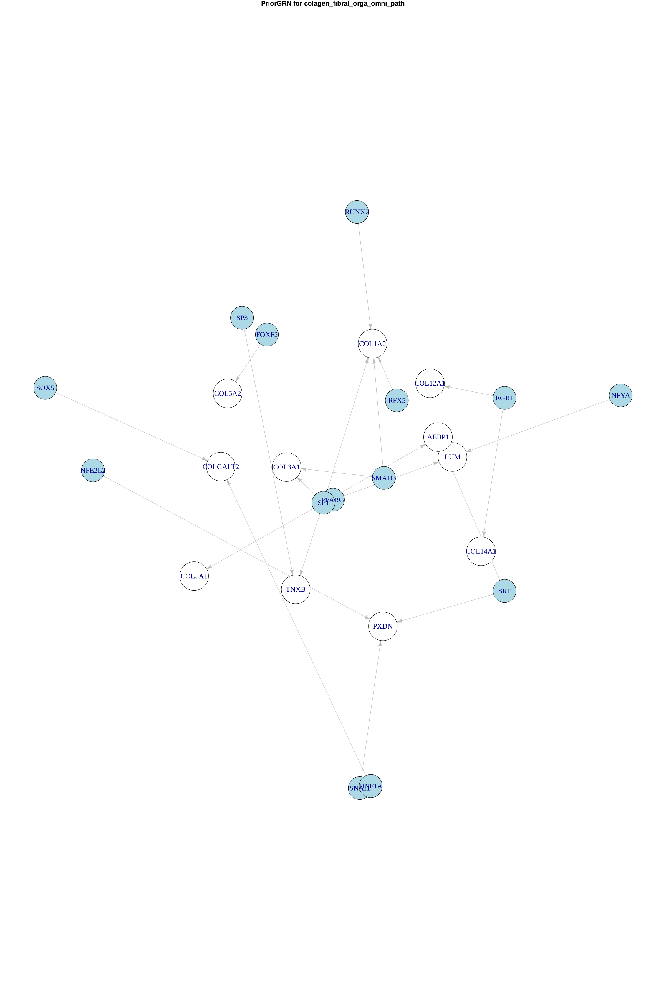

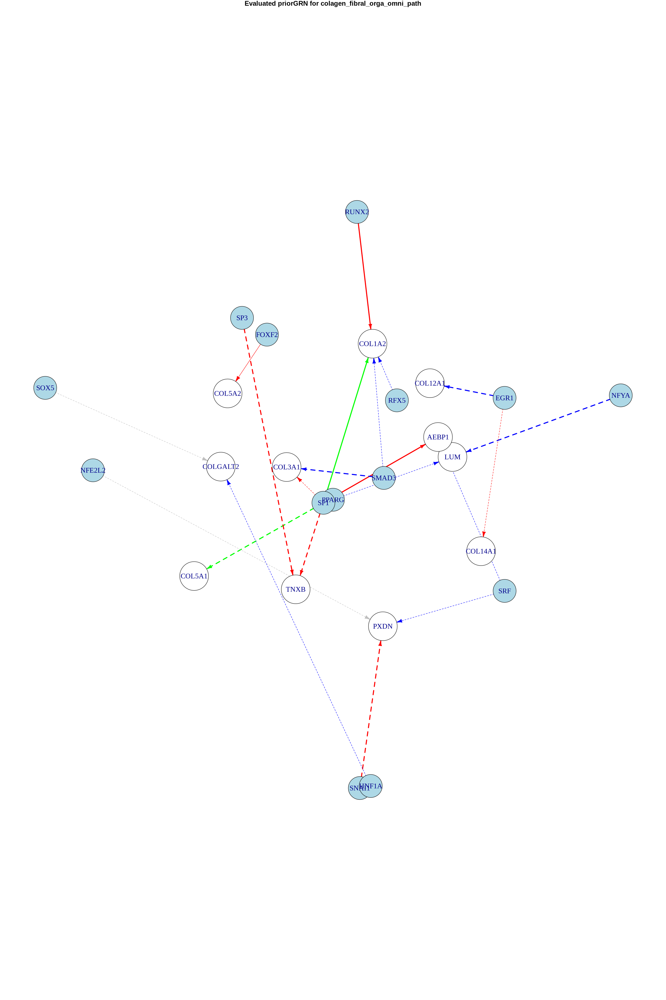

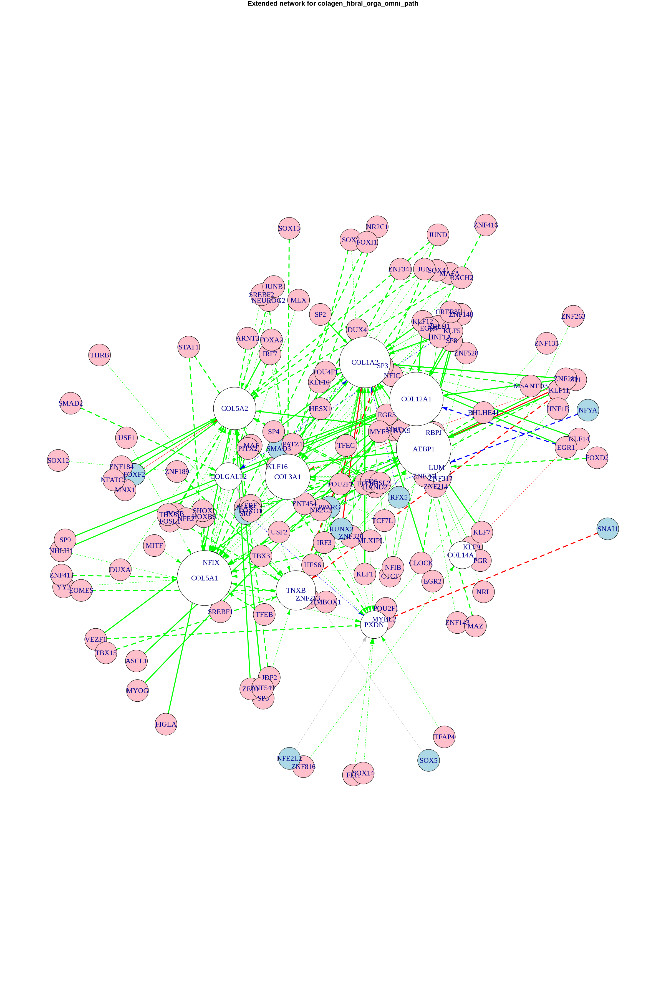

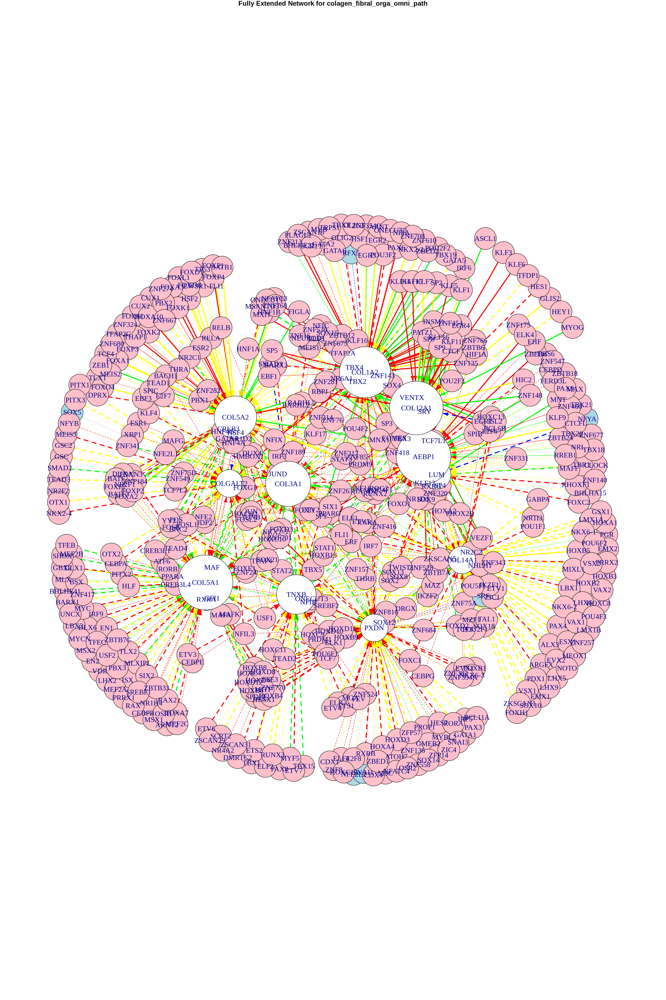

In [163]:

object_w_net<-draw_subNetwork_for_context(object=object_w_net, 
        gene_list= genes_of_interest,
        cluster.specific=TRUE,
        priorGRN=tf_gene_df,
        cluster="Fibroblast",
        context_name='colagen_fibral_orga_omni_path',resolution=20,pointsize=50, sd=5, score=-0.5
        )

In [133]:
str(object_w_net@misc$seedNetwork, max.level=1)

List of 2
 $ colagen_fibral_orga          :List of 19
 $ colagen_fibral_orga_omni_path:List of 11


In [ ]:
promoter.or.enriched	

In [144]:
colnames(object_w_net@misc$seedNetwork$colagen_fibral_orga_omni_path$COL5A1)

[1] "gene"                          "cluster"                      
 [3] "motif"                         "proximal.motif_count"         
 [5] "proximal.background_count"     "log2FC.proximal"              
 [7] "t_stat.proximal"               "p_value.proximal"             
 [9] "p_adjust.proximal"             "distal.motif_count"           
[11] "distal.background_count"       "log2FC.distal"                
[13] "t_stat.distal"                 "p_value.distal"               
[15] "p_adjust.distal"               "promoter.motif_count"         
[17] "footprint_score"               "bg_size"                      
[19] "bg_footprint_mean"             "footprint.t_stat"             
[21] "footprint.p_value"             "footprint.p_value_adj"        
[23] "sd.flanks"                     "bg_sd_mean"                   
[25] "left_flank_nonzero_positions"  "right_flank_nonzero_positions"
[27] "promoter.or.enriched"          "TF"                           
[29] "result"                        "priorTF"

In [157]:
head(object_w_net@misc$seedNetwork$colagen_fibral_orga_omni_path_cl_unsp$COL5A1[c("p_adjust.distal","log2FC.distal","footprint_score", "sd.flanks" , "bg_footprint_mean","left_flank_nonzero_positions", "right_flank_nonzero_positions", "footprint.p_value_adj",'promoter.or.enriched' )])

,p_adjust.distal,log2FC.distal,footprint_score,sd.flanks,bg_footprint_mean,left_flank_nonzero_positions,right_flank_nonzero_positions,footprint.p_value_adj,promoter.or.enriched
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<int>,<dbl>,<lgl>
COL5A1.SP1,1.000000e+00,-1.0238467,-1.4760,1.432,-0.593800,7,10,0.01300,FALSE
COL5A1.RXRA.5763,2.338799e-15,1.6438562,-0.3605,2.269,0.005923,5,3,1.00000,TRUE
COL5A1.RXRA.6266,9.056871e-19,2.0193653,-0.4904,2.586,0.279300,7,11,0.00031,TRUE
COL5A1.RXRA.6313,5.576139e-09,1.0389941,-0.1596,2.725,-0.122000,7,4,1.00000,TRUE
COL5A1.RXRA.5766,1.000000e+00,-Inf,NaN,NaN,NA,NA,NA,1.00000,FALSE
COL5A1.RXRA.5771,1.000000e+00,-0.6780719,-0.5176,5.333,-0.345700,2,3,1.00000,FALSE


In [159]:
object_w_net@misc$seedNetwork$colagen_fibral_orga_omni_path$COL1A2[object_w_net@misc$seedNetwork$colagen_fibral_orga_omni_path$COL1A2$TF=="SP1",][c("p_adjust.distal","log2FC.distal","footprint_score", "sd.flanks" , "bg_footprint_mean","left_flank_nonzero_positions", "right_flank_nonzero_positions", "footprint.p_value_adj" )]

,p_adjust.distal,log2FC.distal,footprint_score,sd.flanks,bg_footprint_mean,left_flank_nonzero_positions,right_flank_nonzero_positions,footprint.p_value_adj
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<int>,<dbl>
COL1A2.SP1,1.224211e-25,2.943416,-1.915,2.153,-0.2071,9,10,2.8e-17


In [161]:
colnames(object_w_net@misc$seedNetwork$colagen_fibral_orga_omni_path$COL1A2)

[1] "gene"                          "cluster"                      
 [3] "motif"                         "proximal.motif_count"         
 [5] "proximal.background_count"     "log2FC.proximal"              
 [7] "t_stat.proximal"               "p_value.proximal"             
 [9] "p_adjust.proximal"             "distal.motif_count"           
[11] "distal.background_count"       "log2FC.distal"                
[13] "t_stat.distal"                 "p_value.distal"               
[15] "p_adjust.distal"               "promoter.motif_count"         
[17] "footprint_score"               "bg_size"                      
[19] "bg_footprint_mean"             "footprint.t_stat"             
[21] "footprint.p_value"             "footprint.p_value_adj"        
[23] "sd.flanks"                     "bg_sd_mean"                   
[25] "left_flank_nonzero_positions"  "right_flank_nonzero_positions"
[27] "promoter.or.enriched"          "TF"                           
[29] "result"                        "priorTF"

In [162]:
object_w_net@misc$seedNetwork$colagen_fibral_orga_omni_path$COL1A2[object_w_net@misc$seedNetwork$colagen_fibral_orga_omni_path$COL1A2$TF=="SP1",10:30]

,distal.motif_count,distal.background_count,log2FC.distal,t_stat.distal,p_value.distal,p_adjust.distal,promoter.motif_count,footprint_score,bg_size,bg_footprint_mean,⋯,footprint.p_value,footprint.p_value_adj,sd.flanks,bg_sd_mean,left_flank_nonzero_positions,right_flank_nonzero_positions,promoter.or.enriched,TF,result,priorTF
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<int>,<lgl>,<chr>,<chr>,<lgl>
COL1A2.SP1,2,0.26,2.943416,-23.33693,1.700293e-28,1.224211e-25,7,-1.915,50,-0.2071,⋯,1.134e-19,2.8e-17,2.153,1.814,9,10,TRUE,SP1,red,TRUE


In [165]:
tf_gene_df

gene,TF
<chr>,<chr>
AEBP1,SP1
AEBP1,SRF
COL12A1,EGR1
COL14A1,EGR1
COL1A2,RFX5
COL1A2,RUNX2
COL1A2,SMAD3
COL1A2,SP1
COL3A1,SMAD3


In [22]:
p <- footprint_plots_by_TF(object=object_w_net, gene='COL1A2', cluster="Fibroblast", TF="RUNX2", path=NULL)

ggsave("objects_AVN_fibroblast/motif_plots/red_motifs/COL1A2_RUNX2_motif.png", plot = p, width = 10, height = 10)

TF provided, plotting all motifs for TF



[1] "2026-04-12 11:47:48 CEST"
GRanges object with 1 range and 1 metadata column:
      seqnames            ranges strand |     score
         <Rle>         <IRanges>  <Rle> | <numeric>
  [1]     chr7 94395463-94395471      + |   11.9797
  -------
  seqinfo: 24 sequences from an unspecified genome; no seqlengths


Warning message:
"The `slot` argument of `GetAssayData()` is deprecated as of SeuratObject 5.0.0.
ℹ Please use the `layer` argument instead."
Computing base composition at motif sites

Computing expected Tn5 insertions per base



[1] "2026-04-12 11:47:48 CEST"


Finding + strand cut sites

Finding - strand cut sites



[1] 1
[1] "1 1"


Computing observed Tn5 insertions per base

Computing base composition at motif sites



Computing expected Tn5 insertions per base

Finding + strand cut sites

Finding - strand cut sites

Warning message:
"Removed 1018 rows containing missing values or values outside the scale range
(`geom_label_repel()`)."


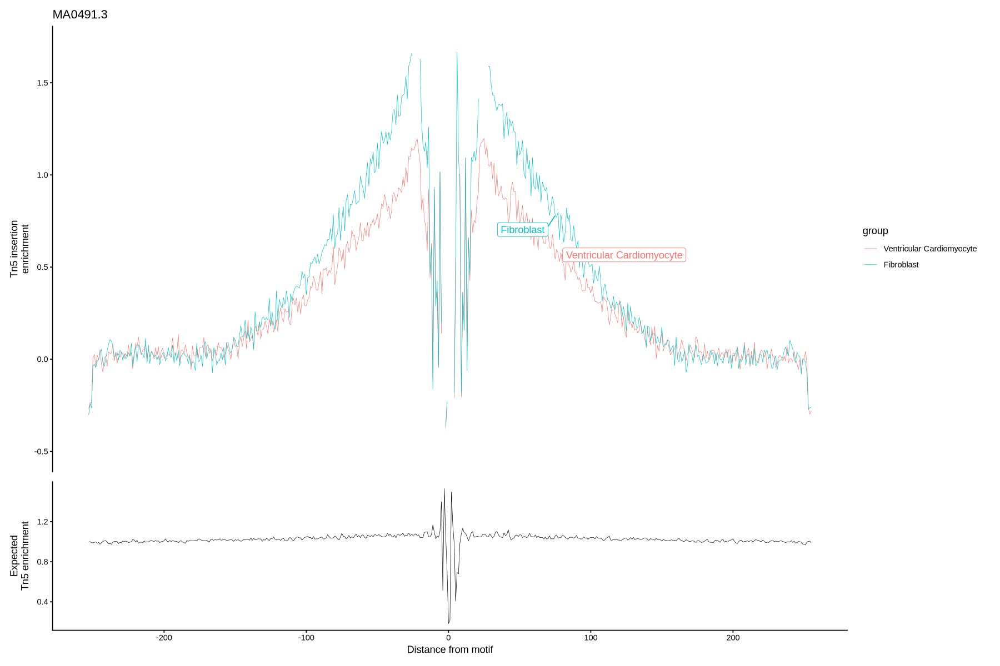

In [28]:
object_w_net <- Footprint(
  object = object_w_net,
  motif.name = "MA0491.3",
  genome = BSgenome.Hsapiens.UCSC.hg38
)

# plot the footprint data for each group of cells
PlotFootprint(object_w_net, features =  "MA0491.3",  idents = c("Fibroblast", "Ventricular Cardiomyocyte"))

In [17]:
options(repr.plot.width=15, repr.plot.height=10)

Computing observed Tn5 insertions per base



Computing base composition at motif sites

Computing expected Tn5 insertions per base

Finding + strand cut sites

Finding - strand cut sites

Warning message:
"Removed 3 rows containing missing values or values outside the scale range
(`geom_line()`)."
Warning message:
"Removed 5588 rows containing missing values or values outside the scale range
(`geom_label_repel()`)."


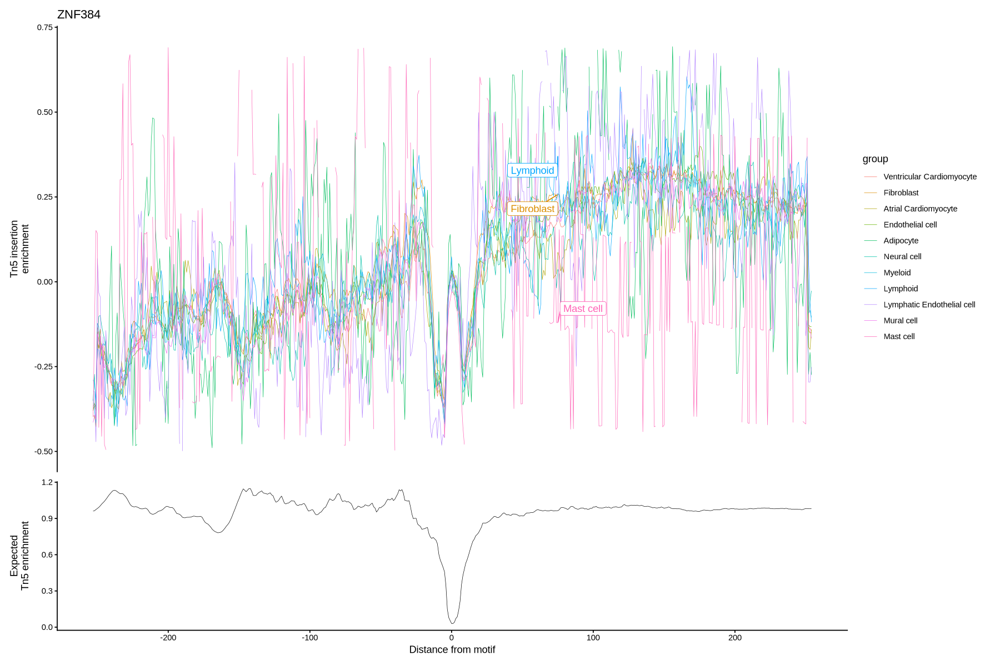

In [18]:
object_w_net <- Footprint(
  object = object_w_net,
  motif.name = "ZNF384",
  genome = BSgenome.Hsapiens.UCSC.hg38
)

# plot the footprint data for each group of cells
PlotFootprint(object_w_net, features = "ZNF384")

In [19]:
head(object_w_net@meta.data)

,orig.ident,nCount_RNA,nFeature_RNA,sangerID,combinedID,donor,donor_type,region,region_finest,age,⋯,peaks.weight,RNA_peaks_clusters_res0.1,RNA_peaks_clusters_res0.2,SCT.weight,SCT_peaks_clusters_res0.2,SCT_peaks_clusters_res0.1,nCount_ATAC,nFeature_ATAC,nCount_peaks,nFeature_peaks
,<fct>,<dbl>,<int>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,⋯,<dbl>,<fct>,<fct>,<dbl>,<fct>,<fct>,<dbl>,<int>,<dbl>,<int>
AGGTATTGTCTTTGAC-1,SeuratProject,19944,4928,HCAHeartST11350194,HCAHeartST11350194_HCAHeartST11445771,A61,DCD,AVN,AVN SEPT LAT,70-75,⋯,0.2416390,0,0,0.7583610,0,0,2608,1622,1217,1191
ACTTACTTCATTAGTG-1,SeuratProject,19892,5007,HCAHeartST11350194,HCAHeartST11350194_HCAHeartST11445771,A61,DCD,AVN,AVN SEPT LAT,70-75,⋯,0.6912932,0,0,0.3087068,0,0,9294,5532,4568,4250
CCTTCAATCAGCATTA-1,SeuratProject,19929,4824,HCAHeartST11350194,HCAHeartST11350194_HCAHeartST11445771,A61,DCD,AVN,AVN SEPT LAT,70-75,⋯,0.2689437,0,0,0.7310563,0,0,14115,8448,6494,5771
ATGTTGTCAATACTGT-1,SeuratProject,19826,4954,HCAHeartST11350194,HCAHeartST11350194_HCAHeartST11445771,A61,DCD,AVN,AVN SEPT LAT,70-75,⋯,0.5222465,0,0,0.4777535,0,0,23608,13756,10834,9293
CTTCAATTCATTTGTC-1,SeuratProject,19756,5088,HCAHeartST11350194,HCAHeartST11350194_HCAHeartST11445771,A61,DCD,AVN,AVN SEPT LAT,70-75,⋯,0.3046457,0,0,0.6953543,0,0,24830,14242,11717,9786
GGCTGGTTCGAAGTAG-1,SeuratProject,19690,4884,HCAHeartST11350194,HCAHeartST11350194_HCAHeartST11445771,A61,DCD,AVN,AVN SEPT LAT,70-75,⋯,0.3739443,0,0,0.6260557,4,4,2234,1387,986,977


In [37]:
options(repr.plot.width=8, repr.plot.height=6)

Warning message:
"Removed 1018 rows containing missing values or values outside the scale range
(`geom_label_repel()`)."


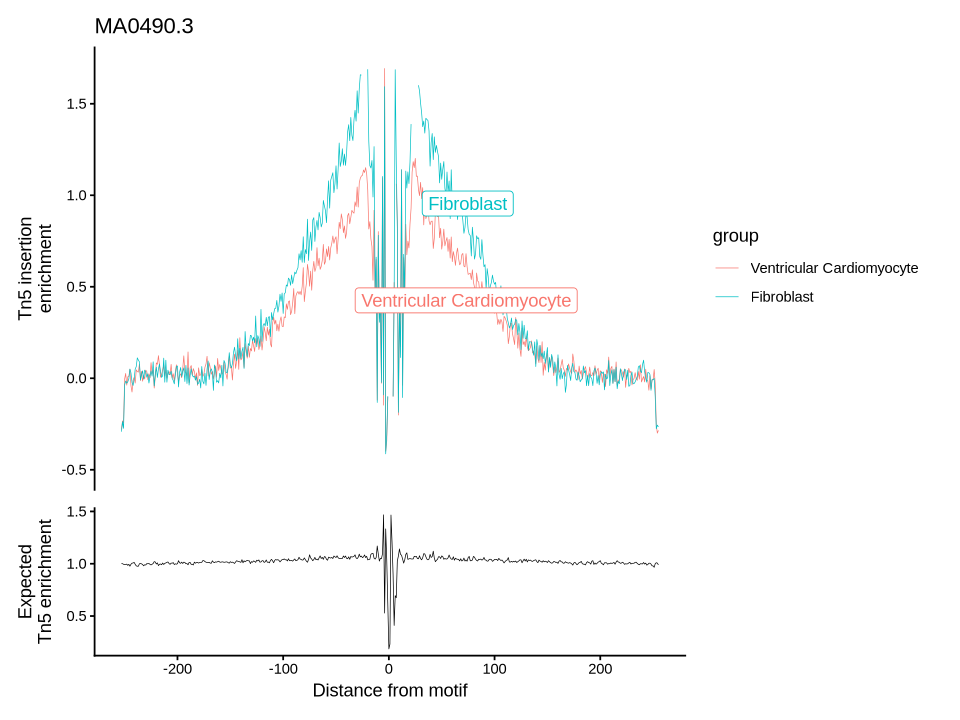

In [38]:
PlotFootprint(object_w_net, features = "MA0490.3",  idents = c("Fibroblast", "Ventricular Cardiomyocyte"))

Computing observed Tn5 insertions per base

Computing base composition at motif sites

Computing expected Tn5 insertions per base

Finding + strand cut sites

Finding - strand cut sites

Warning message:
"Removed 1018 rows containing missing values or values outside the scale range
(`geom_label_repel()`)."


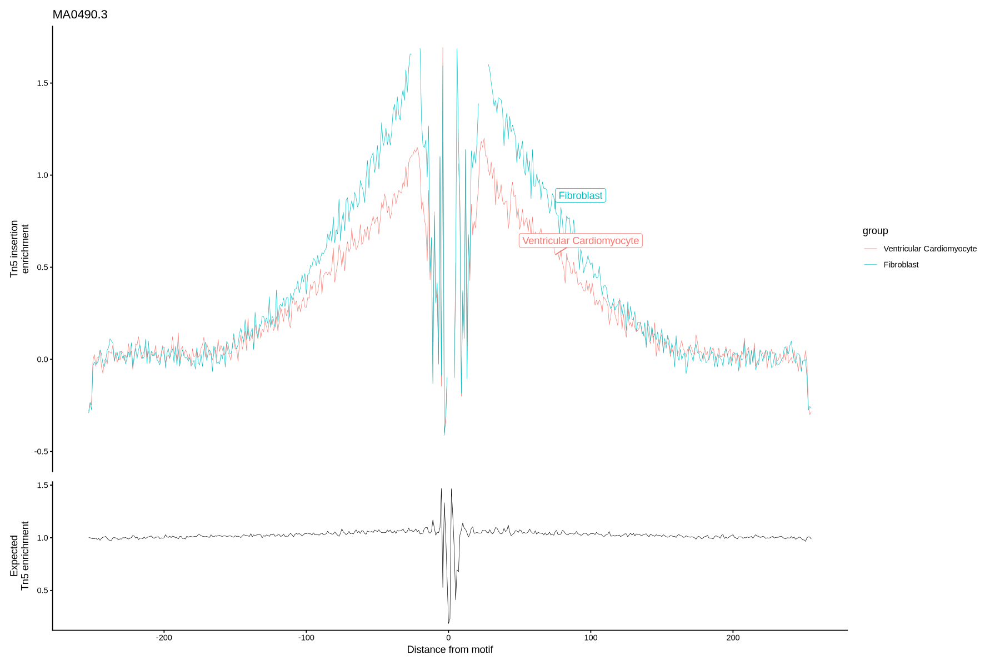

In [33]:
object_w_net <- Footprint(
  object = object_w_net,
  motif.name = "MA0490.3",
  genome = BSgenome.Hsapiens.UCSC.hg38
)

# plot the footprint data for each group of cells
PlotFootprint(object_w_net, features = "MA0490.3",  idents = c("Fibroblast", "Ventricular Cardiomyocyte"))

Warning message:
"Removed 1016 rows containing missing values or values outside the scale range
(`geom_label_repel()`)."


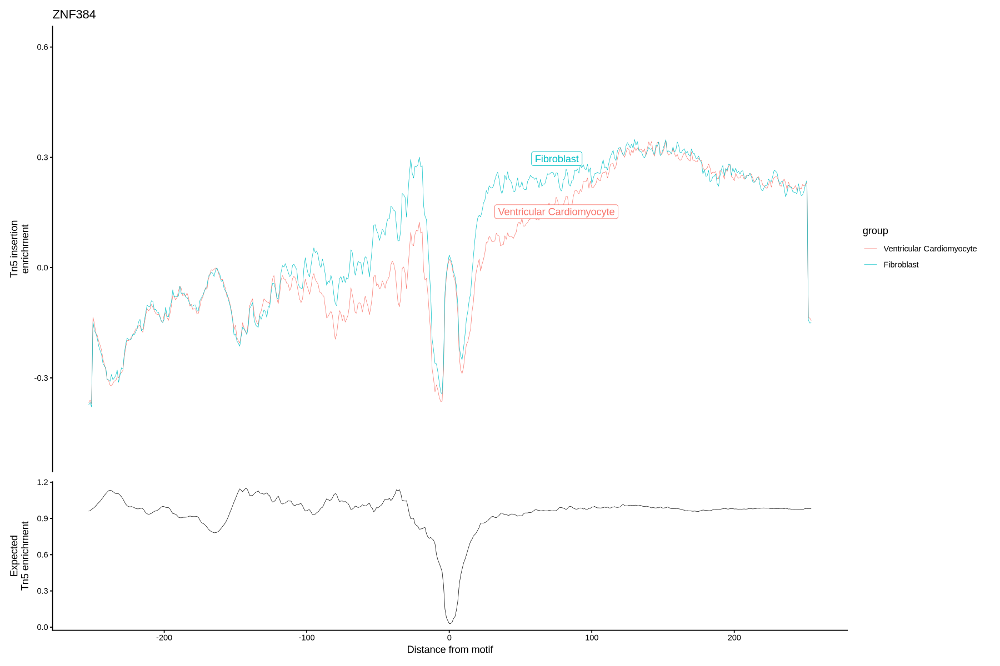

In [32]:
PlotFootprint(object_w_net, features = "ZNF384", idents = c("Fibroblast", "Ventricular Cardiomyocyte"))

TF provided, plotting all motifs for TF



[1] "2026-04-14 09:11:56 CEST"
GRanges object with 34 ranges and 1 metadata column:
       seqnames            ranges strand |     score
          <Rle>         <IRanges>  <Rle> | <numeric>
   [1]     chr7 94295873-94295880      + |   11.0136
   [2]     chr7 94297443-94297450      + |   11.3465
   [3]     chr7 94297573-94297580      - |   11.1163
   [4]     chr7 94297574-94297581      - |   13.5483
   [5]     chr7 94297575-94297582      - |   13.5483
   ...      ...               ...    ... .       ...
  [30]     chr7 94368290-94368297      + |   11.0136
  [31]     chr7 94368155-94368162      - |   11.0136
  [32]     chr7 94368246-94368253      - |   11.1163
  [33]     chr7 94368247-94368254      - |   13.5483
  [34]     chr7 94368248-94368255      - |   13.5483
  -------
  seqinfo: 24 sequences from an unspecified genome; no seqlengths


Computing base composition at motif sites

Computing expected Tn5 insertions per base



[1] "2026-04-14 09:11:56 CEST"


Finding + strand cut sites

Finding - strand cut sites



[1] 1
[1] "1 1"


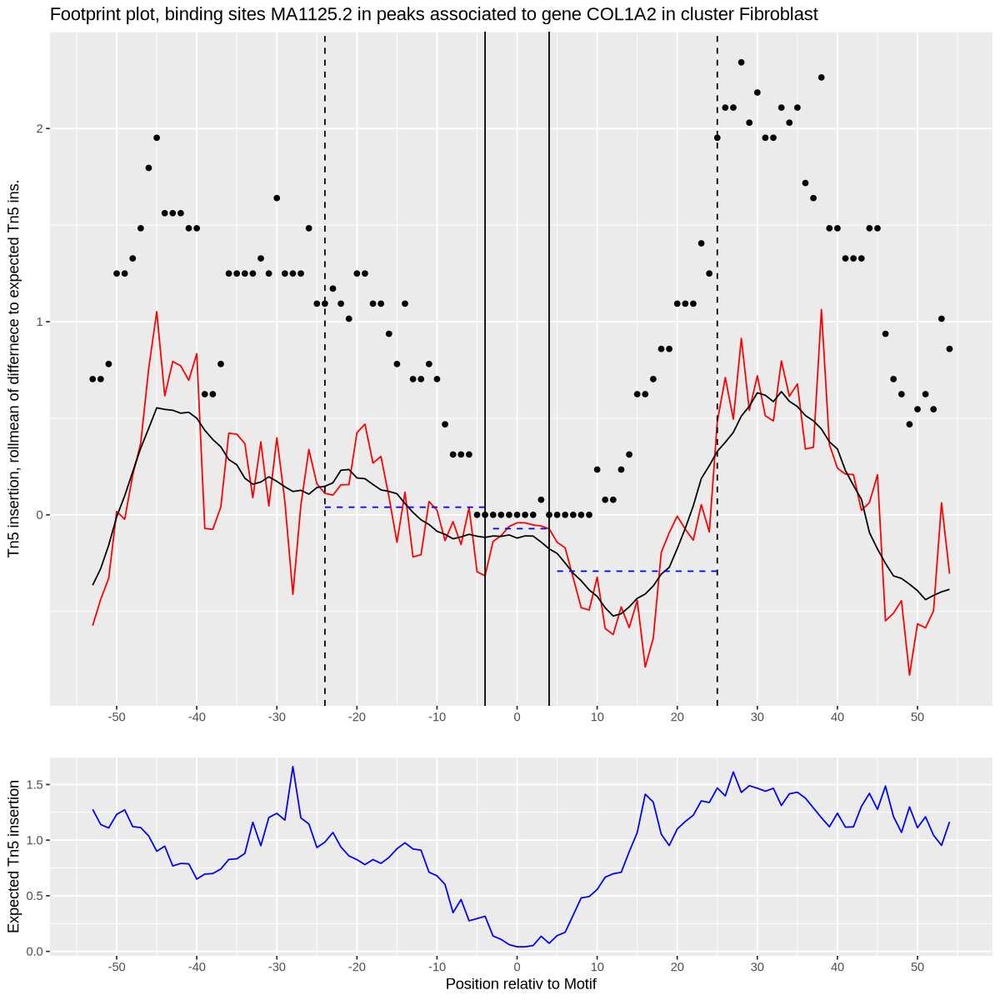

In [12]:
footprint_plots_by_TF(object=object_w_net, gene='COL1A2', cluster="Fibroblast", TF="ZNF384", path=NULL)

In [70]:
options(repr.plot.width=5, repr.plot.height=5)

[1] "2026-04-14 17:38:50 CEST"
GRanges object with 6 ranges and 1 metadata column:
      seqnames              ranges strand |     score
         <Rle>           <IRanges>  <Rle> | <numeric>
  [1]     chr2 189076810-189076818      + |   14.2486
  [2]     chr2 189076810-189076818      - |   13.0173
  [3]     chr2 189210374-189210382      + |   14.0024
  [4]     chr2 189210374-189210382      - |   14.9576
  [5]     chr2 189286423-189286431      + |   13.0173
  [6]     chr2 189286423-189286431      - |   14.2486
  -------
  seqinfo: 24 sequences from an unspecified genome; no seqlengths


Computing base composition at motif sites

Computing expected Tn5 insertions per base



[1] "2026-04-14 17:38:51 CEST"


Finding + strand cut sites

Finding - strand cut sites



[1] 1
[1] "1 1"


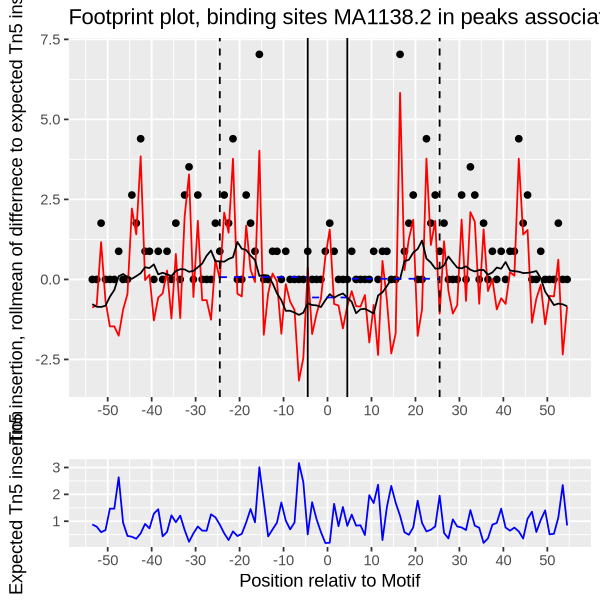

In [71]:
p<-footprint_plots_by_TF(object=object_w_net, gene='COL5A2', cluster="Fibroblast", motif_id="MA1138.2", path=NULL)
p

In [64]:
p<-footprint_plots_by_TF(object=object_w_net, gene='COL5A1', cluster="Fibroblast", motif_id="MA1138.2", path=NULL)
ggsave("/nfs/home/students/m.back/swarm/backend/uploads/job_1776009725832_mopitas_hvg_ctg_mygenes_celltg/junkDNA420/multiome/GRN_evaluation/initial_upload/collagen_fibril_orga/motif_plots/green_COL5A1_JUNB_MA1138.2_motif.png", plot = p, width = 10, height = 10)


[1] "2026-04-14 17:33:01 CEST"
GRanges object with 5 ranges and 1 metadata column:
      seqnames              ranges strand |     score
         <Rle>           <IRanges>  <Rle> | <numeric>
  [1]     chr9 134503028-134503036      - |   12.8140
  [2]     chr9 134527285-134527293      + |   12.3084
  [3]     chr9 134527285-134527293      - |   13.2636
  [4]     chr9 134544514-134544522      + |   14.0024
  [5]     chr9 134544514-134544522      - |   14.9576
  -------
  seqinfo: 24 sequences from an unspecified genome; no seqlengths


Computing base composition at motif sites

Computing expected Tn5 insertions per base



[1] "2026-04-14 17:33:01 CEST"


Finding + strand cut sites

Finding - strand cut sites



[1] 1
[1] "1 1"


[1] "2026-04-14 13:44:38 CEST"
GRanges object with 6 ranges and 1 metadata column:
      seqnames              ranges strand |     score
         <Rle>           <IRanges>  <Rle> | <numeric>
  [1]     chr2 189076810-189076818      + |   14.2486
  [2]     chr2 189076810-189076818      - |   13.0173
  [3]     chr2 189210374-189210382      + |   14.0024
  [4]     chr2 189210374-189210382      - |   14.9576
  [5]     chr2 189286423-189286431      + |   13.0173
  [6]     chr2 189286423-189286431      - |   14.2486
  -------
  seqinfo: 24 sequences from an unspecified genome; no seqlengths


Computing base composition at motif sites

Computing expected Tn5 insertions per base



[1] "2026-04-14 13:44:39 CEST"


Finding + strand cut sites

Finding - strand cut sites



[1] 1
[1] "1 1"


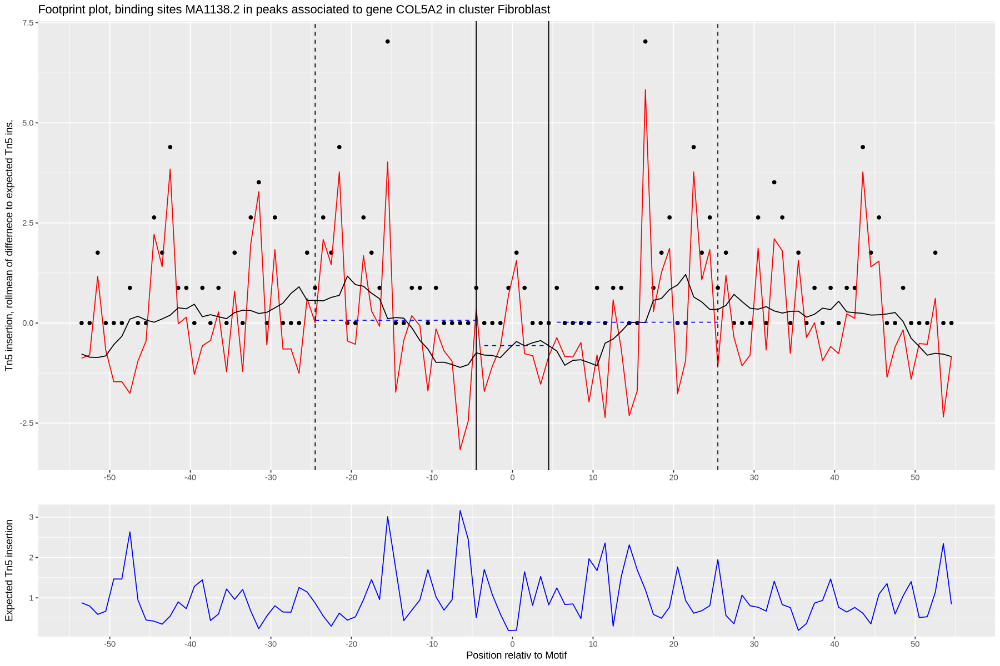

In [31]:
p<-footprint_plots_by_TF(object=object_w_net, gene='COL5A2', cluster="Fibroblast", motif_id="MA1138.2", path=NULL)
ggsave("/nfs/home/students/m.back/swarm/backend/uploads/job_1776009725832_mopitas_hvg_ctg_mygenes_celltg/junkDNA420/multiome/GRN_evaluation/initial_upload/collagen_fibril_orga/motif_plots/green_COL5A2_JUNB_MA1138.2_motif.png", plot = p, width = 10, height = 10)
p

TF provided, plotting all motifs for TF



[1] "2026-04-14 13:42:22 CEST"
GRanges object with 6 ranges and 1 metadata column:
      seqnames              ranges strand |     score
         <Rle>           <IRanges>  <Rle> | <numeric>
  [1]     chr2 189076810-189076818      + |   13.2739
  [2]     chr2 189076810-189076818      - |   14.2186
  [3]     chr2 189210374-189210382      + |   15.1539
  [4]     chr2 189210374-189210382      - |   14.1501
  [5]     chr2 189286423-189286431      + |   14.2186
  [6]     chr2 189286423-189286431      - |   13.2739
  -------
  seqinfo: 24 sequences from an unspecified genome; no seqlengths


Computing base composition at motif sites

Computing expected Tn5 insertions per base



[1] "2026-04-14 13:42:22 CEST"


Finding + strand cut sites

Finding - strand cut sites



[1] "2026-04-14 13:42:22 CEST"
GRanges object with 6 ranges and 1 metadata column:
      seqnames              ranges strand |     score
         <Rle>           <IRanges>  <Rle> | <numeric>
  [1]     chr2 189076810-189076818      + |   13.0567
  [2]     chr2 189076810-189076818      - |   11.0884
  [3]     chr2 189210374-189210382      + |   12.1061
  [4]     chr2 189210374-189210382      - |   13.7615
  [5]     chr2 189286423-189286431      + |   11.0884
  [6]     chr2 189286423-189286431      - |   13.0567
  -------
  seqinfo: 24 sequences from an unspecified genome; no seqlengths


... (8 outputs left out)

Computing base composition at motif sites

Computing expected Tn5 insertions per base



[1] "2026-04-14 13:42:24 CEST"


Finding + strand cut sites

Finding - strand cut sites



[1] 4
[1] "2 2"


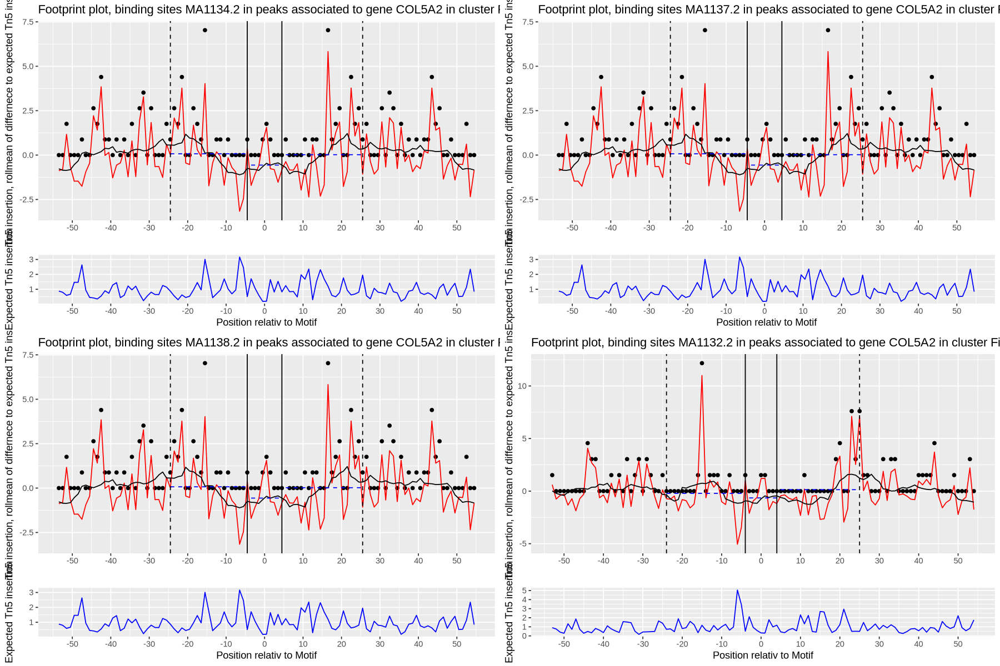

In [30]:
p<-footprint_plots_by_TF(object=object_w_net, gene='COL5A2', cluster="Fibroblast", TF="JUNB", path=NULL)
ggsave("/nfs/home/students/m.back/swarm/backend/uploads/job_1776009725832_mopitas_hvg_ctg_mygenes_celltg/junkDNA420/multiome/GRN_evaluation/initial_upload/collagen_fibril_orga/motif_plots/green_COL5A2_JUNB_motif.png", plot = p, width = 10, height = 10)
p

In [73]:
options(repr.plot.width=5, repr.plot.height=5)

TF provided, plotting all motifs for TF



[1] "2026-04-14 17:51:16 CEST"
GRanges object with 2 ranges and 1 metadata column:
      seqnames            ranges strand |     score
         <Rle>         <IRanges>  <Rle> | <numeric>
  [1]     chr7 94267042-94267049      + |   10.5476
  [2]     chr7 94375160-94375167      + |   14.0850
  -------
  seqinfo: 24 sequences from an unspecified genome; no seqlengths


Computing base composition at motif sites

Computing expected Tn5 insertions per base



[1] "2026-04-14 17:51:16 CEST"


Finding + strand cut sites

Finding - strand cut sites



[1] 1
[1] "1 1"


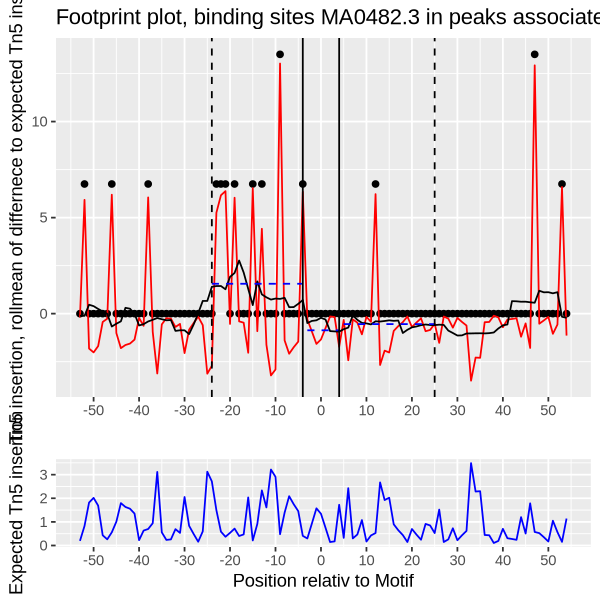

In [74]:
footprint_plots_by_TF(object=object_w_net, gene='COL1A2', cluster="Fibroblast", TF="GATA4", path=NULL)

TF provided, plotting all motifs for TF



[1] "2026-04-14 09:10:52 CEST"
GRanges object with 2 ranges and 1 metadata column:
      seqnames            ranges strand |     score
         <Rle>         <IRanges>  <Rle> | <numeric>
  [1]     chr7 94267042-94267049      + |   10.5476
  [2]     chr7 94375160-94375167      + |   14.0850
  -------
  seqinfo: 24 sequences from an unspecified genome; no seqlengths


Computing base composition at motif sites

Computing expected Tn5 insertions per base



[1] "2026-04-14 09:10:52 CEST"


Finding + strand cut sites

Finding - strand cut sites



[1] 1
[1] "1 1"


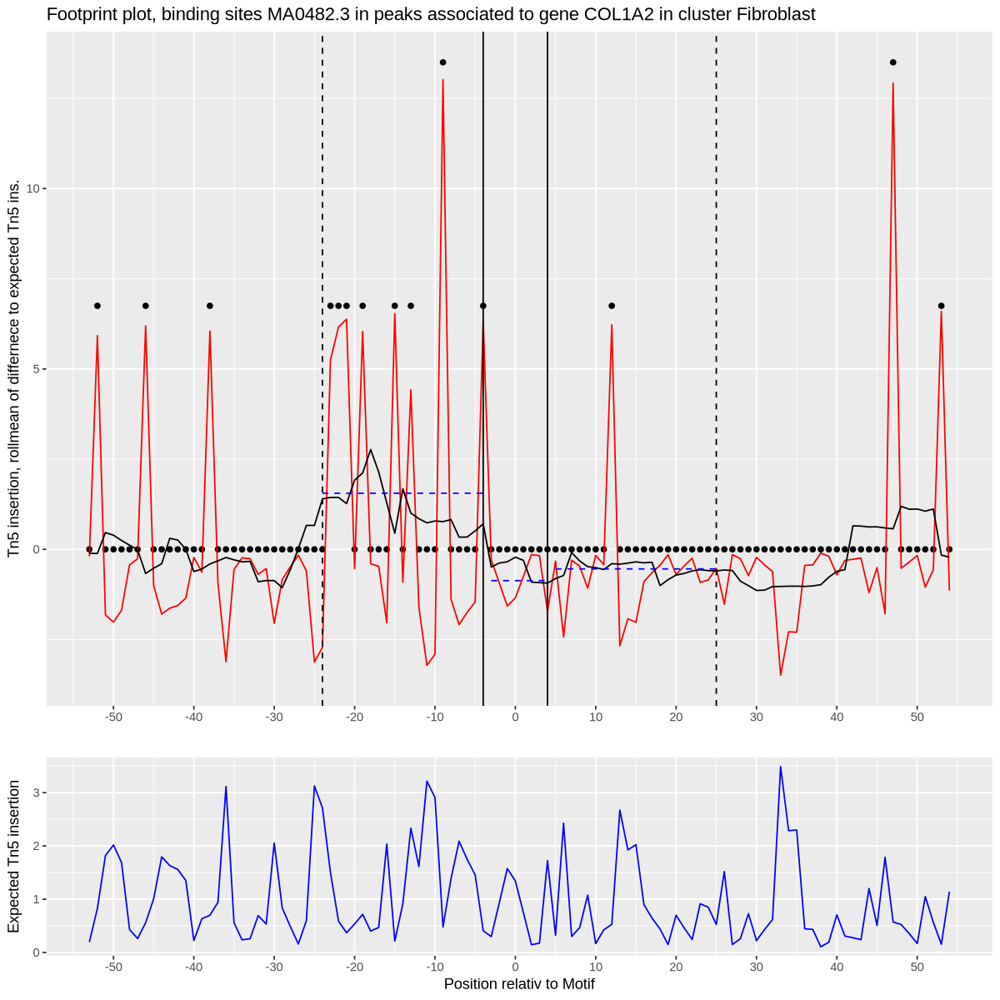

In [ ]:
p<-footprint_plots_by_TF(object=object_w_net, gene='COL1A2', cluster="Fibroblast", TF="GATA4", path=NULL)
ggsave("/nfs/home/students/m.back/swarm/backend/uploads/job_1776009725832_mopitas_hvg_ctg_mygenes_celltg/junkDNA420/multiome/GRN_evaluation/initial_upload/collagen_fibril_orga/motif_plots/red_COL1A2_GATA4_motif.png", plot = p, width = 10, height = 10)
p

In [80]:
options(repr.plot.width=10, repr.plot.height=10)

TF provided, plotting all motifs for TF



[1] "2026-04-14 17:58:45 CEST"
GRanges object with 5 ranges and 1 metadata column:
      seqnames            ranges strand |     score
         <Rle>         <IRanges>  <Rle> | <numeric>
  [1]     chr7 94394342-94394350      + |   17.3989
  [2]     chr7 94394363-94394371      + |   17.3989
  [3]     chr7 94394589-94394597      + |   14.9920
  [4]     chr7 94348184-94348192      + |   17.3989
  [5]     chr7 94348408-94348416      + |   15.9337
  -------
  seqinfo: 24 sequences from an unspecified genome; no seqlengths


Computing base composition at motif sites

Computing expected Tn5 insertions per base



[1] "2026-04-14 17:58:45 CEST"


Finding + strand cut sites

Finding - strand cut sites



[1] 1
[1] "1 1"


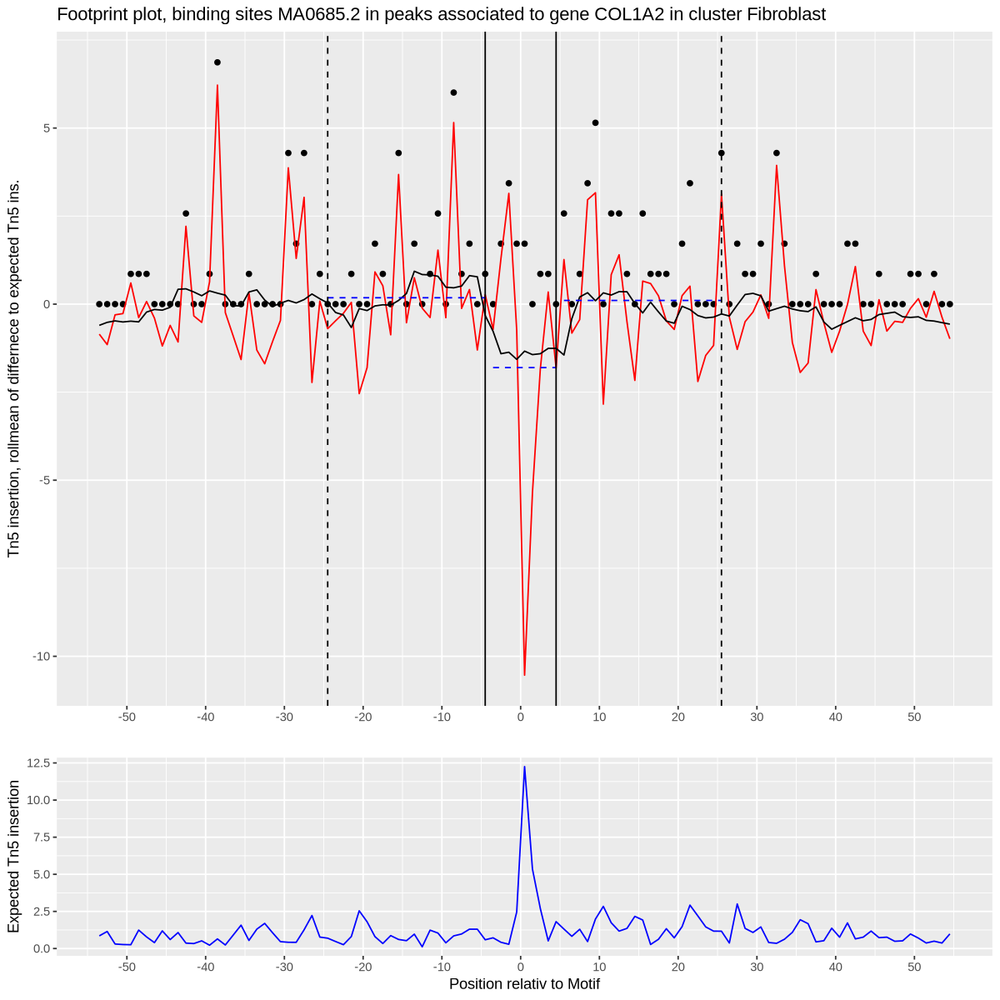

In [81]:
footprint_plots_by_TF(object=object_w_net, gene='COL1A2', cluster="Fibroblast", TF="SP4", path=NULL)

TF provided, plotting all motifs for TF



[1] "2026-04-14 17:52:16 CEST"
GRanges object with 4 ranges and 1 metadata column:
      seqnames            ranges strand |     score
         <Rle>         <IRanges>  <Rle> | <numeric>
  [1]     chr7 94394342-94394350      + |   17.6598
  [2]     chr7 94394363-94394371      + |   17.6598
  [3]     chr7 94348184-94348192      + |   17.6598
  [4]     chr7 94348408-94348416      + |   16.0106
  -------
  seqinfo: 24 sequences from an unspecified genome; no seqlengths


Computing base composition at motif sites

Computing expected Tn5 insertions per base



[1] "2026-04-14 17:52:16 CEST"


Finding + strand cut sites

Finding - strand cut sites



[1] 1
[1] "1 1"


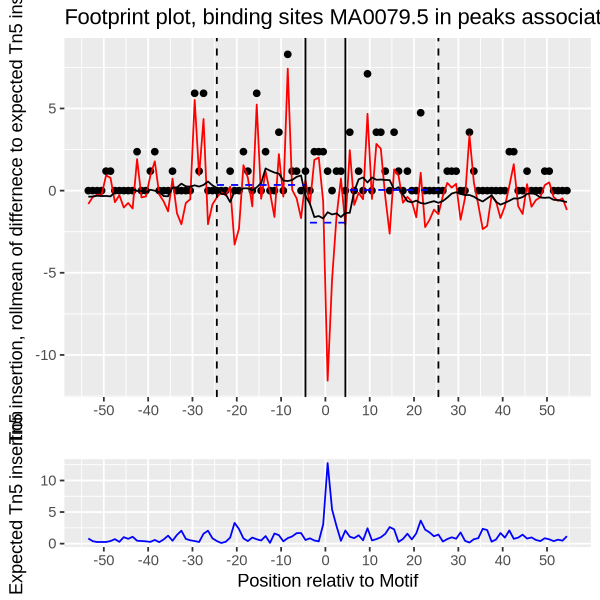

In [75]:
footprint_plots_by_TF(object=object_w_net, gene='COL1A2', cluster="Fibroblast", TF="SP1", path=NULL)

In [8]:
p<-footprint_plots_by_TF(object=object_w_net, gene='COL1A2', cluster="Fibroblast", TF="SP1", path=NULL)
ggsave("/nfs/home/students/m.back/swarm/backend/uploads/job_1776009725832_mopitas_hvg_ctg_mygenes_celltg/junkDNA420/multiome/GRN_evaluation/initial_upload/collagen_fibril_orga/motif_plots/green_COL1A2_SP1_motif.png", plot = p, width = 10, height = 10)

TF provided, plotting all motifs for TF



[1] "2026-04-14 09:05:08 CEST"
GRanges object with 4 ranges and 1 metadata column:
      seqnames            ranges strand |     score
         <Rle>         <IRanges>  <Rle> | <numeric>
  [1]     chr7 94394342-94394350      + |   17.6598
  [2]     chr7 94394363-94394371      + |   17.6598
  [3]     chr7 94348184-94348192      + |   17.6598
  [4]     chr7 94348408-94348416      + |   16.0106
  -------
  seqinfo: 24 sequences from an unspecified genome; no seqlengths


Computing base composition at motif sites

Computing expected Tn5 insertions per base



[1] "2026-04-14 09:05:08 CEST"


Finding + strand cut sites

Finding - strand cut sites



[1] 1
[1] "1 1"


In [24]:
p<-footprint_plots_by_TF(object=object_w_net, gene='AEBP1', cluster="Fibroblast", TF="SP1", path=NULL)
ggsave("objects_AVN_fibroblast/motif_plots/red_motifs/AEBP1_SP1_motif.png", plot = p, width = 10, height = 10)

TF provided, plotting all motifs for TF



[1] "2026-04-12 11:55:10 CEST"
GRanges object with 8 ranges and 1 metadata column:
      seqnames            ranges strand |     score
         <Rle>         <IRanges>  <Rle> | <numeric>
  [1]     chr7 44104127-44104135      - |   17.6598
  [2]     chr7 44104202-44104210      - |   17.6598
  [3]     chr7 44104216-44104224      - |   17.6598
  [4]     chr7 44104223-44104231      - |   17.6598
  [5]     chr7 44104230-44104238      - |   17.6598
  [6]     chr7 44104286-44104294      - |   14.2826
  [7]     chr7 44104329-44104337      - |   17.6598
  [8]     chr7 44088516-44088524      - |   15.9318
  -------
  seqinfo: 24 sequences from an unspecified genome; no seqlengths


Computing base composition at motif sites

Computing expected Tn5 insertions per base



[1] "2026-04-12 11:55:10 CEST"


Finding + strand cut sites

Finding - strand cut sites



[1] 1
[1] "1 1"


In [49]:
options(repr.plot.width=10, repr.plot.height=10)

In [50]:
p<-footprint_plots_by_TF(object=object_w_net, gene='AEBP1', cluster="Fibroblast", TF="SP1", path=NULL)

TF provided, plotting all motifs for TF



[1] "2026-04-13 21:15:53 CEST"
GRanges object with 8 ranges and 1 metadata column:
      seqnames            ranges strand |     score
         <Rle>         <IRanges>  <Rle> | <numeric>
  [1]     chr7 44104127-44104135      - |   17.6598
  [2]     chr7 44104202-44104210      - |   17.6598
  [3]     chr7 44104216-44104224      - |   17.6598
  [4]     chr7 44104223-44104231      - |   17.6598
  [5]     chr7 44104230-44104238      - |   17.6598
  [6]     chr7 44104286-44104294      - |   14.2826
  [7]     chr7 44104329-44104337      - |   17.6598
  [8]     chr7 44088516-44088524      - |   15.9318
  -------
  seqinfo: 24 sequences from an unspecified genome; no seqlengths


Computing base composition at motif sites

Computing expected Tn5 insertions per base



[1] "2026-04-13 21:15:54 CEST"


Finding + strand cut sites

Finding - strand cut sites



[1] 1
[1] "1 1"


In [53]:
str(object_w_net@misc, max.level=1)

List of 12
 $ markers.annotated        :'data.frame':	4075 obs. of  8 variables:
 $ peak_stats               :'data.frame':	130 obs. of  51 variables:
 $ peak_stats.filtered      :'data.frame':	122 obs. of  51 variables:
 $ motifs.inProximalPeaks   :List of 23
 $ motifs.inDistalPeaks     :List of 23
 $ motif_enrichment         :'data.frame':	16560 obs. of  16 variables:
 $ filtered.motif_enrichment:'data.frame':	3290 obs. of  16 variables:
 $ motif_stats              :'data.frame':	3290 obs. of  26 variables:
 $ motif2TF                 :List of 720
 $ TF2motif                 :List of 668
 $ seedNetwork              :List of 5
 $ context_subNetwork       :List of 5


In [54]:

ggsave("objects_AVN_fibroblast/motif_plots/red_motifs/AEBP1_SP1_motif.png", plot = p, width = 10, height = 10)

TF provided, plotting all motifs for TF



[1] "2026-04-13 21:25:35 CEST"
GRanges object with 3 ranges and 1 metadata column:
      seqnames              ranges strand |     score
         <Rle>           <IRanges>  <Rle> | <numeric>
  [1]     chr2 188966875-188966880      + |   10.8135
  [2]     chr2 189021992-189021997      + |   10.8135
  [3]     chr2 189093079-189093084      - |   10.8135
  -------
  seqinfo: 24 sequences from an unspecified genome; no seqlengths


Computing base composition at motif sites

Computing expected Tn5 insertions per base



[1] "2026-04-13 21:25:36 CEST"


Finding + strand cut sites

Finding - strand cut sites



[1] 1
[1] "1 1"


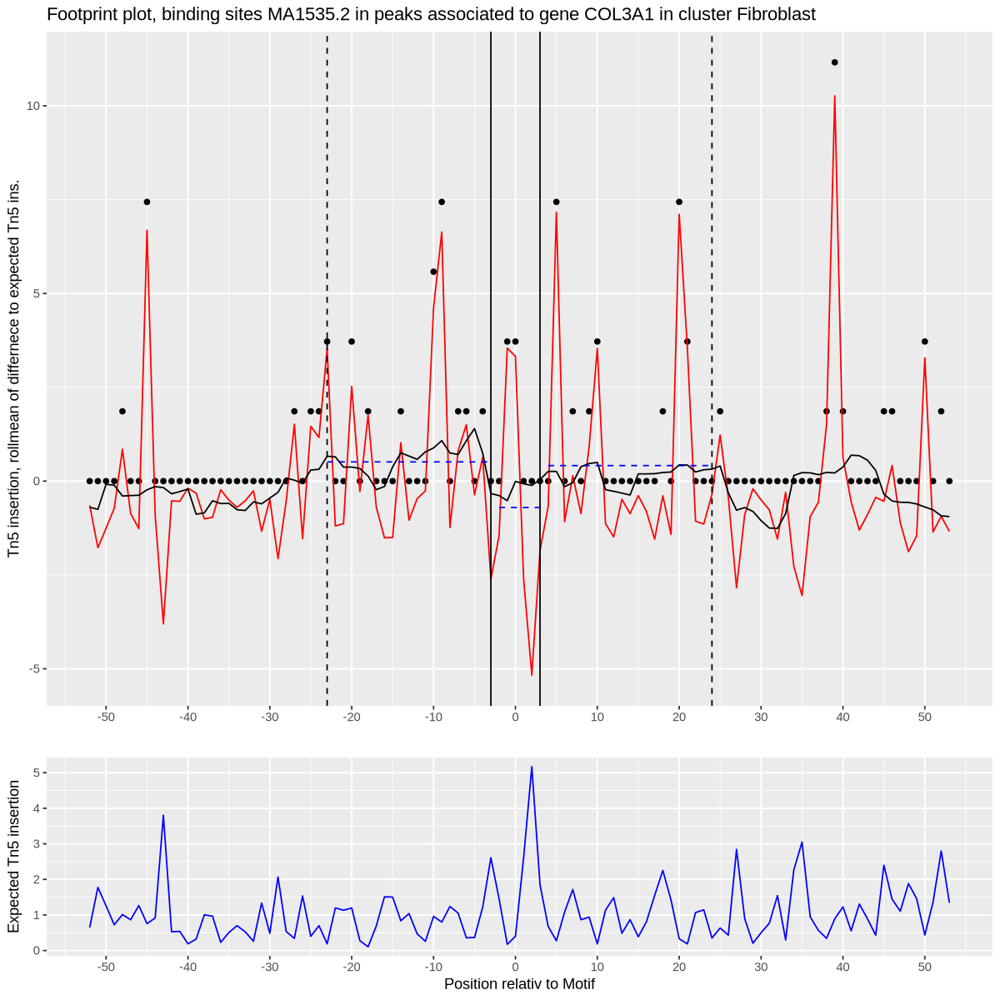

In [58]:
footprint_plots_by_TF(object=object_w_net, gene='COL3A1', cluster="Fibroblast", TF="NR2C1", path=NULL)

TF provided, plotting all motifs for TF



[1] "2026-04-13 21:24:29 CEST"
GRanges object with 3 ranges and 1 metadata column:
      seqnames            ranges strand |     score
         <Rle>         <IRanges>  <Rle> | <numeric>
  [1]     chr7 94394340-94394350      - |   14.6389
  [2]     chr7 94394361-94394371      - |   13.2826
  [3]     chr7 94348182-94348192      - |   16.0303
  -------
  seqinfo: 24 sequences from an unspecified genome; no seqlengths


Computing base composition at motif sites

Computing expected Tn5 insertions per base



[1] "2026-04-13 21:24:29 CEST"


Finding + strand cut sites

Finding - strand cut sites



[1] 1
[1] "1 1"


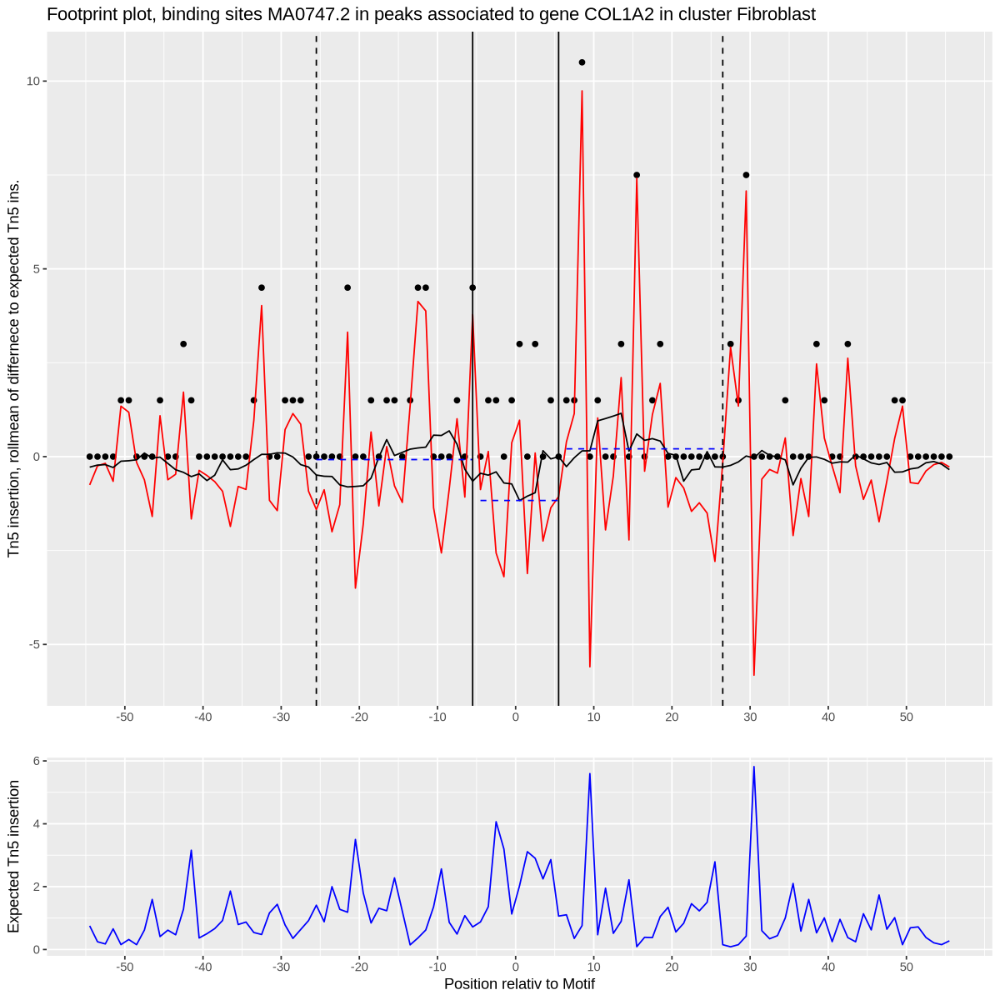

In [57]:
footprint_plots_by_TF(object=object_w_net, gene='COL1A2', cluster="Fibroblast", TF="SP8", path=NULL)

TF provided, plotting all motifs for TF



[1] "2026-04-11 15:51:11 CEST"
GRanges object with 8 ranges and 1 metadata column:
      seqnames            ranges strand |     score
         <Rle>         <IRanges>  <Rle> | <numeric>
  [1]     chr7 44104127-44104135      - |   17.6598
  [2]     chr7 44104202-44104210      - |   17.6598
  [3]     chr7 44104216-44104224      - |   17.6598
  [4]     chr7 44104223-44104231      - |   17.6598
  [5]     chr7 44104230-44104238      - |   17.6598
  [6]     chr7 44104286-44104294      - |   14.2826
  [7]     chr7 44104329-44104337      - |   17.6598
  [8]     chr7 44088516-44088524      - |   15.9318
  -------
  seqinfo: 24 sequences from an unspecified genome; no seqlengths


Computing base composition at motif sites

Computing expected Tn5 insertions per base



[1] "2026-04-11 15:51:11 CEST"


Finding + strand cut sites

Finding - strand cut sites



[1] 1
[1] "1 1"


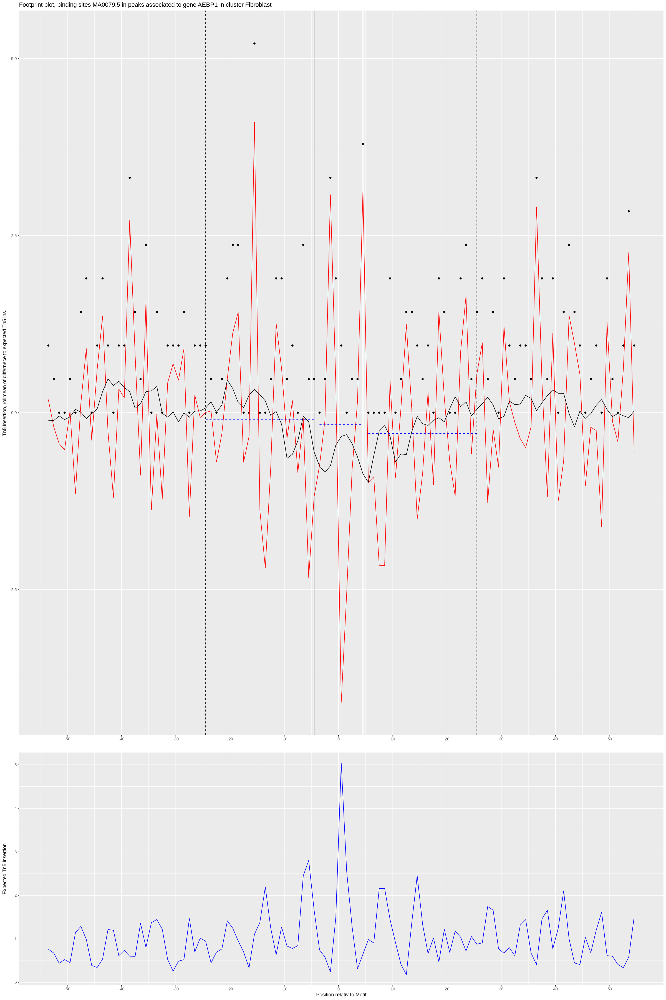

In [166]:
footprint_plots_by_TF(object=object_w_net, gene='AEBP1', cluster="Fibroblast", TF="SP1", path=NULL)

In [22]:
p<-footprint_plots_by_TF(object=object_w_net, gene='COL6A1', cluster="Fibroblast", TF="SP1", path=NULL)
ggsave("/nfs/home/students/m.back/swarm/backend/uploads/job_1776009725832_mopitas_hvg_ctg_mygenes_celltg/junkDNA420/multiome/GRN_evaluation/initial_upload/collagen_fibril_orga/motif_plots/green_COL6A1_SP1_motif.png", p, width = 10, height = 10)

TF provided, plotting all motifs for TF



[1] "2026-04-13 22:53:45 CEST"
GRanges object with 16 ranges and 1 metadata column:
       seqnames            ranges strand |     score
          <Rle>         <IRanges>  <Rle> | <numeric>
   [1]    chr21 45893778-45893786      + |   15.9318
   [2]    chr21 45894356-45894364      + |   14.2826
   [3]    chr21 45972666-45972674      - |   15.9318
   [4]    chr21 45974694-45974702      + |   15.9318
   [5]    chr21 45975061-45975069      + |   15.9318
   ...      ...               ...    ... .       ...
  [12]    chr21 46098071-46098079      + |   17.6598
  [13]    chr21 46098432-46098440      + |   16.0106
  [14]    chr21 46098651-46098659      + |   17.6598
  [15]    chr21 46098658-46098666      + |   14.2826
  [16]    chr21 46098698-46098706      + |   15.9318
  -------
  seqinfo: 24 sequences from an unspecified genome; no seqlengths


Computing base composition at motif sites

Computing expected Tn5 insertions per base



[1] "2026-04-13 22:53:46 CEST"


Finding + strand cut sites

Finding - strand cut sites



[1] 1
[1] "1 1"


TF provided, plotting all motifs for TF



[1] "2026-04-13 23:14:22 CEST"
GRanges object with 9 ranges and 1 metadata column:
      seqnames              ranges strand |     score
         <Rle>           <IRanges>  <Rle> | <numeric>
  [1]     chr1 203351245-203351253      + |   16.0106
  [2]     chr1 203351166-203351174      - |   15.0104
  [3]     chr1 203475684-203475692      - |   14.2826
  [4]     chr1 203475689-203475697      - |   15.9318
  [5]     chr1 203475717-203475725      - |   14.2826
  [6]     chr1 203487744-203487752      + |   17.6598
  [7]     chr1 203487854-203487862      + |   16.0106
  [8]     chr1 203487182-203487190      - |   14.2826
  [9]     chr1 203487767-203487775      - |   17.6598
  -------
  seqinfo: 24 sequences from an unspecified genome; no seqlengths


Computing base composition at motif sites

Computing expected Tn5 insertions per base



[1] "2026-04-13 23:14:23 CEST"


Finding + strand cut sites

Finding - strand cut sites



[1] 1
[1] "1 1"


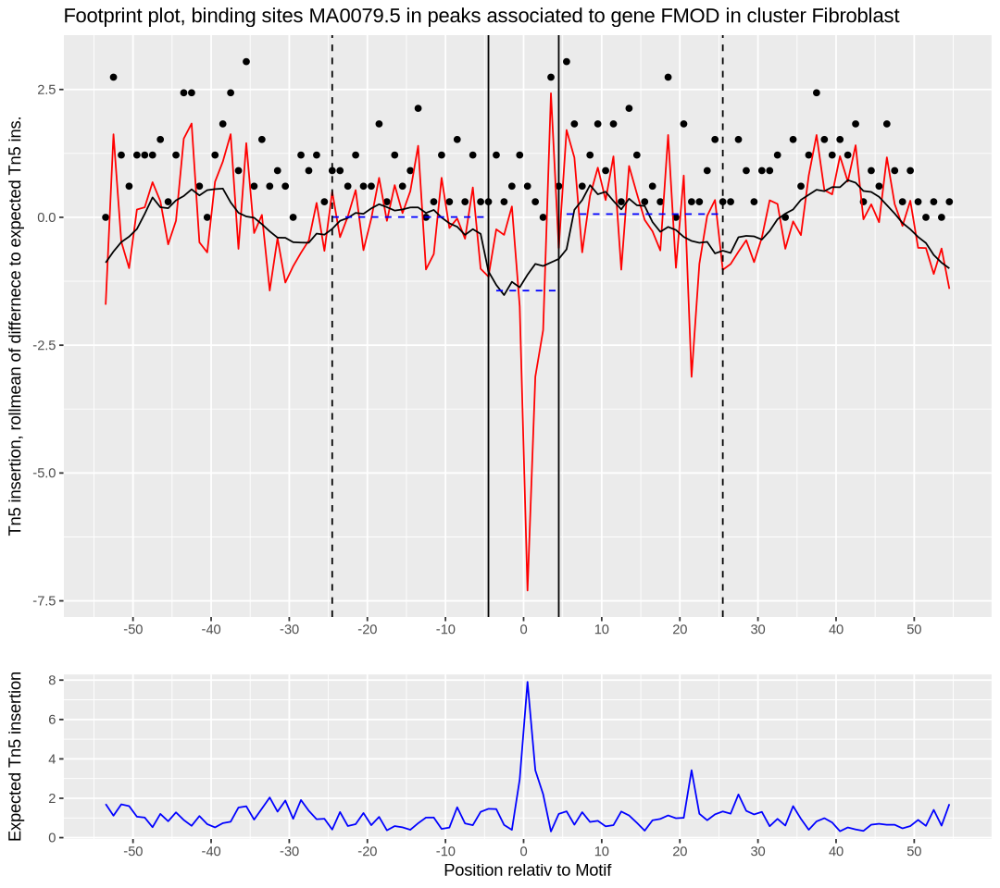

In [25]:
footprint_plots_by_TF(object=object_w_net, gene='FMOD', cluster="Fibroblast", TF="SP1", path=NULL)

TF provided, plotting all motifs for TF



[1] "2026-04-11 15:36:35 CEST"
GRanges object with 4 ranges and 1 metadata column:
      seqnames            ranges strand |     score
         <Rle>         <IRanges>  <Rle> | <numeric>
  [1]     chr7 94394342-94394350      + |   17.6598
  [2]     chr7 94394363-94394371      + |   17.6598
  [3]     chr7 94348184-94348192      + |   17.6598
  [4]     chr7 94348408-94348416      + |   16.0106
  -------
  seqinfo: 24 sequences from an unspecified genome; no seqlengths


Computing base composition at motif sites

Computing expected Tn5 insertions per base



[1] "2026-04-11 15:36:35 CEST"


Finding + strand cut sites

Finding - strand cut sites



[1] 1
[1] "1 1"


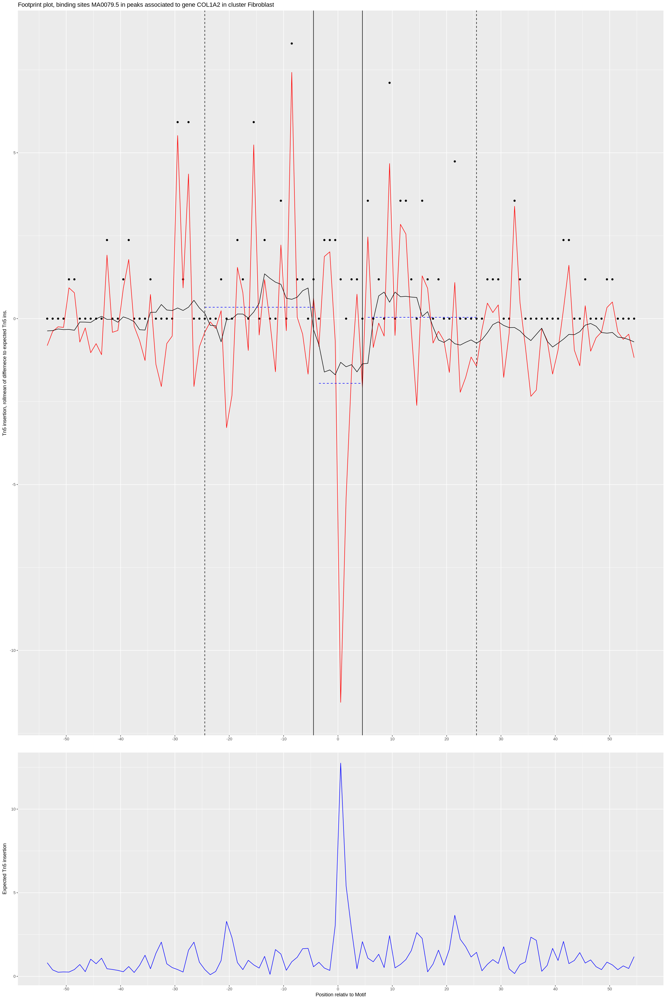

In [154]:
footprint_plots_by_TF(object=object_w_net, gene='COL1A2', cluster="Fibroblast", TF="SP1", path=NULL)

In [25]:
p<-footprint_plots_by_TF(object=object_w_net, gene='COL5A1', cluster="Fibroblast", TF="SP1", path=NULL)
ggsave("objects_AVN_fibroblast/motif_plots/green_motifs/COL5A1_SP1_motif.png", plot = p, width = 10, height = 10)

TF provided, plotting all motifs for TF



[1] "2026-04-12 11:56:28 CEST"
GRanges object with 3 ranges and 1 metadata column:
      seqnames              ranges strand |     score
         <Rle>           <IRanges>  <Rle> | <numeric>
  [1]     chr9 134546059-134546067      - |   15.9318
  [2]     chr9 134724480-134724488      - |   16.0106
  [3]     chr9 134735480-134735488      + |   15.0104
  -------
  seqinfo: 24 sequences from an unspecified genome; no seqlengths


Computing base composition at motif sites

Computing expected Tn5 insertions per base



[1] "2026-04-12 11:56:28 CEST"


Finding + strand cut sites

Finding - strand cut sites



[1] 1
[1] "1 1"


TF provided, plotting all motifs for TF



[1] "2026-04-11 13:59:43 CEST"
GRanges object with 3 ranges and 1 metadata column:
      seqnames              ranges strand |     score
         <Rle>           <IRanges>  <Rle> | <numeric>
  [1]     chr9 134546059-134546067      - |   15.9318
  [2]     chr9 134724480-134724488      - |   16.0106
  [3]     chr9 134735480-134735488      + |   15.0104
  -------
  seqinfo: 24 sequences from an unspecified genome; no seqlengths


Computing base composition at motif sites

Computing expected Tn5 insertions per base



[1] "2026-04-11 13:59:43 CEST"


Finding + strand cut sites

Finding - strand cut sites



[1] 1
[1] "1 1"


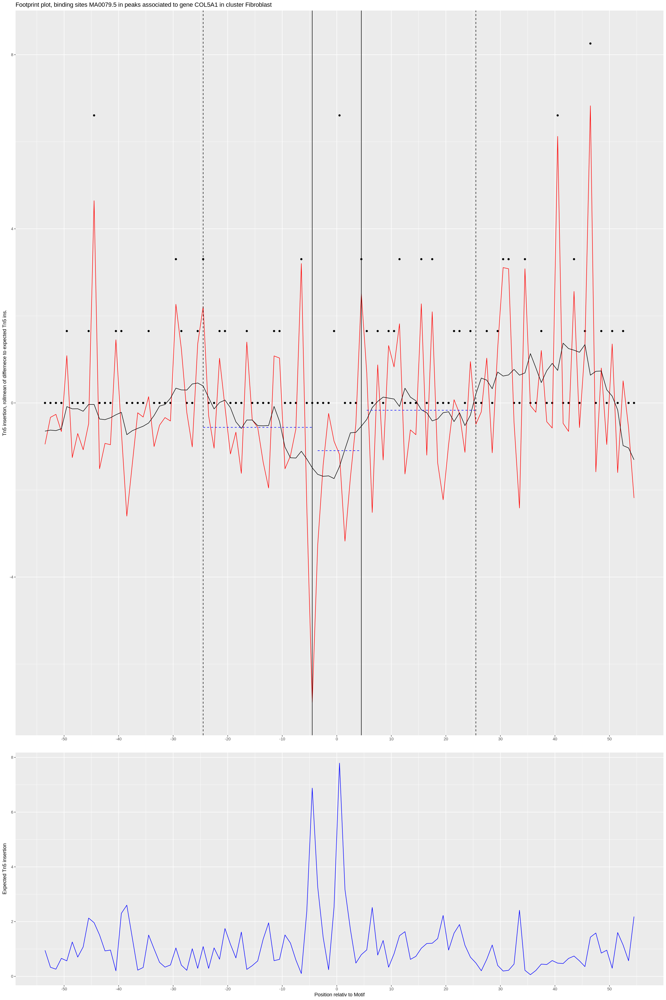

In [124]:
footprint_plots_by_TF(object=object_w_net, gene='COL5A1', cluster="Fibroblast", TF="SP1", path=NULL)

In [62]:
str(object_w_net@misc, max.level=1)

List of 12
 $ markers.annotated        :'data.frame':	4075 obs. of  8 variables:
 $ peak_stats               :'data.frame':	130 obs. of  51 variables:
 $ peak_stats.filtered      :'data.frame':	122 obs. of  51 variables:
 $ motifs.inProximalPeaks   :List of 23
 $ motifs.inDistalPeaks     :List of 23
 $ motif_enrichment         :'data.frame':	16560 obs. of  16 variables:
 $ filtered.motif_enrichment:'data.frame':	3290 obs. of  16 variables:
 $ motif_stats              :'data.frame':	3290 obs. of  26 variables:
 $ motif2TF                 :List of 720
 $ TF2motif                 :List of 668
 $ seedNetwork              :List of 1
 $ context_subNetwork       :List of 1


In [81]:
result_summary <- object_w_net@misc$context_subNetwork$colagen_fibral_orga

In [92]:
unique(result_summary$to)

[1] "TLL1"     "PLOD1"    "LOXL3"    "LUM"      "RB1"      "DPT"     
 [7] "ADAMTS19" "VIPAS39"  "NF1"      "AEBP1"    "COL1A2"   "COL3A1"  
[13] "COL5A1"   "COL5A2"   "COL12A1"  "TNXB"     "COL14A1"  "PXDN"    
[19] "COLGALT2"

In [14]:
saveRDS(object_w_net, "objects_AVN_fibroblast/final_object_w_net.rds")

In [93]:
result_summary[result_summary$color=="green" & result_summary$to=="COL5A1",]

,from,to,color,priorTF,reg_type,in.prom
,<chr>,<chr>,<chr>,<lgl>,<int>,<int>
COL5A1.3,DUX4,COL5A1,green,FALSE,2,3
COL5A1.17,TFE3,COL5A1,green,FALSE,2,1
COL5A1.26,JUN,COL5A1,green,FALSE,2,1
COL5A1.47,FOS,COL5A1,green,FALSE,2,1
COL5A1.49,JUND,COL5A1,green,FALSE,2,1
COL5A1.52,FOSL2,COL5A1,green,FALSE,2,1
COL5A1.86,NFIB,COL5A1,green,FALSE,2,1
COL5A1.88,NFIX,COL5A1,green,FALSE,2,3
COL5A1.104,STAT1,COL5A1,green,FALSE,2,3


In [121]:
result_summary[result_summary$color=="green",]

,from,to,color,priorTF,reg_type,in.prom
,<chr>,<chr>,<chr>,<lgl>,<int>,<int>
AEBP1.3,KLF16,AEBP1,green,FALSE,1,3
AEBP1.32,KLF11,AEBP1,green,FALSE,1,3
AEBP1.49,RREB1,AEBP1,green,FALSE,1,1
AEBP1.50,SP3,AEBP1,green,FALSE,1,3
AEBP1.61,ZNF148,AEBP1,green,FALSE,1,3
AEBP1.64,ZNF281,AEBP1,green,FALSE,1,3
AEBP1.65,ZNF320,AEBP1,green,FALSE,1,1
COL1A2.5,KLF5,COL1A2,green,FALSE,1,3
COL1A2.23,ZNF213,COL1A2,green,FALSE,1,1


In [103]:
options(repr.plot.width=20, repr.plot.height=30)

In [109]:
source("../multiome_methods/binding_site_identification.r")

In [26]:
p<-footprint_plots_by_TF(object=object_w_net, gene='COL5A1', cluster="Fibroblast", TF="FOSL2", path=NULL)
ggsave("objects_AVN_fibroblast/motif_plots/green_motifs/COL5A1_FOSL2_motif.png", plot = p, width = 20, height = 40)

TF provided, plotting all motifs for TF



[1] "2026-04-12 11:57:32 CEST"
GRanges object with 6 ranges and 1 metadata column:
      seqnames              ranges strand |     score
         <Rle>           <IRanges>  <Rle> | <numeric>
  [1]     chr9 134503028-134503037      - |   15.7908
  [2]     chr9 134527284-134527293      + |   14.4633
  [3]     chr9 134527285-134527294      - |   14.1950
  [4]     chr9 134544513-134544522      + |   12.5185
  [5]     chr9 134544514-134544523      - |   12.8151
  [6]     chr9 134592556-134592565      - |   13.8317
  -------
  seqinfo: 24 sequences from an unspecified genome; no seqlengths


Computing base composition at motif sites

Computing expected Tn5 insertions per base



[1] "2026-04-12 11:57:32 CEST"


Finding + strand cut sites

Finding - strand cut sites



[1] "2026-04-12 11:57:32 CEST"
GRanges object with 5 ranges and 1 metadata column:
      seqnames              ranges strand |     score
         <Rle>           <IRanges>  <Rle> | <numeric>
  [1]     chr9 134503028-134503036      + |   12.9309
  [2]     chr9 134527285-134527293      + |   13.4532
  [3]     chr9 134544514-134544522      + |   14.8221
  [4]     chr9 134544514-134544522      - |   12.5120
  [5]     chr9 134592556-134592564      - |   11.7747
  -------
  seqinfo: 24 sequences from an unspecified genome; no seqlengths


... (20 outputs left out)

Computing base composition at motif sites

Computing expected Tn5 insertions per base



[1] "2026-04-12 11:57:35 CEST"


Finding + strand cut sites

Finding - strand cut sites



[1] 7
[1] "2 4"


In [7]:
p<-footprint_plots_by_TF(object=object_w_net, gene='COL5A1', cluster="Fibroblast", motif_id="MA1130.2", path=NULL)
ggsave("/nfs/home/students/m.back/swarm/backend/uploads/job_1776009725832_mopitas_hvg_ctg_mygenes_celltg/junkDNA420/multiome/GRN_evaluation/initial_upload/collagen_fibril_orga/motif_plots/COL5A1_MA1130.2_motif.png", p, width = 10, height = 10)

[1] "2026-04-13 21:39:51 CEST"
GRanges object with 5 ranges and 1 metadata column:
      seqnames              ranges strand |     score
         <Rle>           <IRanges>  <Rle> | <numeric>
  [1]     chr9 134503028-134503036      + |   12.9309
  [2]     chr9 134527285-134527293      + |   13.4532
  [3]     chr9 134544514-134544522      + |   14.8221
  [4]     chr9 134544514-134544522      - |   12.5120
  [5]     chr9 134592556-134592564      - |   11.7747
  -------
  seqinfo: 24 sequences from an unspecified genome; no seqlengths


Warning message:
"The `slot` argument of `GetAssayData()` is deprecated as of SeuratObject 5.0.0.
ℹ Please use the `layer` argument instead."
Computing base composition at motif sites

Computing expected Tn5 insertions per base



[1] "2026-04-13 21:39:52 CEST"


Finding + strand cut sites



Finding - strand cut sites



[1] 1
[1] "1 1"


In [9]:

p<-footprint_plots_by_TF(object=object_w_net, gene='COL5A1', cluster="Fibroblast", motif_id ="MA0478.2", path=NULL)
ggsave("/nfs/home/students/m.back/swarm/backend/uploads/job_1776009725832_mopitas_hvg_ctg_mygenes_celltg/junkDNA420/multiome/GRN_evaluation/initial_upload/collagen_fibril_orga/motif_plots/COL5A1_M0478.2_motif.png", p, width = 10, height = 10)

[1] "2026-04-13 21:40:48 CEST"
GRanges object with 6 ranges and 1 metadata column:
      seqnames              ranges strand |     score
         <Rle>           <IRanges>  <Rle> | <numeric>
  [1]     chr9 134503028-134503037      - |   15.7908
  [2]     chr9 134527284-134527293      + |   14.4633
  [3]     chr9 134527285-134527294      - |   14.1950
  [4]     chr9 134544513-134544522      + |   12.5185
  [5]     chr9 134544514-134544523      - |   12.8151
  [6]     chr9 134592556-134592565      - |   13.8317
  -------
  seqinfo: 24 sequences from an unspecified genome; no seqlengths


Computing base composition at motif sites

Computing expected Tn5 insertions per base



[1] "2026-04-13 21:40:48 CEST"


Finding + strand cut sites

Finding - strand cut sites



[1] 1
[1] "1 1"


TF provided, plotting all motifs for TF



[1] "2026-04-11 13:32:43 CEST"
GRanges object with 6 ranges and 1 metadata column:
      seqnames              ranges strand |     score
         <Rle>           <IRanges>  <Rle> | <numeric>
  [1]     chr9 134503028-134503037      - |   15.7908
  [2]     chr9 134527284-134527293      + |   14.4633
  [3]     chr9 134527285-134527294      - |   14.1950
  [4]     chr9 134544513-134544522      + |   12.5185
  [5]     chr9 134544514-134544523      - |   12.8151
  [6]     chr9 134592556-134592565      - |   13.8317
  -------
  seqinfo: 24 sequences from an unspecified genome; no seqlengths


Computing base composition at motif sites



Computing expected Tn5 insertions per base



[1] "2026-04-11 13:32:43 CEST"


Finding + strand cut sites

Finding - strand cut sites



... (21 outputs left out)

Computing base composition at motif sites

Computing expected Tn5 insertions per base



[1] "2026-04-11 13:32:47 CEST"


Finding + strand cut sites

Finding - strand cut sites



[1] 7
[1] "2 4"


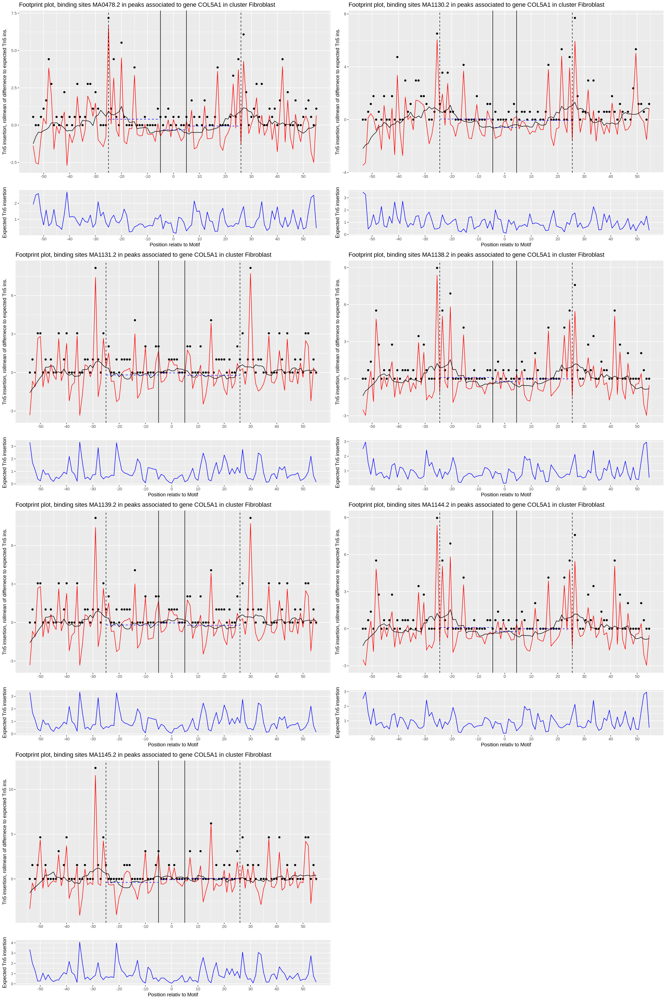

In [110]:
footprint_plots_by_TF(object=object_w_net, gene='COL5A1', cluster="Fibroblast", TF="FOSL2", path=NULL)

In [27]:
p<-footprint_plots_by_TF(object=object_w_net, gene='COL5A1', cluster="Fibroblast", TF="TFE3", path=NULL)
ggsave("objects_AVN_fibroblast/motif_plots/green_motifs/COL5A1_TFE3_motif.png", plot = p, width = 10, height = 10)

TF provided, plotting all motifs for TF



[1] "2026-04-12 11:58:14 CEST"
GRanges object with 4 ranges and 1 metadata column:
      seqnames              ranges strand |     score
         <Rle>           <IRanges>  <Rle> | <numeric>
  [1]     chr9 134502837-134502846      + |   11.8516
  [2]     chr9 134502837-134502846      - |   11.8516
  [3]     chr9 134644838-134644847      + |   16.9537
  [4]     chr9 134644838-134644847      - |   16.9549
  -------
  seqinfo: 24 sequences from an unspecified genome; no seqlengths


Computing base composition at motif sites

Computing expected Tn5 insertions per base



[1] "2026-04-12 11:58:14 CEST"


Finding + strand cut sites

Finding - strand cut sites



[1] 1
[1] "1 1"


TF provided, plotting all motifs for TF



[1] "2026-04-11 13:22:01 CEST"
GRanges object with 4 ranges and 1 metadata column:
      seqnames              ranges strand |     score
         <Rle>           <IRanges>  <Rle> | <numeric>
  [1]     chr9 134502837-134502846      + |   11.8516
  [2]     chr9 134502837-134502846      - |   11.8516
  [3]     chr9 134644838-134644847      + |   16.9537
  [4]     chr9 134644838-134644847      - |   16.9549
  -------
  seqinfo: 24 sequences from an unspecified genome; no seqlengths


Computing base composition at motif sites

Computing expected Tn5 insertions per base



[1] "2026-04-11 13:22:02 CEST"


Finding + strand cut sites

Finding - strand cut sites



[1] 1
[1] "1 1"


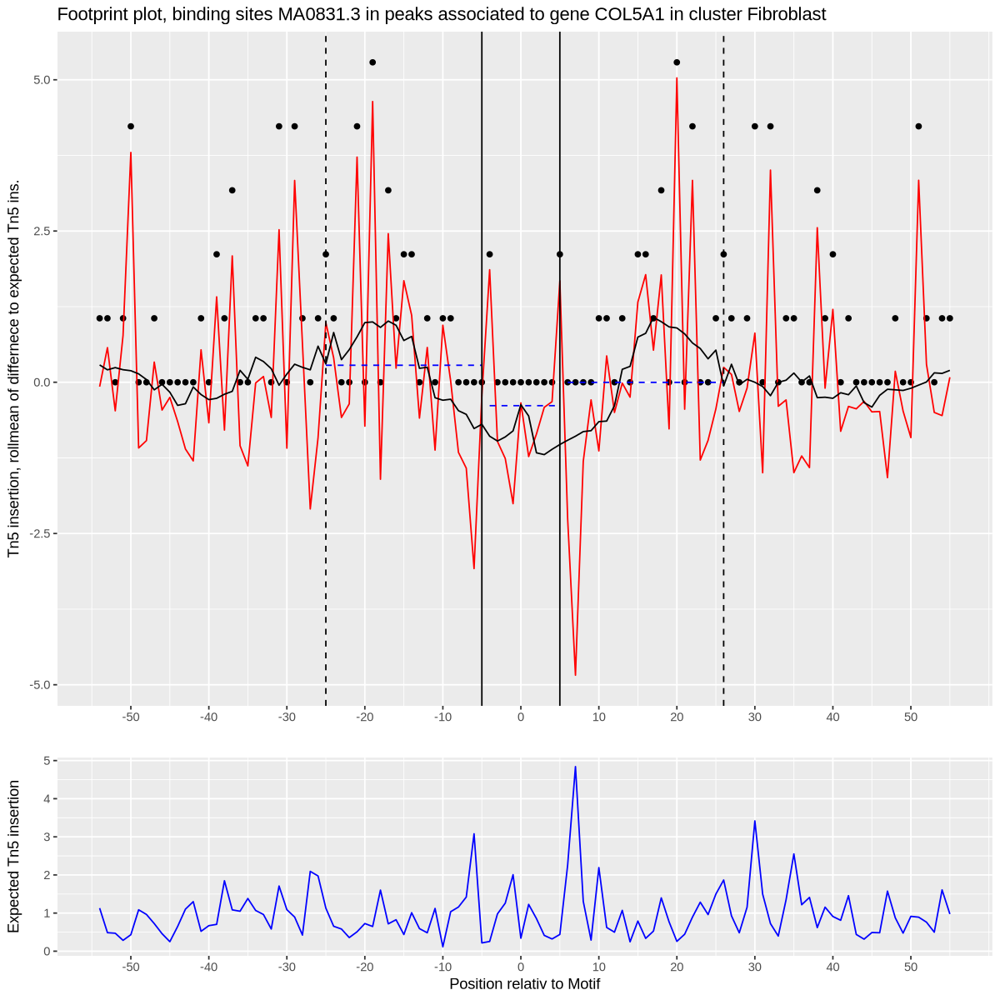

In [96]:
footprint_plots_by_TF(object=object_w_net, gene='COL5A1', cluster="Fibroblast", TF="TFE3", path=NULL)

In [29]:
p<-footprint_plots_by_TF(object=object_w_net, gene='AEBP1', cluster="Fibroblast", TF="RREB1", path=NULL)
ggsave("objects_AVN_fibroblast/motif_plots/green_motifs/AEBP1_RREB1_motif.png", plot = p, width = 10, height = 10)

TF provided, plotting all motifs for TF



[1] "2026-04-12 12:00:07 CEST"
GRanges object with 8 ranges and 1 metadata column:
      seqnames            ranges strand |     score
         <Rle>         <IRanges>  <Rle> | <numeric>
  [1]     chr7 44104056-44104074      + |   11.9148
  [2]     chr7 44104214-44104232      + |   13.3312
  [3]     chr7 44104215-44104233      + |   10.8835
  [4]     chr7 44104218-44104236      + |   12.2317
  [5]     chr7 44104221-44104239      + |   13.3312
  [6]     chr7 44104222-44104240      + |   10.8835
  [7]     chr7 44104229-44104247      + |   11.1822
  [8]     chr7 44104235-44104253      + |   12.4304
  -------
  seqinfo: 24 sequences from an unspecified genome; no seqlengths


Computing base composition at motif sites

Computing expected Tn5 insertions per base



[1] "2026-04-12 12:00:07 CEST"


Finding + strand cut sites

Finding - strand cut sites



[1] 1
[1] "1 1"


TF provided, plotting all motifs for TF



[1] "2026-04-11 13:17:20 CEST"
GRanges object with 8 ranges and 1 metadata column:
      seqnames            ranges strand |     score
         <Rle>         <IRanges>  <Rle> | <numeric>
  [1]     chr7 44104056-44104074      + |   11.9148
  [2]     chr7 44104214-44104232      + |   13.3312
  [3]     chr7 44104215-44104233      + |   10.8835
  [4]     chr7 44104218-44104236      + |   12.2317
  [5]     chr7 44104221-44104239      + |   13.3312
  [6]     chr7 44104222-44104240      + |   10.8835
  [7]     chr7 44104229-44104247      + |   11.1822
  [8]     chr7 44104235-44104253      + |   12.4304
  -------
  seqinfo: 24 sequences from an unspecified genome; no seqlengths


Computing base composition at motif sites

Computing expected Tn5 insertions per base



[1] "2026-04-11 13:17:20 CEST"


Finding + strand cut sites

Finding - strand cut sites



[1] 1
[1] "1 1"


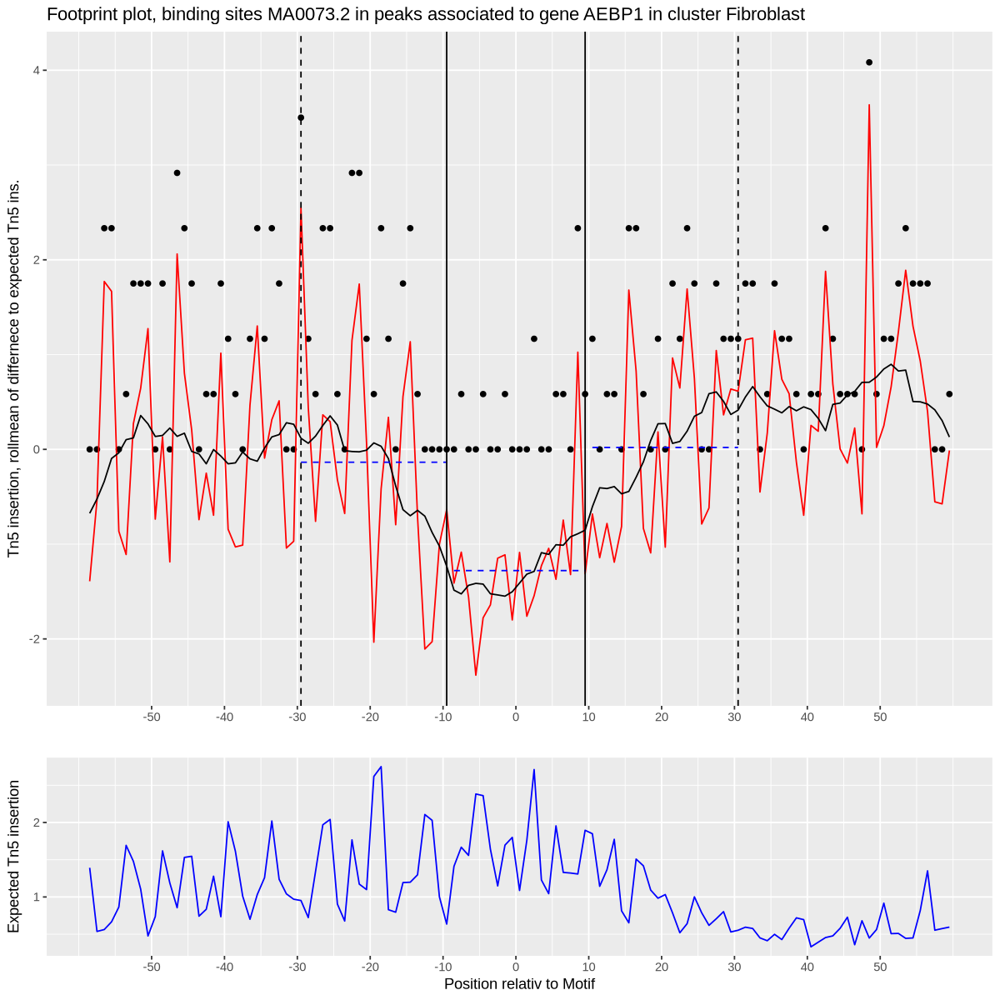

In [73]:
footprint_plots_by_TF(object=object_w_net, gene='AEBP1', cluster="Fibroblast", TF="RREB1", path=NULL)

In [126]:
tmp_green <- object_w_net@misc$seedNetwork$AVN_pathway$BMPR1A[object_w_net@misc$seedNetwork$AVN_pathway$BMPR1A$result=="green",]

In [115]:
colnames(tmp_green)

[1] "gene"                          "cluster"                      
 [3] "proximal.motif_count"          "proximal.background_count"    
 [5] "log2FC.proximal"               "t_stat.proximal"              
 [7] "p_value.proximal"              "p_adjust.proximal"            
 [9] "distal.motif_count"            "distal.background_count"      
[11] "log2FC.distal"                 "t_stat.distal"                
[13] "p_value.distal"                "p_adjust.distal"              
[15] "motif"                         "promoter.motif_count"         
[17] "footprint_score"               "bg_size"                      
[19] "bg_footprint_mean"             "footprint.t_stat"             
[21] "footprint.p_value"             "footprint.p_value_adj"        
[23] "sd.flanks"                     "bg_sd_mean"                   
[25] "left_flank_nonzero_positions"  "right_flank_nonzero_positions"
[27] "promoter.or.enriched"          "TF"                           
[29] "result"                        "priorTF"

In [127]:
tmp_green[c('footprint_score','bg_size','bg_footprint_mean','footprint.t_stat','footprint.p_value','footprint.p_value_adj','sd.flanks','bg_sd_mean','left_flank_nonzero_positions','right_flank_nonzero_positions','promoter.or.enriched')]

,footprint_score,bg_size,bg_footprint_mean,footprint.t_stat,footprint.p_value,footprint.p_value_adj,sd.flanks,bg_sd_mean,left_flank_nonzero_positions,right_flank_nonzero_positions,promoter.or.enriched
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<int>,<lgl>
BMPR1A.SP2,-0.8452,100,-0.60270,5.185,5.725e-07,9.3e-05,1.178,1.397,20,20,TRUE
BMPR1A.NR6A1,-0.7905,100,0.04362,12.540,1.811e-22,2.9e-20,1.911,2.250,17,15,TRUE


In [128]:
head(object_w_net@misc$context_subNetwork$AVN_pathway)

,from,to,color,priorTF,reg_type,in.prom
,<chr>,<chr>,<chr>,<lgl>,<int>,<int>
BMP2.1,KLF15,BMP2,black,TRUE,2,1
BMP2.2,ZFX,BMP2,black,TRUE,2,1
BMP2.3,PURA,BMP2,black,TRUE,2,1
BMPR1A.1,BRCA1,BMPR1A,gray,TRUE,2,1
BMPR1A.2,TET1,BMPR1A,gray,TRUE,2,1
BMPR1A.3,EWSR1-FLI1,BMPR1A,yellow,FALSE,1,1


In [70]:
footprint_plots_by_TF(object=object_w_net, gene='BMP2', cluster="Fibroblast", TF="BMP2", path=NULL)

TF provided, plotting all motifs for TF



[1] "NO MOTIFS FOR KLF15 FOUND IN PEAKS LINKED TO BMP2"

## full net from 3a

In [170]:
full_priorGRN <- read.csv("/nfs/home/students/m.back/swarm/backend/calc_multiome_scores/multiome_tf_regulation/notebooks_pipeline/objects_AVN_fibroblast/gene_tf_relations_AVN_fibroblasts.csv")

[1] "include_motifs_for_seed: TLL1 Fibroblast"
[1] "motif stats for seed:TLL1Fibroblast"
NULL
[1] "motif stats for seed:TLL1Fibroblast"
NULL


found and passed 1 Transcription factors that bind in regulatory regions for seed TLL1 Fibroblast



[1] "NKX2-5"
NULL
[1] 1
[1] "NKX2-5"


No TFs found for seed, as no peak is linked to seed



[1] "include_motifs_for_seed: PLOD1 Fibroblast"
[1] "motif stats for seed:PLOD1Fibroblast"
NULL
[1] "motif stats for seed:PLOD1Fibroblast"
NULL


found and passed 2 Transcription factors that bind in regulatory regions for seed PLOD1 Fibroblast



... (159 outputs left out)

colors are numbers at the end: is this going wrong here already?



 [1] red    red    red    yellow yellow red    red    red    yellow yellow
[11] yellow yellow red    red    red    red    red    red    red    yellow
[21] yellow yellow yellow yellow yellow red    yellow green  red    red   
[31] red    red    red    red    red    red    yellow red    yellow yellow
[41] yellow green  green  yellow yellow yellow yellow yellow yellow yellow
[51] yellow
Levels: green yellow red blue black gray


edge_color at the end of get_subnetwork



 [1] red    red    red    yellow yellow red    red    red    yellow yellow
[11] yellow yellow red    red    red    red    red    red    red    yellow
[21] yellow yellow yellow yellow yellow red    yellow green  red    red   
[31] red    red    red    red    red    red    yellow red    yellow yellow
[41] yellow green  green  yellow yellow yellow yellow yellow yellow yellow
[51] yellow
Levels: green yellow red blue black gray
                   from       to  color priorTF reg_type in.prom
TLL1             NKX2-5     TLL1  black    TRUE        2       1
PLOD1.1          NKX2-5    PLOD1  black    TRUE        2       1
PLOD1.2           PITX2    PLOD1  black    TRUE        2       1
LUM.1              ELF4      LUM   blue    TRUE        2       1
LUM.2              GLI2      LUM   gray    TRUE        2       1
LUM.3              TP53      LUM   blue    TRUE        2       1
LUM.4             FOXG1      LUM    red   FALSE        2       3
LUM.5             TBX20      LUM yellow   FALSE     

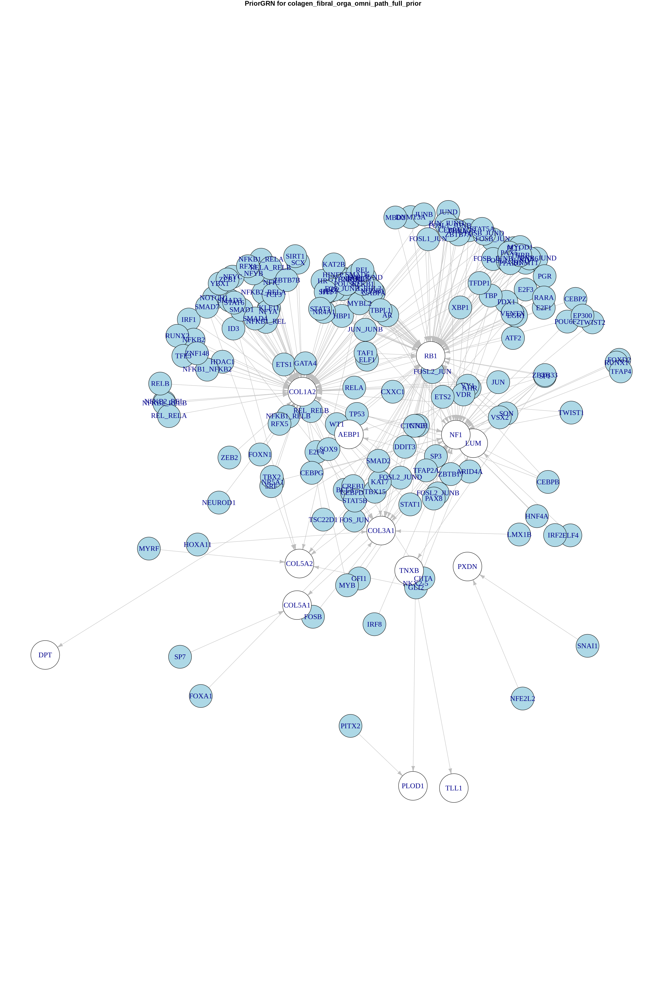

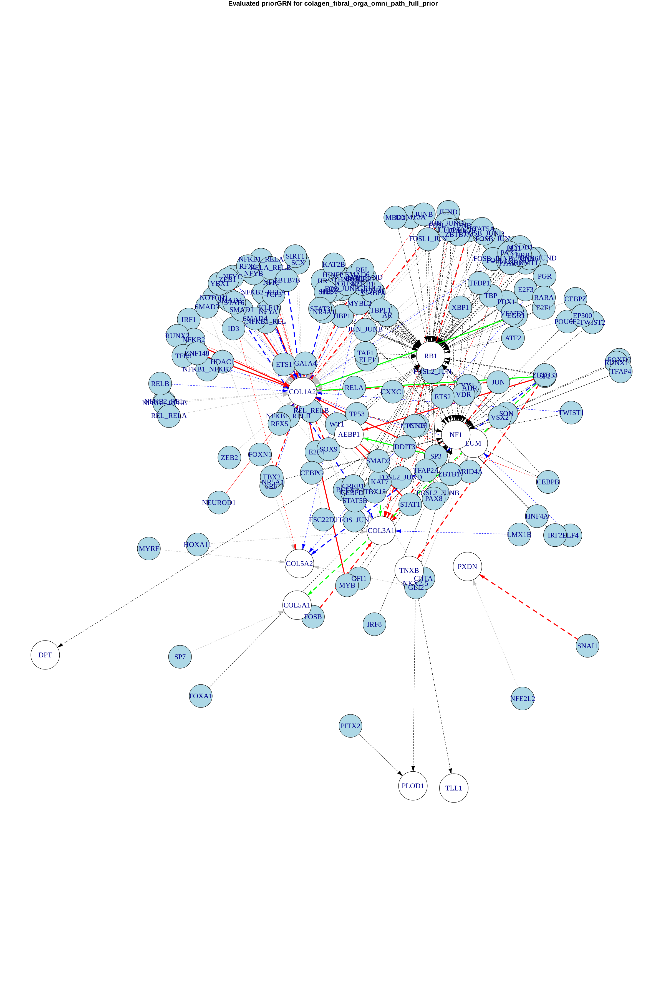

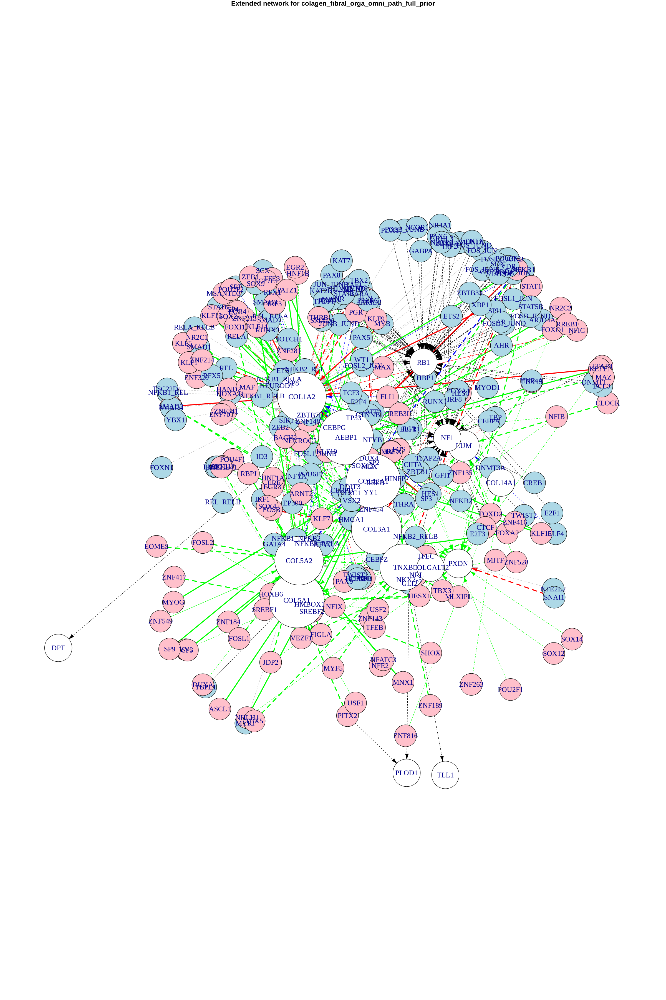

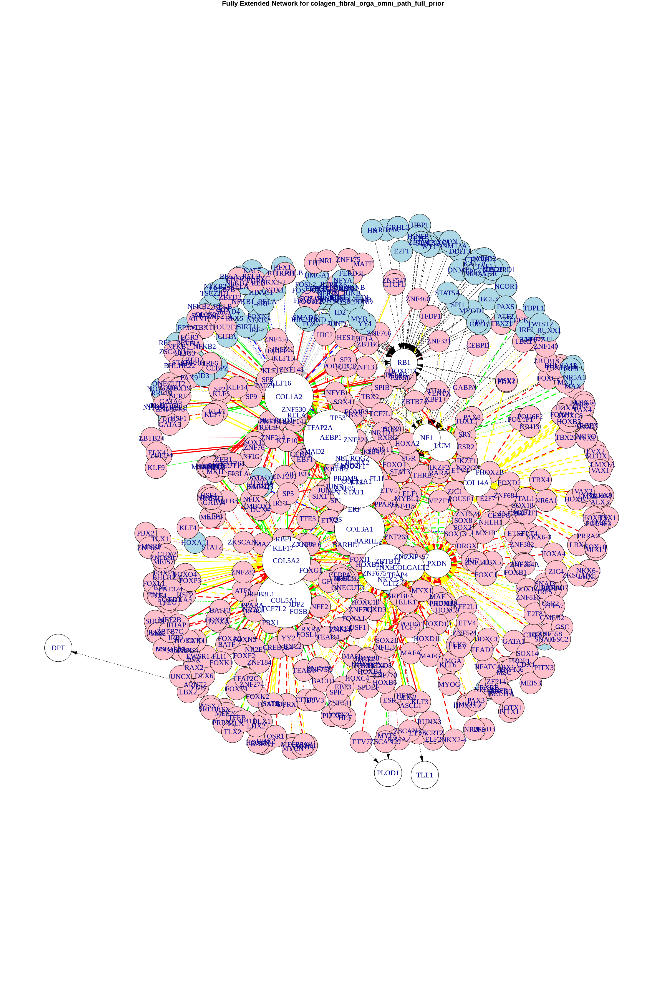

In [171]:

object_w_net<-draw_subNetwork_for_context(object=object_w_net, 
        gene_list= genes_of_interest,
        cluster.specific=TRUE,
        priorGRN=full_priorGRN,
        cluster="Fibroblast",
        context_name='colagen_fibral_orga_omni_path_full_prior',resolution=20,pointsize=50, sd=5, score=-0.5
        )

In [173]:
str(object_w_net@misc, max.level=1)

List of 12
 $ markers.annotated        :'data.frame':	4075 obs. of  8 variables:
 $ peak_stats               :'data.frame':	130 obs. of  51 variables:
 $ peak_stats.filtered      :'data.frame':	122 obs. of  51 variables:
 $ motifs.inProximalPeaks   :List of 23
 $ motifs.inDistalPeaks     :List of 23
 $ motif_enrichment         :'data.frame':	16560 obs. of  16 variables:
 $ filtered.motif_enrichment:'data.frame':	3290 obs. of  16 variables:
 $ motif_stats              :'data.frame':	3290 obs. of  26 variables:
 $ motif2TF                 :List of 720
 $ TF2motif                 :List of 668
 $ seedNetwork              :List of 4
 $ context_subNetwork       :List of 4


In [175]:
object_w_net@misc$context_subNetwork$colagen_fibral_orga_omni_path_full[object_w_net@misc$context_subNetwork$colagen_fibral_orga_omni_path_full$from=="FOSL1",]

,from,to,color,priorTF,reg_type,in.prom
,<chr>,<chr>,<chr>,<lgl>,<int>,<int>
COL5A1.53,FOSL1,COL5A1,yellow,FALSE,2,1
COL5A2.52,FOSL1,COL5A2,green,FALSE,2,3
TNXB.40,FOSL1,TNXB,yellow,FALSE,2,1
COLGALT2.17,FOSL1,COLGALT2,red,FALSE,2,1


TF provided, plotting all motifs for TF



[1] "2026-04-11 16:22:00 CEST"
GRanges object with 6 ranges and 1 metadata column:
      seqnames              ranges strand |     score
         <Rle>           <IRanges>  <Rle> | <numeric>
  [1]     chr2 189076810-189076818      + |   14.3655
  [2]     chr2 189076810-189076818      - |   11.5681
  [3]     chr2 189210374-189210382      + |   13.1625
  [4]     chr2 189210374-189210382      - |   15.5082
  [5]     chr2 189286423-189286431      + |   11.5681
  [6]     chr2 189286423-189286431      - |   14.3655
  -------
  seqinfo: 24 sequences from an unspecified genome; no seqlengths


Computing base composition at motif sites

Computing expected Tn5 insertions per base



[1] "2026-04-11 16:22:00 CEST"


Finding + strand cut sites

Finding - strand cut sites



[1] "2026-04-11 16:22:01 CEST"
GRanges object with 3 ranges and 1 metadata column:
      seqnames              ranges strand |     score
         <Rle>           <IRanges>  <Rle> | <numeric>
  [1]     chr2 189076810-189076818      + |   14.2668
  [2]     chr2 189210374-189210382      - |   15.0808
  [3]     chr2 189286423-189286431      - |   14.2668
  -------
  seqinfo: 24 sequences from an unspecified genome; no seqlengths


... (8 outputs left out)

Computing base composition at motif sites

Computing expected Tn5 insertions per base



[1] "2026-04-11 16:22:03 CEST"


Finding + strand cut sites

Finding - strand cut sites



[1] 4
[1] "2 2"


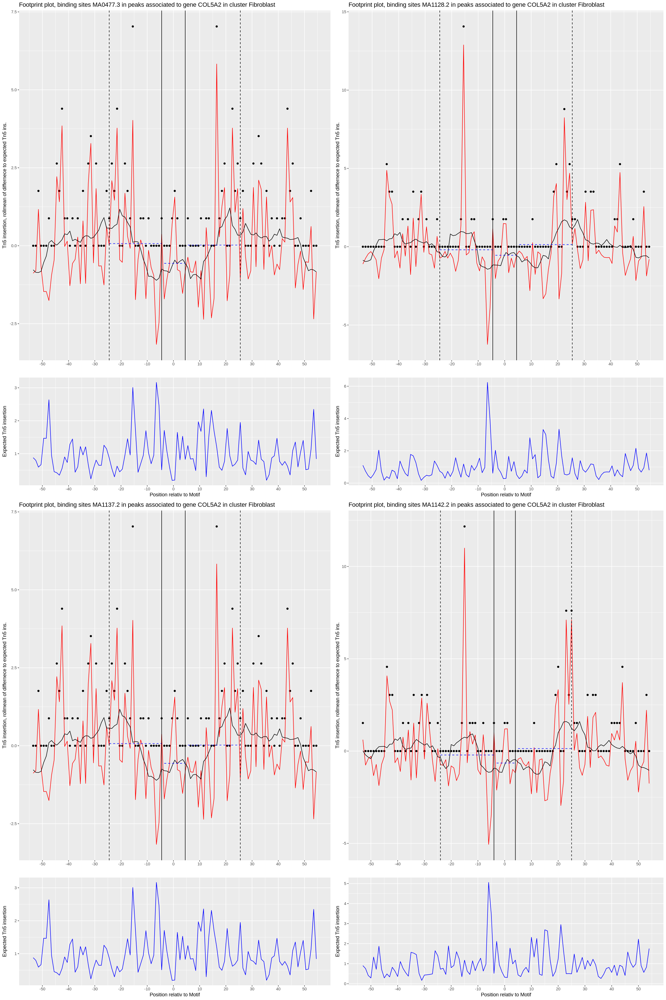

In [176]:
footprint_plots_by_TF(object=object_w_net, gene='COL5A2', cluster="Fibroblast", TF="FOSL1", path=NULL)

In [2]:
object_w_net = readRDS("objects_AVN_fibroblast/final_object_w_net.rds")

In [5]:
full_priorGRN <- read.csv("/nfs/home/students/m.back/swarm/backend/calc_multiome_scores/multiome_tf_regulation/notebooks_pipeline/objects_AVN_fibroblast/gene_tf_relations_AVN_fibroblasts.csv")
genes_of_interest<-unique(union(full_priorGRN$gene, intersect(seed_genes, object_w_net@misc$markers.annotated[object_w_net@misc$markers.annotated$annotation=="marker.pos.Fibroblast",]$gene)))


In [22]:
genes_of_interest

[1] "ADAMTS7"  "AEBP1"    "ANXA2"    "ATP7A"    "BMP1"     "COL11A1" 
 [7] "COL11A2"  "COL1A1"   "COL1A2"   "COL2A1"   "COL3A1"   "COL4A1"  
[13] "COL4A2"   "COL4A3"   "COL4A4"   "COL5A1"   "COL5A2"   "COL5A3"  
[19] "COL6A1"   "COL7A1"   "COMP"     "CYP1B1"   "DDR2"     "DPT"     
[25] "EFEMP2"   "ERO1A"    "EXT1"     "FMOD"     "FOXC1"    "FOXC2"   
[31] "GREM1"    "LOX"      "LOXL2"    "LOXL4"    "LUM"      "MMP11"   
[37] "NF1"      "P3H4"     "P4HA1"    "PLOD1"    "PLOD2"    "PXDN"    
[43] "RB1"      "SCX"      "SERPINF2" "SERPINH1" "SFRP2"    "TGFB2"   
[49] "TGFBR1"   "TLL1"     "TNXB"     "VPS33B"   "COL12A1"  "COL14A1" 
[55] "COLGALT2"

In [6]:
str(object_w_net@misc$context_subNetwork, max.level=1)

List of 4
 $ colagen_fibral_orga                     :'data.frame':	935 obs. of  6 variables:
 $ colagen_fibral_orga_omni_path           :'data.frame':	927 obs. of  6 variables:
 $ colagen_fibral_orga_omni_path_cl_unsp   :'data.frame':	927 obs. of  6 variables:
 $ colagen_fibral_orga_omni_path_full_prior:'data.frame':	1138 obs. of  6 variables:


In [8]:
options(repr.plot.width=40, repr.plot.height=40)

[1] "include_motifs_for_seed: ADAMTS7 Fibroblast"
[1] "motif stats for seed:ADAMTS7Fibroblast"
NULL
[1] "motif stats for seed:ADAMTS7Fibroblast"
NULL


found and passed 5 Transcription factors that bind in regulatory regions for seed ADAMTS7 Fibroblast



[1] "HR"
[1] "HTATIP2"
[1] "SSRP1"
[1] "TFAP2A"
[1] "ZBTB16"
NULL
[1] 5
[1] "HR"      "HTATIP2" "SSRP1"   "TFAP2A"  "ZBTB16" 


No TFs found for seed, as no peak is linked to seed



[1] "include_motifs_for_seed: AEBP1 Fibroblast"
[1] "motif stats for seed:AEBP1Fibroblast"
[1] 124  26
[1] "motif stats for seed:AEBP1Fibroblast"
[1] 67 26


found and passed 70 Transcription factors that bind in regulatory regions for seed AEBP1 Fibroblast



... (469 outputs left out)

colors are numbers at the end: is this going wrong here already?



 [1] red    red    red    yellow yellow red    red    red    yellow yellow
[11] yellow yellow red    red    red    red    red    red    red    yellow
[21] yellow yellow yellow yellow yellow red    yellow green  red    red   
[31] red    red    red    red    red    red    yellow red    yellow yellow
[41] yellow green  green  yellow yellow yellow yellow yellow yellow yellow
[51] yellow
Levels: green yellow red blue black gray


edge_color at the end of get_subnetwork



 [1] red    red    red    yellow yellow red    red    red    yellow yellow
[11] yellow yellow red    red    red    red    red    red    red    yellow
[21] yellow yellow yellow yellow yellow red    yellow green  red    red   
[31] red    red    red    red    red    red    yellow red    yellow yellow
[41] yellow green  green  yellow yellow yellow yellow yellow yellow yellow
[51] yellow
Levels: green yellow red blue black gray
                   from       to  color priorTF reg_type in.prom
ADAMTS7.1            HR  ADAMTS7  black    TRUE        2       1
ADAMTS7.2       HTATIP2  ADAMTS7  black    TRUE        2       1
ADAMTS7.3         SSRP1  ADAMTS7  black    TRUE        2       1
ADAMTS7.4        TFAP2A  ADAMTS7  black    TRUE        2       1
ADAMTS7.5        ZBTB16  ADAMTS7  black    TRUE        2       1
AEBP1.1             SP1    AEBP1    red    TRUE        1       3
AEBP1.2             SP3    AEBP1  green    TRUE        1       3
AEBP1.3           INSM1    AEBP1    red   FALSE     

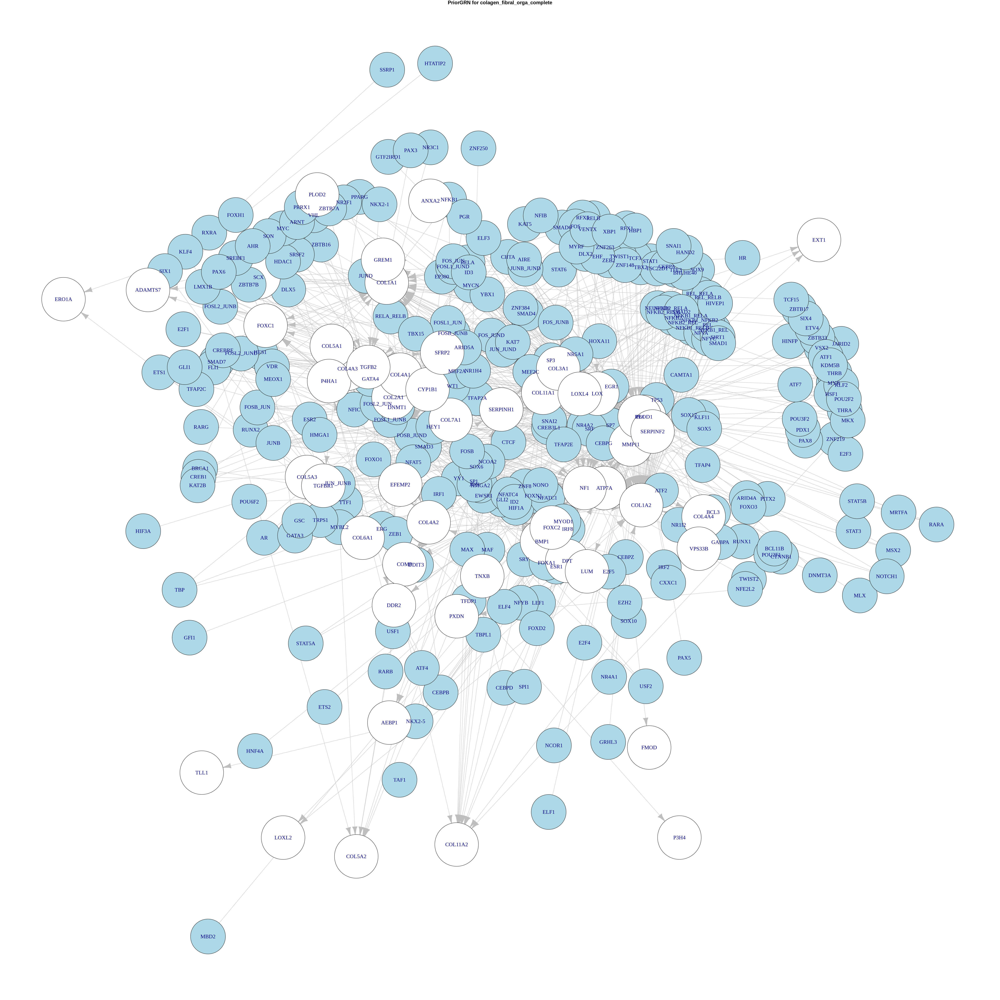

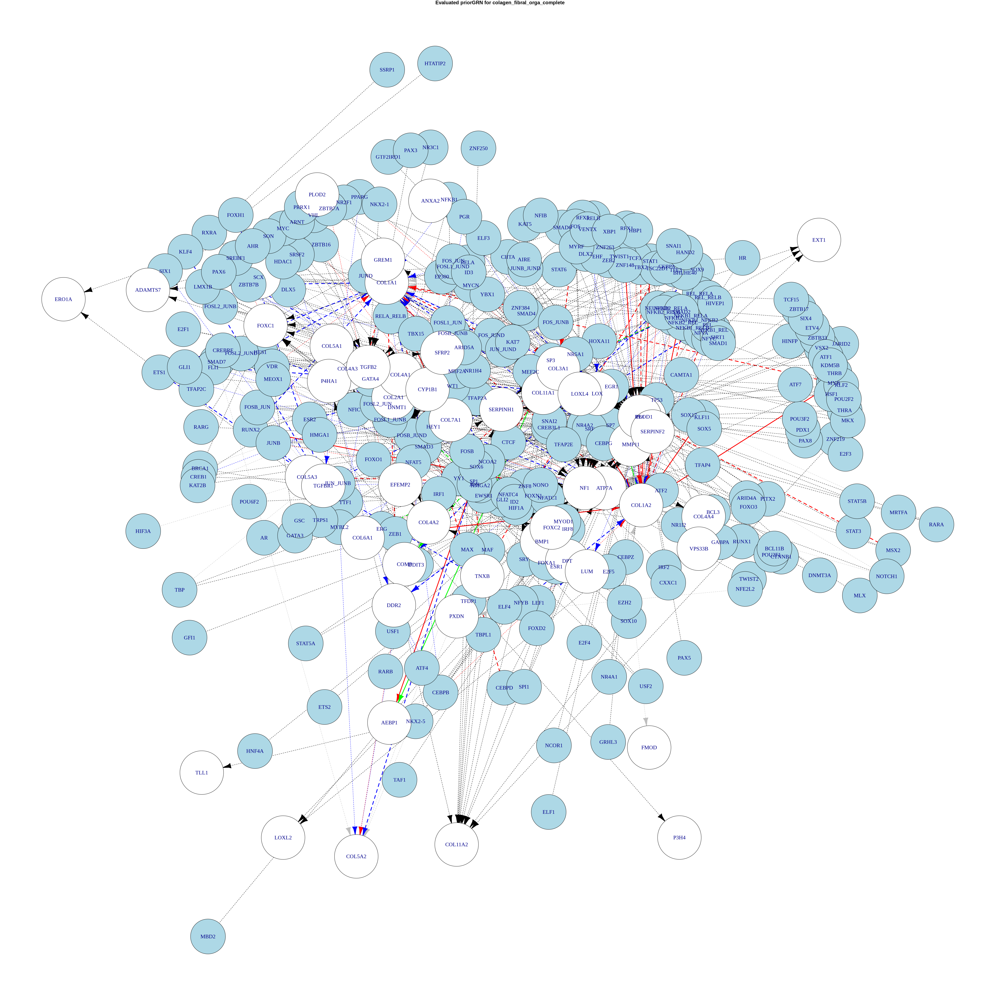

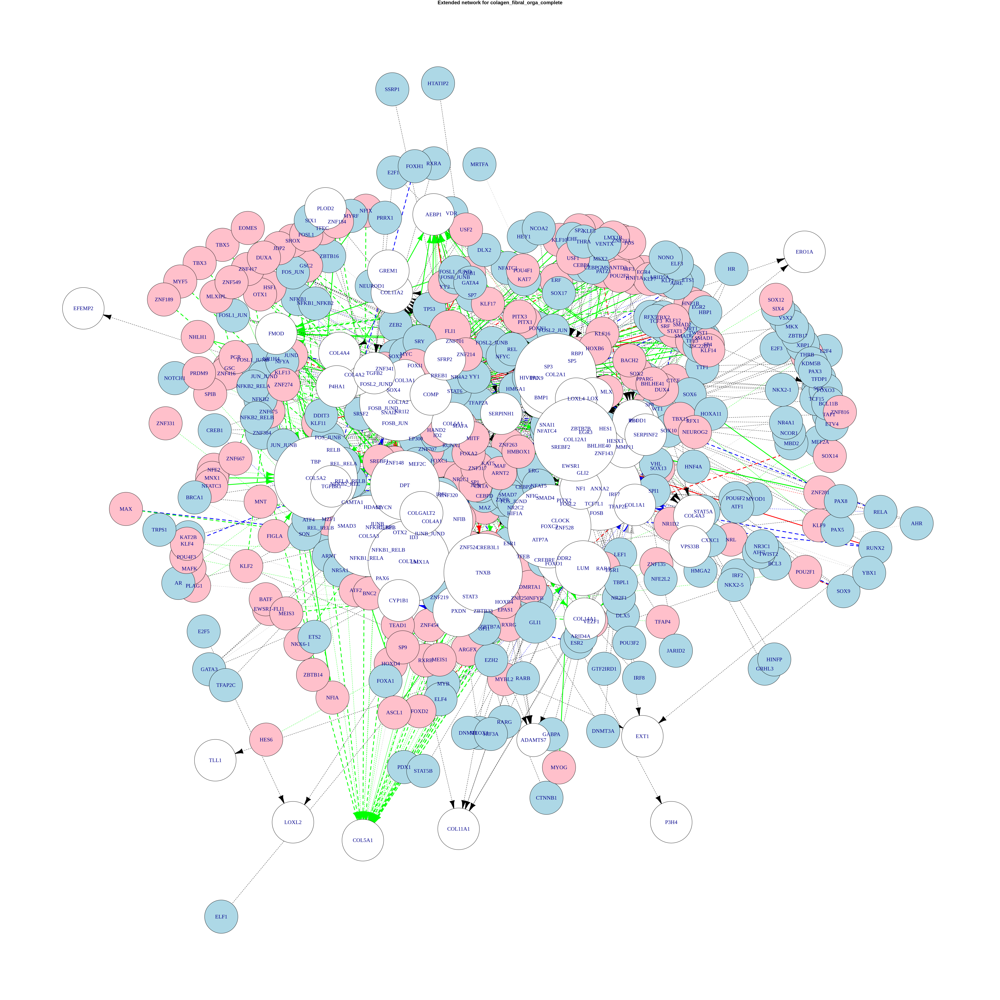

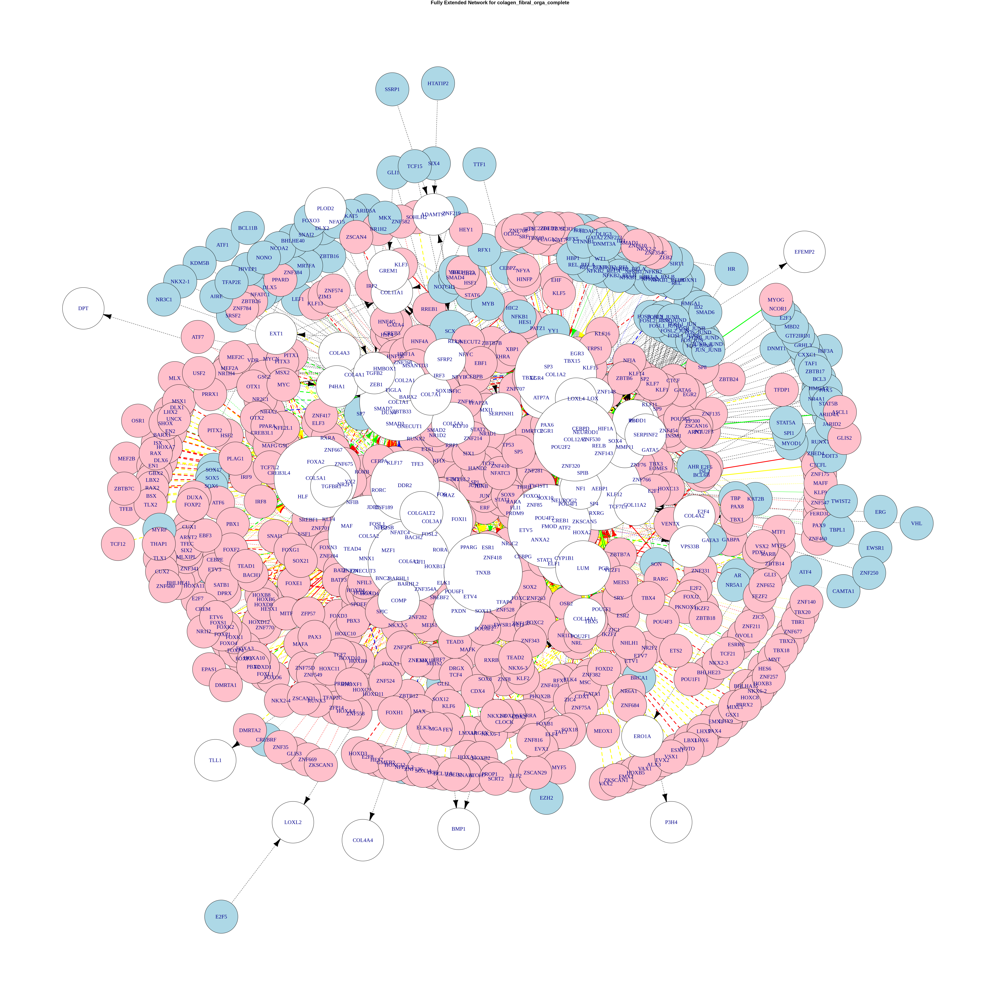

In [9]:

object_w_net<-draw_subNetwork_for_context(object=object_w_net, 
        gene_list= genes_of_interest,
        cluster.specific=TRUE,
        priorGRN=full_priorGRN,
        cluster="Fibroblast",
        context_name='colagen_fibral_orga_complete',resolution=20,pointsize=50, sd=5, score=-0.5
        )

In [13]:
object_w_net@misc$context_subNetwork$colagen_fibral_orga_complete[object_w_net@misc$context_subNetwork$colagen_fibral_orga_complete$to=="COL1A1" &
object_w_net@misc$context_subNetwork$colagen_fibral_orga_complete$priorTF=="TRUE" &
object_w_net@misc$context_subNetwork$colagen_fibral_orga_complete$color=="red"
,]

,from,to,color,priorTF,reg_type,in.prom
,<chr>,<chr>,<chr>,<lgl>,<int>,<int>
COL1A1.2,CEBPD,COL1A1,red,TRUE,2,3
COL1A1.4,CREB3L1,COL1A1,red,TRUE,2,1
COL1A1.10,MEF2A,COL1A1,red,TRUE,2,3
COL1A1.12,MSX2,COL1A1,red,TRUE,2,3
COL1A1.13,MYB,COL1A1,red,TRUE,2,3
COL1A1.17,NFIC,COL1A1,red,TRUE,2,3
COL1A1.28,SP1,COL1A1,red,TRUE,1,3
COL1A1.34,VDR,COL1A1,red,TRUE,2,1
COL1A1.39,ZEB1,COL1A1,red,TRUE,2,3


In [17]:
object_w_net@misc$seedNetwork$colagen_fibral_orga_complete$COL1A1[
    object_w_net@misc$seedNetwork$colagen_fibral_orga_complete$COL1A1$TF=="CREB3L1",
    ]

,gene,cluster,proximal.motif_count,proximal.background_count,log2FC.proximal,t_stat.proximal,p_value.proximal,p_adjust.proximal,distal.motif_count,distal.background_count,⋯,footprint.p_value,footprint.p_value_adj,sd.flanks,bg_sd_mean,left_flank_nonzero_positions,right_flank_nonzero_positions,promoter.or.enriched,TF,result,priorTF
,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<int>,<lgl>,<chr>,<chr>,<lgl>
COL1A1.CREB3L1,COL1A1,Fibroblast,0,0.06,-Inf,1.768519,0.9584005,1,1,0.12,⋯,0.9987,1,1.993,5.635,8,6,TRUE,CREB3L1,red,TRUE


TF provided, plotting all motifs for TF



[1] "2026-04-11 20:04:10 CEST"
GRanges object with 1 range and 1 metadata column:
      seqnames            ranges strand |     score
         <Rle>         <IRanges>  <Rle> | <numeric>
  [1]    chr17 50209878-50209890      + |   12.1018
  -------
  seqinfo: 24 sequences from an unspecified genome; no seqlengths


Computing base composition at motif sites

Computing expected Tn5 insertions per base



[1] "2026-04-11 20:04:10 CEST"


Finding + strand cut sites

Finding - strand cut sites



[1] 1
[1] "1 1"


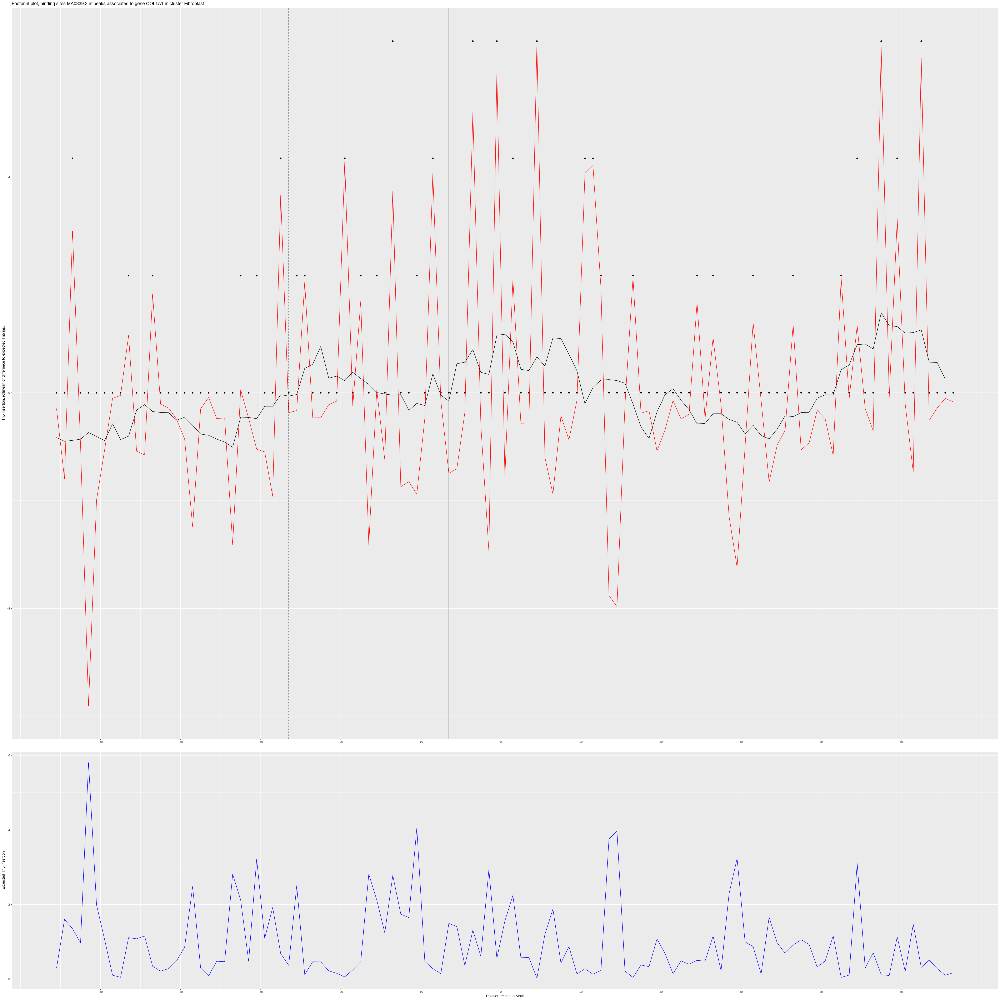

In [ ]:
#red
footprint_plots_by_TF(object=object_w_net, gene='COL1A1', cluster="Fibroblast", TF="CREB3L1", path=NULL)